# 02 - Analyse exploratoire des données

## Introduction

Le Notebook 01 a permis de comprendre la structure, la qualité et les principales contraintes du dataset PaySim.

Cette seconde étape vise à aller au-delà de la description générale des données afin d’identifier les comportements transactionnels susceptibles de différencier les opérations frauduleuses des transactions légitimes.

Dans un projet de détection de fraude Mobile Money, l’analyse exploratoire permet notamment de :

- détecter les comportements inhabituels ;
- identifier les variables potentiellement discriminantes ;
- comprendre les mécanismes associés aux transactions frauduleuses ;
- préparer les futures variables du Feature Engineering ;
- justifier la construction d’un graphe transactionnel ;
- orienter les modèles de Machine Learning et de Graph Learning dynamique.

## Questions métier

Cette analyse cherchera à répondre aux questions suivantes :

1. Les transactions frauduleuses présentent-elles des caractéristiques particulières ?
2. Quels types d’opérations sont les plus exposés à la fraude ?
3. Les fraudes suivent-elles des comportements temporels spécifiques ?
4. Les montants frauduleux diffèrent-ils des montants légitimes ?
5. Les relations entre les comptes permettent-elles d’identifier des structures suspectes ?

## Approche méthodologique

Chaque analyse suivra la démarche suivante :

- formulation d’une question métier ;
- calcul des statistiques nécessaires ;
- visualisation des résultats ;
- interprétation métier ;
- identification des impacts sur le Feature Engineering ;
- identification des impacts sur les modèles de Machine Learning ;
- identification des impacts sur le Graph Learning ;
- décision méthodologique.

In [351]:
# Importer les bibliothèques
from pathlib import Path
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import Markdown, display
from scipy.stats import mannwhitneyu

# Masquer les avertissements
warnings.filterwarnings("ignore")

# Configurer pandas
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

# Configurer les graphiques
sns.set_theme(
    style="whitegrid",
    context="notebook"
)

# Définir les couleurs
COLORS = {
    "primary": "#2563EB",
    "secondary": "#0F766E",
    "fraud": "#DC2626",
    "legitimate": "#16A34A",
    "warning": "#F59E0B",
    "neutral": "#64748B",
}

# Définir la graine aléatoire
RANDOM_STATE = 42

print("Environnement initialisé avec succès.")

Environnement initialisé avec succès.


In [352]:
# Définir le dossier courant
current_dir = Path.cwd()

# Déterminer la racine du projet
if current_dir.name.lower() == "notebooks":
    project_root = current_dir.parent
else:
    project_root = current_dir

# Définir le dossier des données
raw_dir = project_root / "data" / "raw"

# Rechercher les fichiers CSV
csv_files = sorted(raw_dir.glob("*.csv"))

# Vérifier la présence du dataset
if len(csv_files) == 0:
    raise FileNotFoundError(
        "Aucun fichier CSV trouvé dans le dossier data/raw."
    )

# Afficher les fichiers trouvés
if len(csv_files) > 1:
    print("Plusieurs fichiers CSV ont été trouvés :")

    for index, file in enumerate(csv_files, start=1):
        print(f"{index}. {file.name}")

    print("\nLe premier fichier sera utilisé.")

# Sélectionner le dataset
data_path = csv_files[0]

# Charger le dataset
df = pd.read_csv(data_path)

# Afficher les informations principales
print(f"Fichier chargé : {data_path.name}")
print(f"Nombre de lignes : {df.shape[0]:,}")
print(f"Nombre de colonnes : {df.shape[1]}")

display(df.head())

Fichier chargé : paysim.csv
Nombre de lignes : 6,362,620
Nombre de colonnes : 11


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.64",C1231006815,"170,136.00","160,296.36",M1979787155,0.00,0.00,0,0
1,1,PAYMENT,"1,864.28",C1666544295,"21,249.00","19,384.72",M2044282225,0.00,0.00,0,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,"21,182.00",0.00,1,0
4,1,PAYMENT,"11,668.14",C2048537720,"41,554.00","29,885.86",M1230701703,0.00,0.00,0,0


In [353]:
# Vérifier les colonnes nécessaires
required_columns = [
    "step",
    "type",
    "amount",
    "nameOrig",
    "oldbalanceOrg",
    "newbalanceOrig",
    "nameDest",
    "oldbalanceDest",
    "newbalanceDest",
    "isFraud",
    "isFlaggedFraud",
]

# Identifier les colonnes absentes
missing_columns = [
    column
    for column in required_columns
    if column not in df.columns
]

# Afficher le résultat
if missing_columns:
    print("Colonnes absentes :", missing_columns)
else:
    print("Toutes les colonnes nécessaires sont présentes.")

Toutes les colonnes nécessaires sont présentes.


In [354]:
# Définir le dossier des figures
figures_dir = (
    project_root
    / "reports"
    / "figures"
    / "eda"
)

# Définir le dossier des tableaux
tables_dir = (
    project_root
    / "reports"
    / "tables"
    / "eda"
)

# Créer les dossiers
figures_dir.mkdir(
    parents=True,
    exist_ok=True
)

tables_dir.mkdir(
    parents=True,
    exist_ok=True
)

print(f"Dossier des figures : {figures_dir}")
print(f"Dossier des tableaux : {tables_dir}")

Dossier des figures : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda
Dossier des tableaux : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\tables\eda


In [355]:
# Créer une fonction de sauvegarde
def save_figure(filename, dpi=300):
    """Enregistrer la figure active."""

    output_path = figures_dir / filename

    plt.savefig(
        output_path,
        dpi=dpi,
        bbox_inches="tight",
    )

    print(f"Figure enregistrée : {output_path}")

## Analyse de la variable cible

### Question métier

La fraude représente-t-elle un phénomène suffisamment rare pour nécessiter une stratégie particulière de modélisation et d’évaluation ?

Cette section fournit uniquement une synthèse opérationnelle de la cible afin de préparer les comparaisons de l’EDA. La description générale de la variable a déjà été réalisée dans le Notebook 01.

In [356]:

# Calculer les effectifs
fraud_counts = (
    df["isFraud"]
    .value_counts()
    .sort_index()
)

# Calculer les pourcentages
fraud_percentages = (
    df["isFraud"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

# Construire le tableau
fraud_summary = pd.DataFrame(
    {
        "Nombre": fraud_counts,
        "Pourcentage (%)": fraud_percentages,
    }
)

# Renommer les classes
fraud_summary.index = [
    "Légitime",
    "Fraude",
]

# Afficher le tableau
display(fraud_summary)

,Nombre,Pourcentage (%)
Légitime,6354407,99.87
Fraude,8213,0.13


In [357]:
# Calculer le nombre de transactions légitimes
n_legitimate = int(
    (df["isFraud"] == 0).sum()
)

# Calculer le nombre de fraudes
n_fraud = int(
    (df["isFraud"] == 1).sum()
)

# Calculer le taux de fraude
fraud_rate = (
    n_fraud
    / len(df)
    * 100
)

# Calculer le ratio de déséquilibre
imbalance_ratio = (
    n_legitimate
    / n_fraud
    if n_fraud > 0
    else np.inf
)

# Afficher les résultats
print(f"Transactions légitimes : {n_legitimate:,}")
print(f"Transactions frauduleuses : {n_fraud:,}")
print(f"Taux de fraude : {fraud_rate:.6f} %")
print(
    "Ratio : "
    f"{imbalance_ratio:,.2f} transactions légitimes "
    "pour une fraude"
)

Transactions légitimes : 6,354,407
Transactions frauduleuses : 8,213
Taux de fraude : 0.129082 %
Ratio : 773.70 transactions légitimes pour une fraude


Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\01_distribution_isFraud.png


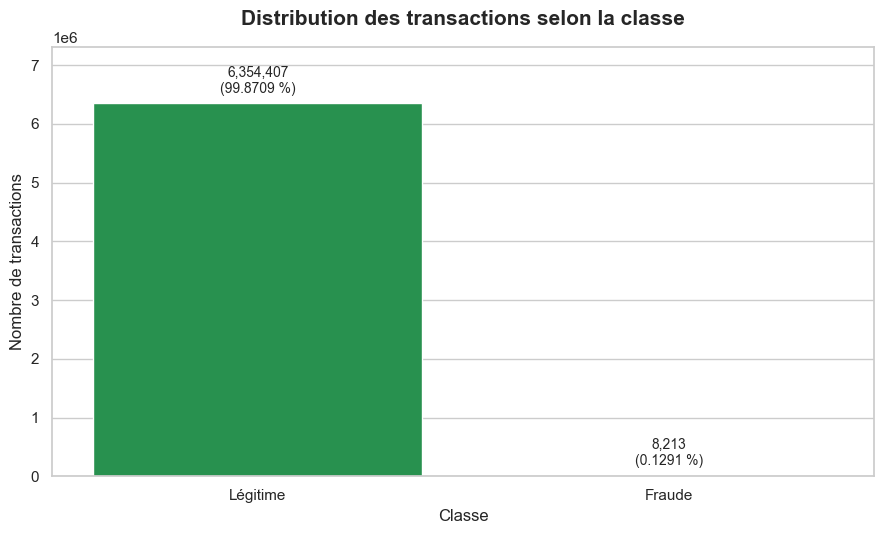

In [358]:
# Préparer les données
fraud_plot = fraud_summary.reset_index()

fraud_plot.columns = [
    "Classe",
    "Nombre",
    "Pourcentage (%)",
]

# Créer le graphique
fig, ax = plt.subplots(
    figsize=(9, 5.5)
)

sns.barplot(
    data=fraud_plot,
    x="Classe",
    y="Nombre",
    hue="Classe",
    palette={
        "Légitime": COLORS["legitimate"],
        "Fraude": COLORS["fraud"],
    },
    legend=False,
    ax=ax,
)

# Ajouter le titre
ax.set_title(
    "Distribution des transactions selon la classe",
    fontsize=15,
    fontweight="bold",
    pad=16,
)

# Configurer les axes
ax.set_xlabel("Classe")
ax.set_ylabel("Nombre de transactions")

# Ajouter une marge
ax.set_ylim(
    0,
    fraud_plot["Nombre"].max() * 1.15,
)

# Ajouter les annotations
for index, row in fraud_plot.iterrows():
    ax.text(
        index,
        row["Nombre"]
        + fraud_plot["Nombre"].max() * 0.02,
        (
            f'{row["Nombre"]:,.0f}\n'
            f'({row["Pourcentage (%)"]:.4f} %)'
        ),
        ha="center",
        va="bottom",
        fontsize=10,
    )

# Finaliser le graphique
plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "01_distribution_isFraud.png"
)

plt.show()

Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\02_distribution_isFraud_log.png


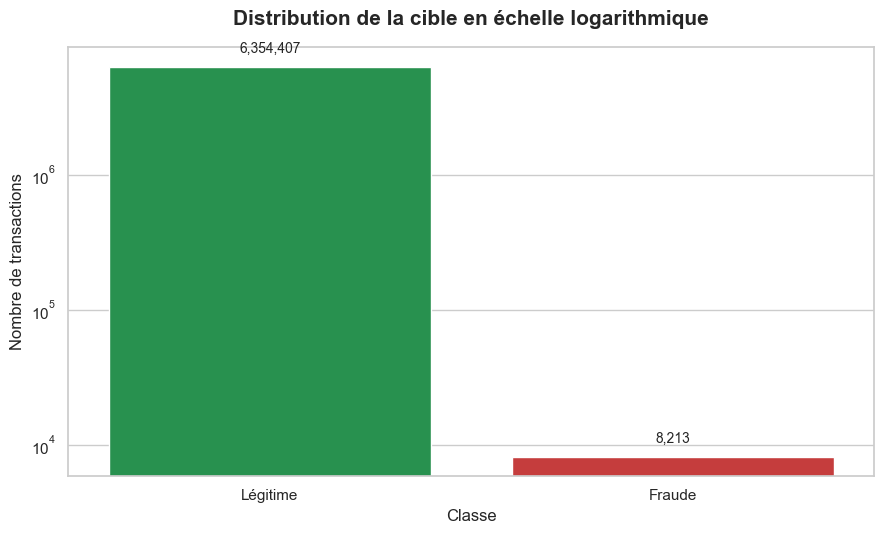

In [359]:
# Créer le graphique
fig, ax = plt.subplots(
    figsize=(9, 5.5)
)

sns.barplot(
    data=fraud_plot,
    x="Classe",
    y="Nombre",
    hue="Classe",
    palette={
        "Légitime": COLORS["legitimate"],
        "Fraude": COLORS["fraud"],
    },
    legend=False,
    ax=ax,
)

# Appliquer une échelle logarithmique
ax.set_yscale("log")

# Ajouter le titre
ax.set_title(
    "Distribution de la cible en échelle logarithmique",
    fontsize=15,
    fontweight="bold",
    pad=16,
)

# Configurer les axes
ax.set_xlabel("Classe")
ax.set_ylabel(
    "Nombre de transactions"
)

# Ajouter les effectifs
for index, row in fraud_plot.iterrows():
    ax.text(
        index,
        row["Nombre"] * 1.20,
        f'{row["Nombre"]:,.0f}',
        ha="center",
        va="bottom",
        fontsize=10,
    )

# Finaliser le graphique
plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "02_distribution_isFraud_log.png"
)

plt.show()

In [360]:
# Calculer la distribution
flagged_summary = pd.DataFrame(
    {
        "Nombre": (
            df["isFlaggedFraud"]
            .value_counts()
            .sort_index()
        ),
        "Pourcentage (%)": (
            df["isFlaggedFraud"]
            .value_counts(normalize=True)
            .sort_index()
            .mul(100)
            .round(6)
        ),
    }
)

# Renommer les classes
flagged_summary.index = [
    "Non signalée",
    "Signalée",
]

# Afficher le tableau
display(flagged_summary)

,Nombre,Pourcentage (%)
Non signalée,6362604,100.00
Signalée,16,0.00


In [361]:
# Créer la table de comparaison
flagged_cross_table = pd.crosstab(
    df["isFlaggedFraud"],
    df["isFraud"],
    rownames=["Signalement"],
    colnames=["Fraude réelle"],
    margins=True,
)

# Afficher la table
display(flagged_cross_table)

Fraude réelle,0,1,All
Signalement,,,
0,6354407,8197,6362604
1,0,16,16
All,6354407,8213,6362620


In [362]:
# Calculer les transactions signalées
n_flagged = int(
    (df["isFlaggedFraud"] == 1).sum()
)

# Calculer les fraudes signalées
n_flagged_fraud = int(
    (
        (df["isFlaggedFraud"] == 1)
        & (df["isFraud"] == 1)
    ).sum()
)

# Calculer le rappel de la règle
rule_recall = (
    n_flagged_fraud
    / n_fraud
    if n_fraud > 0
    else 0
)

# Calculer la précision de la règle
rule_precision = (
    n_flagged_fraud
    / n_flagged
    if n_flagged > 0
    else 0
)

# Afficher les résultats
print(f"Transactions signalées : {n_flagged:,}")
print(f"Fraudes signalées : {n_flagged_fraud:,}")
print(f"Précision de la règle : {rule_precision:.4%}")
print(f"Rappel de la règle : {rule_recall:.4%}")

Transactions signalées : 16
Fraudes signalées : 16
Précision de la règle : 100.0000%
Rappel de la règle : 0.1948%


### Observation

Le dataset contient 6 362 620 transactions, dont 8 213 transactions
frauduleuses. La fraude représente seulement 0,1291 % des opérations.

Il existe environ 774 transactions légitimes pour une seule transaction
frauduleuse.

La règle existante `isFlaggedFraud` a signalé uniquement 16 transactions.
Ces 16 transactions sont toutes frauduleuses, mais 8 197 fraudes n'ont pas
été signalées.

### Interprétation métier

La détection de fraude constitue un problème de classification extrêmement
déséquilibré. Un modèle prédisant toutes les transactions comme légitimes
obtiendrait une accuracy proche de 99,87 %, tout en ne détectant aucune
fraude.

La règle `isFlaggedFraud` présente une précision de 100 %, car toutes les
transactions signalées sont réellement frauduleuses. En revanche, son rappel
est seulement de 0,1948 %. Elle détecte donc une très faible partie des fraudes.

Cette règle semble conçue pour identifier uniquement des situations très
spécifiques avec un niveau de certitude élevé. Elle ne constitue pas une
solution suffisante pour une détection globale de la fraude.

### Impact sur le Feature Engineering

Les futures variables devront mettre en évidence des comportements que la
règle actuelle ne détecte pas :

- montant inhabituel ;
- vidage complet du compte ;
- fréquence élevée des transactions ;
- répétition des transferts ;
- nombre de destinataires différents ;
- rapidité des transactions ;
- activité anormale du compte ;
- concentration des flux vers certaines destinations.

### Impact sur les modèles Machine Learning

L'accuracy ne devra pas être utilisée seule pour évaluer les modèles.

Les métriques prioritaires seront :

- le rappel de la classe fraude ;
- la précision ;
- le F1-score ;
- la PR-AUC ;
- la ROC-AUC ;
- la matrice de confusion ;
- le coût des faux négatifs et des faux positifs.

Des stratégies comme la pondération des classes, l'ajustement du seuil de
décision et le rééchantillonnage contrôlé seront étudiées.

### Impact sur les Graph Neural Networks

Les GNN devront exploiter les relations entre les comptes afin de détecter
des fraudes qui ne sont pas identifiables par une règle fondée uniquement
sur une transaction isolée.

Les informations relationnelles pourront inclure :

- les comptes connectés ;
- la fréquence des interactions ;
- les destinations communes ;
- les motifs de voisinage ;
- la succession temporelle des transferts ;
- les réseaux de comptes suspects.

### Décision retenue

- `isFlaggedFraud` ne sera pas utilisée comme variable principale du modèle.
- Elle servira de baseline métier pour comparer les performances.
- L'évaluation accordera une importance particulière au rappel des fraudes.
- Les techniques de rééquilibrage seront appliquées uniquement aux données
  d'entraînement.
- La séparation des ensembles sera chronologique afin d'éviter les fuites
  temporelles.

# 3. Analyse univariée des variables numériques

## Question métier

Les transactions frauduleuses présentent-elles des caractéristiques numériques différentes des transactions légitimes ?

Cette section étudie les montants, les soldes des comptes et la position temporelle des transactions.

L’objectif est d’identifier :

- les variables dont les distributions diffèrent selon la classe ;
- les valeurs extrêmes ou fortement asymétriques ;
- les signaux potentiellement utiles au Feature Engineering ;
- les variables pouvant servir d’attributs de nœuds ou d’arêtes dans le futur graphe transactionnel.

Compte tenu du volume du dataset et du déséquilibre des classes :

- les statistiques sont calculées sur l’ensemble des données ;
- les visualisations utilisent toutes les fraudes et un échantillon de transactions légitimes ;
- les distributions monétaires sont représentées avec une transformation logarithmique.

In [363]:
# Définir les variables numériques
numeric_variables = [
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "step",
]

# Vérifier les variables
missing_numeric_variables = [
    variable
    for variable in numeric_variables
    if variable not in df.columns
]

# Afficher le résultat
if missing_numeric_variables:
    raise KeyError(
        f"Variables absentes : {missing_numeric_variables}"
    )

print("Variables numériques disponibles :")

for variable in numeric_variables:
    print(f"- {variable}")

Variables numériques disponibles :
- amount
- oldbalanceOrg
- newbalanceOrig
- oldbalanceDest
- newbalanceDest
- step


In [364]:
# Créer une fonction descriptive
def describe_numeric_variable(series):
    return pd.Series(
        {
            "Nombre": series.count(),
            "Moyenne": series.mean(),
            "Médiane": series.median(),
            "Variance": series.var(),
            "Écart-type": series.std(),
            "Minimum": series.min(),
            "Q1": series.quantile(0.25),
            "Q3": series.quantile(0.75),
            "P95": series.quantile(0.95),
            "P99": series.quantile(0.99),
            "Maximum": series.max(),
            "Valeurs nulles (%)": (
                series.eq(0).mean() * 100
            ),
        }
    )


# Calculer les statistiques
numeric_summary = pd.DataFrame(
    {
        variable: describe_numeric_variable(df[variable])
        for variable in numeric_variables
    }
).T

# Afficher le tableau
display(numeric_summary)

,Nombre,Moyenne,Médiane,Variance,Écart-type,Minimum,Q1,Q3,P95,P99,Maximum,Valeurs nulles (%)
amount,"6,362,620.00","179,861.90","74,871.94","364,644,763,705.54","603,858.23",0.00,"13,389.57","208,721.48","518,634.20","1,615,979.47","92,445,516.64",0.00
oldbalanceOrg,"6,362,620.00","833,883.10","14,208.00","8,341,945,738,355.12","2,888,242.67",0.00,0.00,"107,315.18","5,823,702.28","16,027,256.13","59,585,040.37",33.04
newbalanceOrig,"6,362,620.00","855,113.67",0.00,"8,550,059,647,629.09","2,924,048.50",0.00,0.00,"144,258.41","5,980,262.34","16,176,160.56","49,585,040.37",56.73
oldbalanceDest,"6,362,620.00","1,100,701.67","132,705.66","11,554,425,440,577.14","3,399,180.11",0.00,0.00,"943,036.71","5,147,229.71","12,371,819.15","356,015,889.35",42.50
newbalanceDest,"6,362,620.00","1,224,996.40","214,661.44","13,499,223,483,321.15","3,674,128.94",0.00,0.00,"1,111,909.25","5,515,715.90","13,137,866.94","356,179,278.92",38.34
step,"6,362,620.00",243.40,239.00,"20,258.39",142.33,1.00,156.00,335.00,490.00,681.00,743.00,0.00


In [365]:
# Enregistrer le tableau
numeric_summary.to_csv(
    tables_dir / "numeric_variables_summary.csv",
    encoding="utf-8-sig",
)

print(
    "Tableau enregistré : "
    f"{tables_dir / 'numeric_variables_summary.csv'}"
)

Tableau enregistré : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\tables\eda\numeric_variables_summary.csv


In [366]:
# Créer une fonction de comparaison
def compare_by_fraud(variable):
    return (
        df.groupby("isFraud")[variable]
        .agg(
            Nombre="count",
            Moyenne="mean",
            Médiane="median",
            Variance="var",
            Écart_type="std",
            Minimum="min",
            Q1=lambda values: values.quantile(0.25),
            Q3=lambda values: values.quantile(0.75),
            P95=lambda values: values.quantile(0.95),
            P99=lambda values: values.quantile(0.99),
            Maximum="max",
        )
        .reset_index()
        .assign(Variable=variable)
    )


# Calculer les comparaisons
numeric_by_fraud = pd.concat(
    [
        compare_by_fraud(variable)
        for variable in numeric_variables
    ],
    ignore_index=True,
)

# Renommer les classes
numeric_by_fraud["Classe"] = numeric_by_fraud[
    "isFraud"
].map(
    {
        0: "Légitime",
        1: "Fraude",
    }
)

# Réorganiser les colonnes
numeric_by_fraud = numeric_by_fraud[
    [
        "Variable",
        "Classe",
        "Nombre",
        "Moyenne",
        "Médiane",
        "Variance",
        "Écart_type",
        "Minimum",
        "Q1",
        "Q3",
        "P95",
        "P99",
        "Maximum",
    ]
]

# Afficher le tableau
display(numeric_by_fraud)

,Variable,Classe,Nombre,Moyenne,Médiane,Variance,Écart_type,Minimum,Q1,Q3,P95,P99,Maximum
0,amount,Légitime,6354407,"178,197.04","74,684.72","355,498,537,926.02","596,236.98",0.01,"13,368.40","208,364.76","515,610.42","1,586,064.17","92,445,516.64"
1,amount,Fraude,8213,"1,467,967.30","441,423.44","5,780,432,234,313.03","2,404,252.95",0.00,"127,091.33","1,517,771.48","8,006,429.04","10,000,000.00","10,000,000.00"
2,oldbalanceOrg,Légitime,6354407,"832,828.71","14,069.00","8,335,600,651,887.43","2,887,144.03",0.00,0.00,"106,969.50","5,819,680.57","16,028,768.81","43,818,855.30"
3,oldbalanceOrg,Fraude,8213,"1,649,667.61","438,983.45","12,586,313,218,632.81","3,547,719.44",0.00,"125,822.44","1,517,771.48","8,020,192.15","15,490,195.28","59,585,040.37"
4,newbalanceOrig,Légitime,6354407,"855,970.23",0.00,"8,555,548,743,370.02","2,924,986.96",0.00,0.00,"144,730.74","5,985,830.64","16,180,842.94","43,686,616.33"
5,newbalanceOrig,Fraude,8213,"192,392.63",0.00,"3,863,844,615,139.42","1,965,666.46",0.00,0.00,0.00,0.00,"5,617,707.84","49,585,040.37"
6,oldbalanceDest,Légitime,6354407,"1,101,420.87","133,311.80","11,554,572,832,107.63","3,399,201.79",0.00,0.00,"944,144.58","5,149,910.38","12,375,859.91","356,015,889.35"
7,oldbalanceDest,Fraude,8213,"544,249.62",0.00,"11,131,704,761,771.01","3,336,420.95",0.00,0.00,"147,828.66","2,654,963.43","9,341,999.98","236,230,516.82"
8,newbalanceDest,Légitime,6354407,"1,224,925.68","214,881.70","13,496,921,870,474.27","3,673,815.71",0.00,0.00,"1,111,975.34","5,513,816.02","13,139,990.95","356,179,278.92"
9,newbalanceDest,Fraude,8213,"1,279,707.62","4,676.42","15,278,846,695,031.41","3,908,816.53",0.00,0.00,"1,058,725.22","7,367,561.35","11,814,067.83","236,726,494.66"


In [367]:
# Sélectionner les indicateurs principaux
numeric_comparison = numeric_by_fraud[
    [
        "Variable",
        "Classe",
        "Moyenne",
        "Médiane",
        "Q1",
        "Q3",
        "P95",
        "P99",
        "Maximum",
    ]
].copy()

# Afficher le tableau
display(numeric_comparison)

,Variable,Classe,Moyenne,Médiane,Q1,Q3,P95,P99,Maximum
0,amount,Légitime,"178,197.04","74,684.72","13,368.40","208,364.76","515,610.42","1,586,064.17","92,445,516.64"
1,amount,Fraude,"1,467,967.30","441,423.44","127,091.33","1,517,771.48","8,006,429.04","10,000,000.00","10,000,000.00"
2,oldbalanceOrg,Légitime,"832,828.71","14,069.00",0.00,"106,969.50","5,819,680.57","16,028,768.81","43,818,855.30"
3,oldbalanceOrg,Fraude,"1,649,667.61","438,983.45","125,822.44","1,517,771.48","8,020,192.15","15,490,195.28","59,585,040.37"
4,newbalanceOrig,Légitime,"855,970.23",0.00,0.00,"144,730.74","5,985,830.64","16,180,842.94","43,686,616.33"
5,newbalanceOrig,Fraude,"192,392.63",0.00,0.00,0.00,0.00,"5,617,707.84","49,585,040.37"
6,oldbalanceDest,Légitime,"1,101,420.87","133,311.80",0.00,"944,144.58","5,149,910.38","12,375,859.91","356,015,889.35"
7,oldbalanceDest,Fraude,"544,249.62",0.00,0.00,"147,828.66","2,654,963.43","9,341,999.98","236,230,516.82"
8,newbalanceDest,Légitime,"1,224,925.68","214,881.70",0.00,"1,111,975.34","5,513,816.02","13,139,990.95","356,179,278.92"
9,newbalanceDest,Fraude,"1,279,707.62","4,676.42",0.00,"1,058,725.22","7,367,561.35","11,814,067.83","236,726,494.66"


In [368]:
# Définir la taille de l’échantillon légitime
legitimate_sample_size = 100_000

# Sélectionner les fraudes
fraud_sample = df.loc[
    df["isFraud"] == 1
].copy()

# Sélectionner les transactions légitimes
legitimate_data = df.loc[
    df["isFraud"] == 0
]

# Adapter la taille de l’échantillon
legitimate_sample_size = min(
    legitimate_sample_size,
    len(legitimate_data),
)

# Échantillonner les transactions légitimes
legitimate_sample = legitimate_data.sample(
    n=legitimate_sample_size,
    random_state=RANDOM_STATE,
).copy()

# Combiner les deux classes
eda_numeric_sample = pd.concat(
    [
        legitimate_sample,
        fraud_sample,
    ],
    ignore_index=True,
)

# Créer les labels
eda_numeric_sample["Classe"] = (
    eda_numeric_sample["isFraud"]
    .map(
        {
            0: "Légitime",
            1: "Fraude",
        }
    )
)

# Afficher la taille de l’échantillon
print(
    "Transactions légitimes échantillonnées : "
    f"{len(legitimate_sample):,}"
)

print(
    "Transactions frauduleuses conservées : "
    f"{len(fraud_sample):,}"
)

print(
    "Taille totale de l’échantillon : "
    f"{len(eda_numeric_sample):,}"
)

Transactions légitimes échantillonnées : 100,000
Transactions frauduleuses conservées : 8,213
Taille totale de l’échantillon : 108,213


In [369]:
# Définir les variables monétaires
monetary_variables = [
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
]

# Définir les couleurs
class_palette = {
    "Légitime": COLORS["legitimate"],
    "Fraude": COLORS["fraud"],
}

# Créer la fonction de visualisation
def plot_numeric_distribution(
    data,
    variable,
    use_log=False,
):
    # Sélectionner les données
    plot_data = data[
        [variable, "Classe"]
    ].copy()

    # Transformer la variable
    if use_log:
        plot_data["Valeur"] = np.log1p(
            plot_data[variable].clip(lower=0)
        )

        x_label = f"log(1 + {variable})"
        suffix = "_log"

    else:
        plot_data["Valeur"] = (
            plot_data[variable]
        )

        x_label = variable
        suffix = ""

    # Supprimer les valeurs non valides
    plot_data = plot_data.replace(
        [np.inf, -np.inf],
        np.nan,
    ).dropna(
        subset=["Valeur", "Classe"]
    )

    # Créer l’histogramme
    fig, ax = plt.subplots(
        figsize=(12, 5.5)
    )

    sns.histplot(
        data=plot_data,
        x="Valeur",
        hue="Classe",
        hue_order=[
            "Légitime",
            "Fraude",
        ],
        palette=class_palette,
        stat="density",
        common_norm=False,
        bins=70,
        element="step",
        fill=True,
        alpha=0.25,
        ax=ax,
    )

    # Ajouter les courbes KDE
    sns.kdeplot(
        data=plot_data,
        x="Valeur",
        hue="Classe",
        hue_order=[
            "Légitime",
            "Fraude",
        ],
        palette=class_palette,
        common_norm=False,
        linewidth=2,
        bw_adjust=1.1,
        clip=(0, None),
        cut=0,
        legend=False,
        ax=ax,
    )

    # Configurer le graphique
    ax.set_title(
        f"Distribution de {variable} selon la classe",
        fontsize=14,
        fontweight="bold",
        pad=15,
    )

    ax.set_xlabel(x_label)
    ax.set_ylabel("Densité")

    # Limiter l’axe aux valeurs positives
    ax.set_xlim(
        left=0
    )

    plt.tight_layout()

    # Enregistrer le graphique
    save_figure(
        f"04_distribution_{variable}{suffix}.png"
    )

    plt.show()

    # Créer le boxplot
    fig, ax = plt.subplots(
        figsize=(9, 5.5)
    )

    sns.boxplot(
        data=plot_data,
        x="Classe",
        y="Valeur",
        order=[
            "Légitime",
            "Fraude",
        ],
        hue="Classe",
        palette=class_palette,
        legend=False,
        showfliers=False,
        ax=ax,
    )

    # Configurer le boxplot
    ax.set_title(
        f"Comparaison de {variable} selon la classe",
        fontsize=14,
        fontweight="bold",
        pad=15,
    )

    ax.set_xlabel("Classe")
    ax.set_ylabel(x_label)

    # Limiter l’axe aux valeurs positives
    ax.set_ylim(
        bottom=0
    )

    plt.tight_layout()

    # Enregistrer le graphique
    save_figure(
        f"05_boxplot_{variable}{suffix}.png"
    )

    plt.show()

Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\04_distribution_amount_log.png


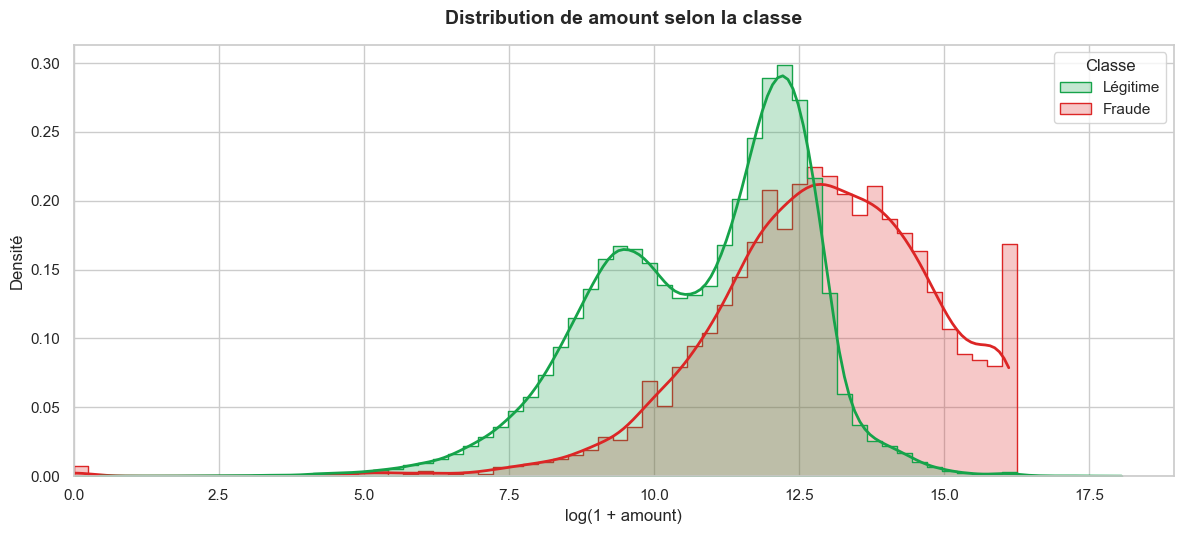

Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\05_boxplot_amount_log.png


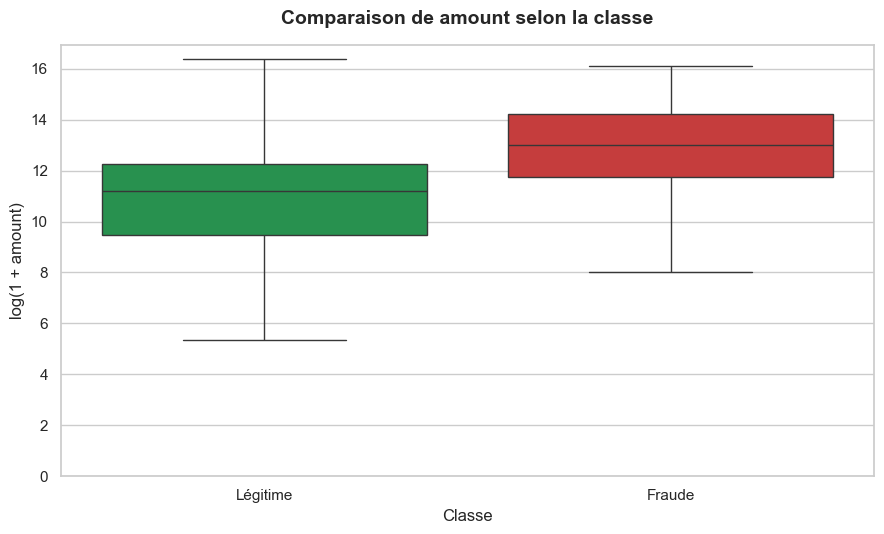

In [370]:
# Visualiser le montant
plot_numeric_distribution(
    data=eda_numeric_sample,
    variable="amount",
    use_log=True,
)

Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\04_distribution_oldbalanceOrg_log.png


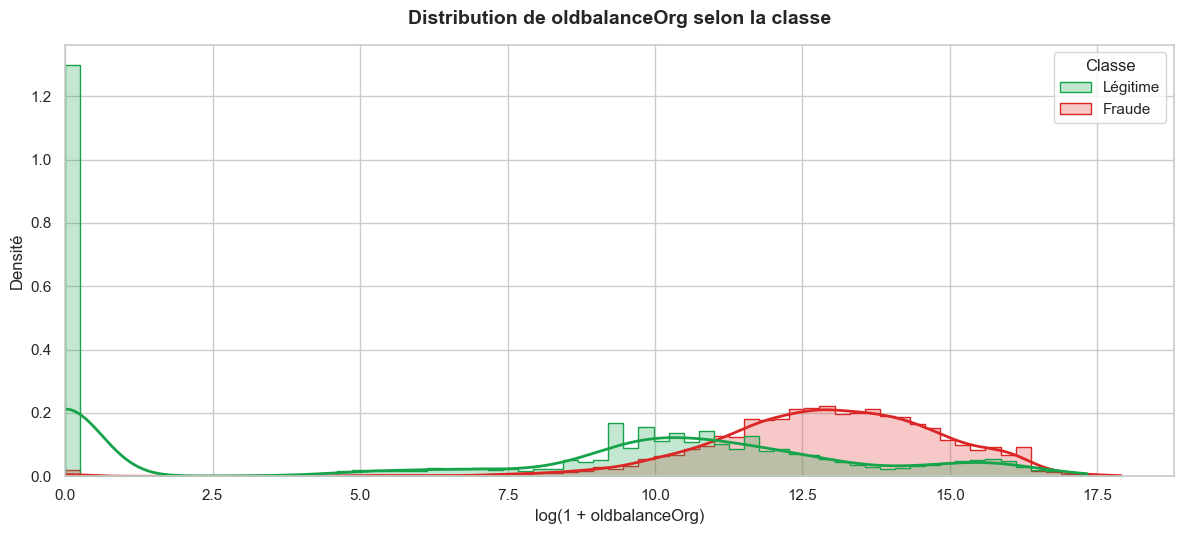

Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\05_boxplot_oldbalanceOrg_log.png


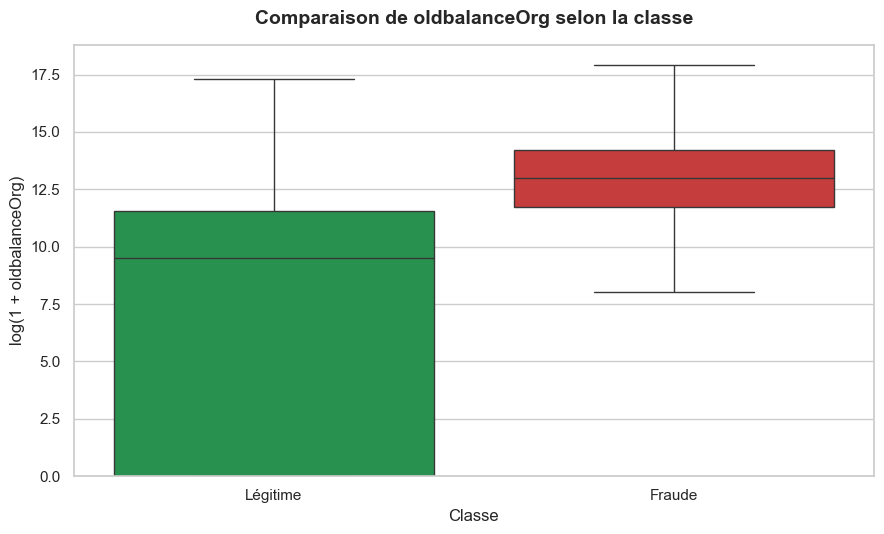

In [371]:
# Visualiser le solde initial de l’émetteur
plot_numeric_distribution(
    data=eda_numeric_sample,
    variable="oldbalanceOrg",
    use_log=True,
)

Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\04_distribution_newbalanceOrig_log.png


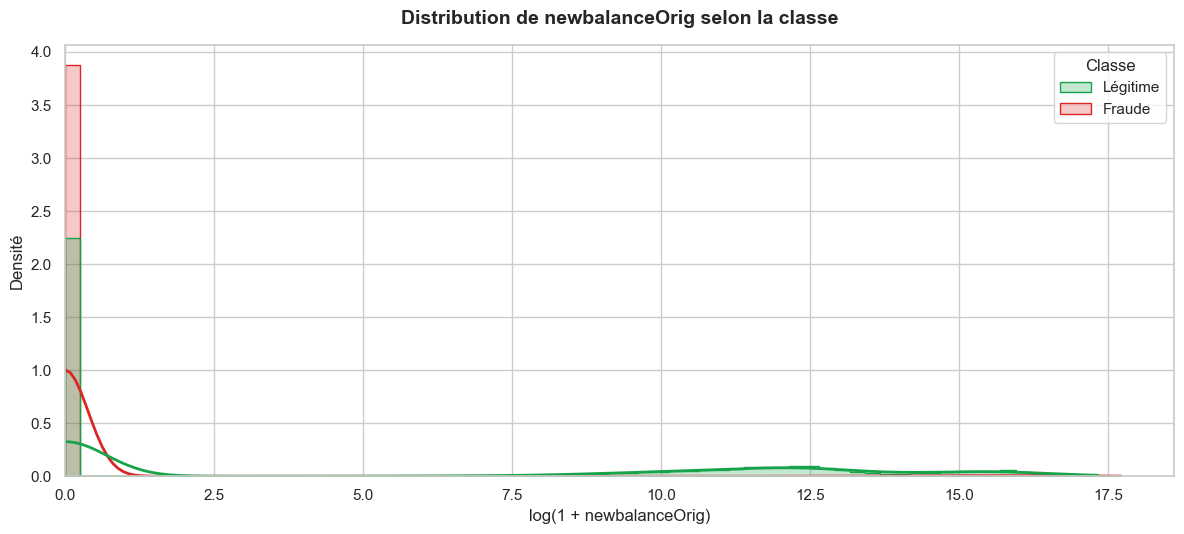

Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\05_boxplot_newbalanceOrig_log.png


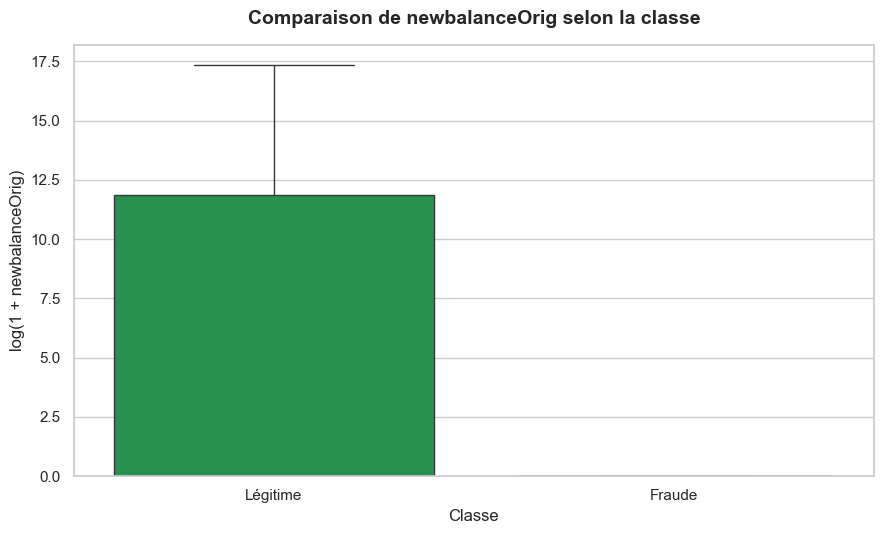

In [372]:
# Visualiser le solde final de l’émetteur
plot_numeric_distribution(
    data=eda_numeric_sample,
    variable="newbalanceOrig",
    use_log=True,
)

Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\04_distribution_oldbalanceDest_log.png


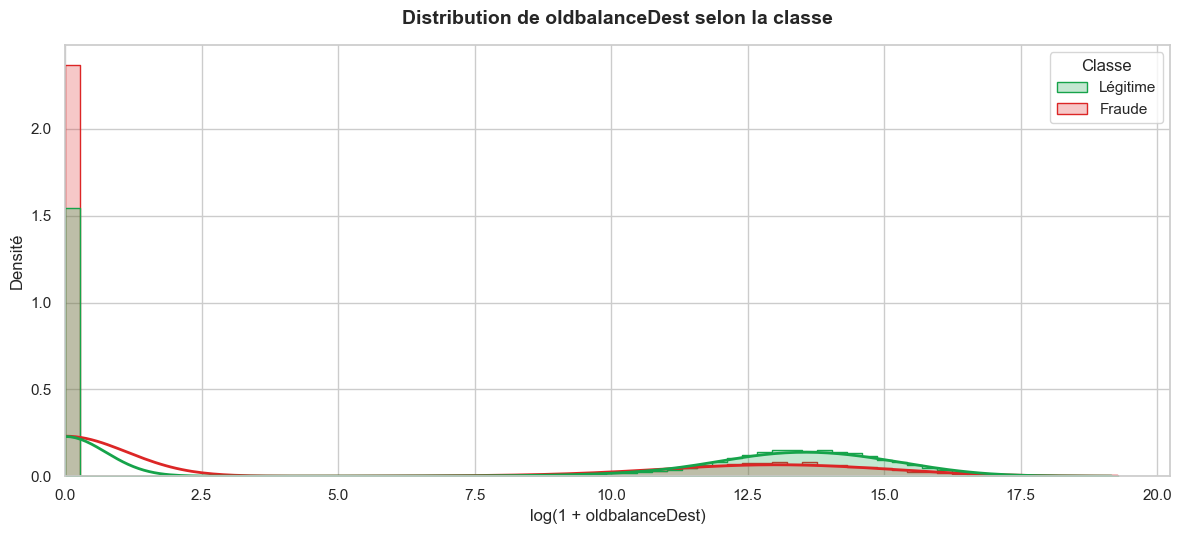

Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\05_boxplot_oldbalanceDest_log.png


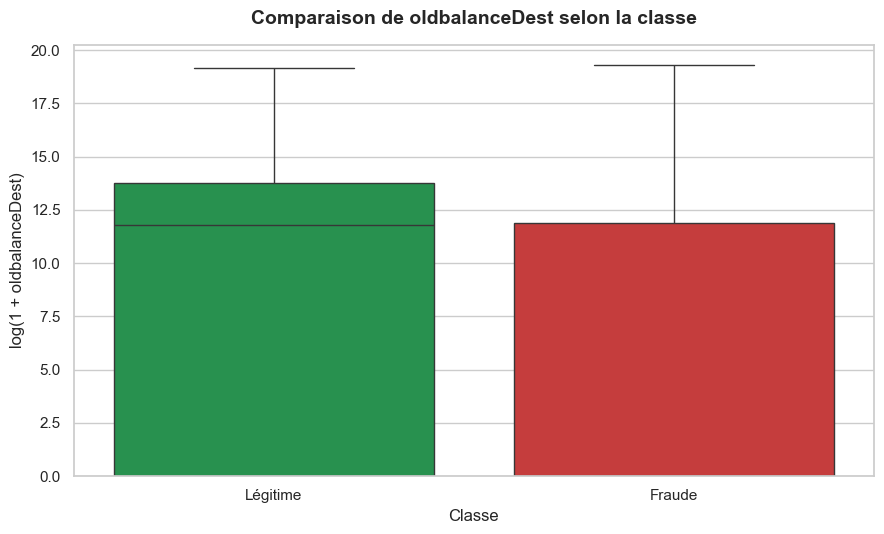

In [373]:
# Visualiser le solde initial du destinataire
plot_numeric_distribution(
    data=eda_numeric_sample,
    variable="oldbalanceDest",
    use_log=True,
)

Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\04_distribution_newbalanceDest_log.png


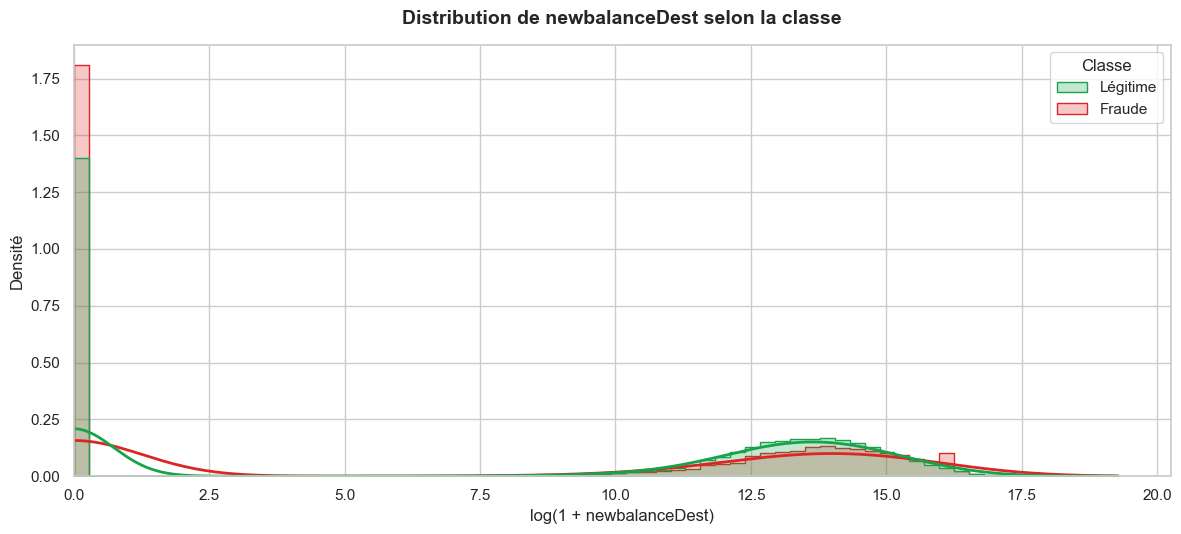

Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\05_boxplot_newbalanceDest_log.png


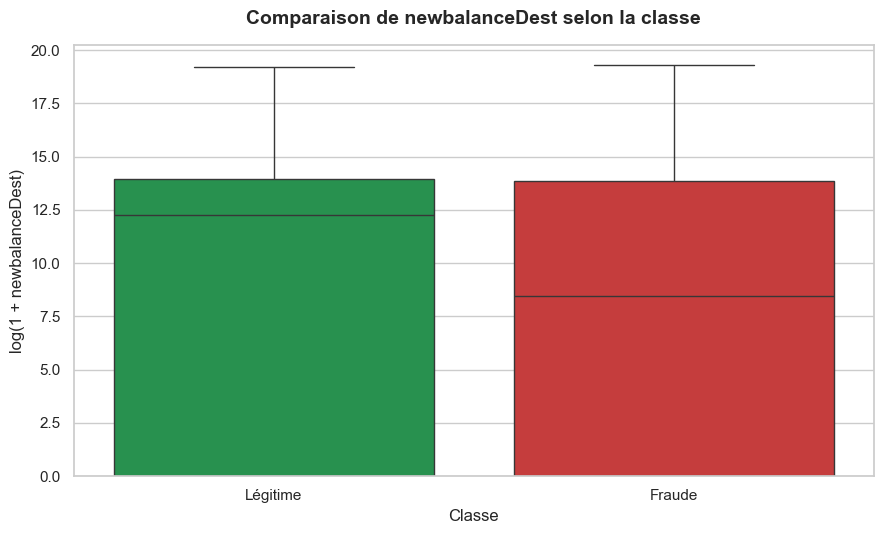

In [374]:
# Visualiser le solde final du destinataire
plot_numeric_distribution(
    data=eda_numeric_sample,
    variable="newbalanceDest",
    use_log=True,
)

Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\04_distribution_step.png


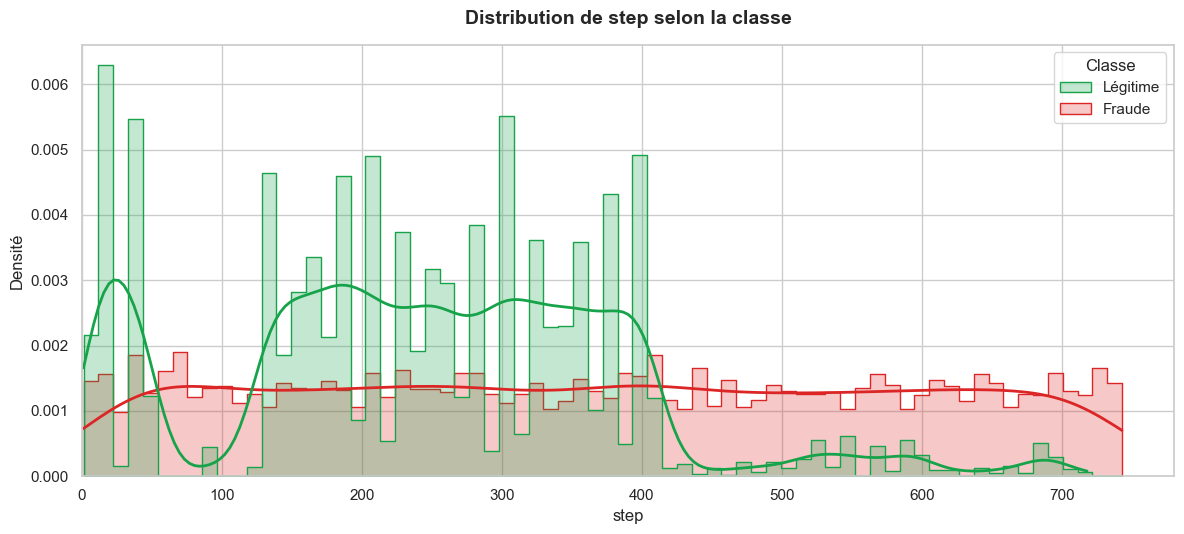

Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\05_boxplot_step.png


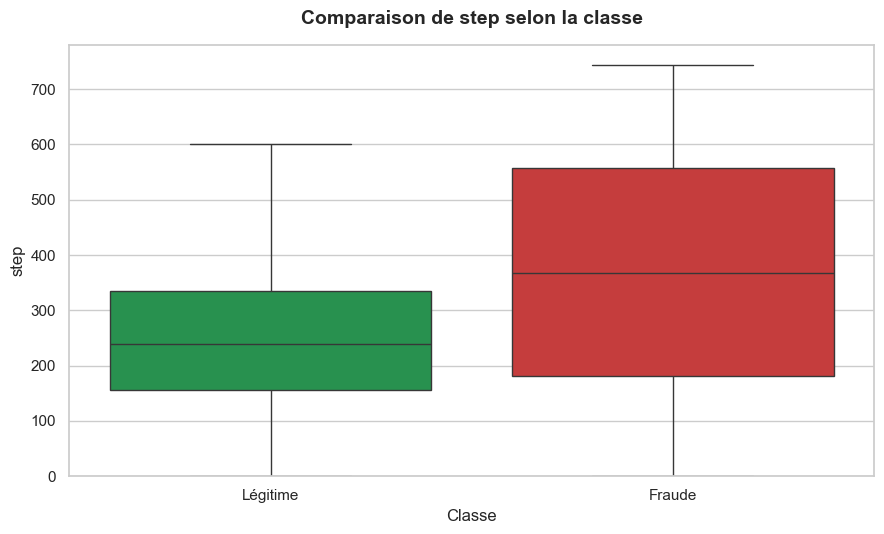

In [375]:
# Visualiser la variable temporelle
plot_numeric_distribution(
    data=eda_numeric_sample,
    variable="step",
    use_log=False,
)

In [376]:
# Interpréter la taille d’effet
def interpret_effect_size(effect):
    absolute_effect = abs(effect)

    if absolute_effect < 0.10:
        return "Négligeable"

    if absolute_effect < 0.30:
        return "Faible"

    if absolute_effect < 0.50:
        return "Modérée"

    return "Forte"


# Comparer les distributions
statistical_results = []

for variable in numeric_variables:
    fraud_values = fraud_sample[
        variable
    ].dropna()

    legitimate_values = legitimate_sample[
        variable
    ].dropna()

    # Calculer le test
    statistic, p_value = mannwhitneyu(
        fraud_values,
        legitimate_values,
        alternative="two-sided",
    )

    # Calculer la taille d’effet
    effect_size = (
        2 * statistic
        / (
            len(fraud_values)
            * len(legitimate_values)
        )
        - 1
    )

    # Ajouter les résultats
    statistical_results.append(
        {
            "Variable": variable,
            "Médiane fraude": fraud_values.median(),
            "Médiane légitime": legitimate_values.median(),
            "Différence médiane": (
                fraud_values.median()
                - legitimate_values.median()
            ),
            "Statistique U": statistic,
            "p-value": p_value,
            "Taille d’effet": effect_size,
            "Intensité": interpret_effect_size(
                effect_size
            ),
        }
    )

# Construire le tableau
statistical_results = pd.DataFrame(
    statistical_results
)

# Trier les variables
statistical_results["Effet absolu"] = (
    statistical_results["Taille d’effet"]
    .abs()
)

statistical_results = (
    statistical_results
    .sort_values(
        "Effet absolu",
        ascending=False,
    )
    .drop(columns="Effet absolu")
)

# Afficher les résultats
display(statistical_results)

,Variable,Médiane fraude,Médiane légitime,Différence médiane,Statistique U,p-value,Taille d’effet,Intensité
1,oldbalanceOrg,"438,983.45","13,448.50","425,534.95","667,234,247.50",0.00,0.62,Forte
0,amount,"441,423.44","74,300.74","367,122.71","648,526,407.50",0.00,0.58,Forte
2,newbalanceOrig,0.00,0.00,0.00,"244,335,015.50",0.00,-0.41,Modérée
5,step,367.00,240.00,127.00,"547,633,772.50",0.00,0.33,Modérée
3,oldbalanceDest,0.00,"131,525.78","-131,525.78","302,253,710.00",0.00,-0.26,Faible
4,newbalanceDest,"4,676.42","211,372.50","-206,696.08","377,866,880.00",0.00,-0.08,Négligeable


In [377]:
# Créer une copie lisible
statistical_results_display = (
    statistical_results.copy()
)

# Formater les p-values
statistical_results_display["p-value"] = (
    statistical_results_display["p-value"]
    .apply(
        lambda value: f"{value:.3e}"
    )
)

# Formater les tailles d’effet
statistical_results_display[
    "Taille d’effet"
] = (
    statistical_results_display[
        "Taille d’effet"
    ].round(4)
)

# Afficher le tableau
display(statistical_results_display)

,Variable,Médiane fraude,Médiane légitime,Différence médiane,Statistique U,p-value,Taille d’effet,Intensité
1,oldbalanceOrg,"438,983.45","13,448.50","425,534.95","667,234,247.50",0.000e+00,0.62,Forte
0,amount,"441,423.44","74,300.74","367,122.71","648,526,407.50",0.000e+00,0.58,Forte
2,newbalanceOrig,0.00,0.00,0.00,"244,335,015.50",0.000e+00,-0.41,Modérée
5,step,367.00,240.00,127.00,"547,633,772.50",0.000e+00,0.33,Modérée
3,oldbalanceDest,0.00,"131,525.78","-131,525.78","302,253,710.00",0.000e+00,-0.26,Faible
4,newbalanceDest,"4,676.42","211,372.50","-206,696.08","377,866,880.00",1.759e-35,-0.08,Négligeable


In [378]:
# Enregistrer les résultats
statistical_results.to_csv(
    tables_dir
    / "numeric_variables_statistical_tests.csv",
    index=False,
    encoding="utf-8-sig",
)

print(
    "Résultats enregistrés : "
    f"{tables_dir / 'numeric_variables_statistical_tests.csv'}"
)

Résultats enregistrés : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\tables\eda\numeric_variables_statistical_tests.csv


In [379]:
# Comparer les principales statistiques par classe
class_comparison = (
    df.groupby("isFraud")[numeric_variables]
    .agg(["mean", "median"])
    .T
    .reset_index()
)

# Renommer les colonnes
class_comparison.columns = [
    "Variable",
    "Statistique",
    "Légitime",
    "Fraude",
]

# Calculer le ratio fraude sur légitime
class_comparison["Ratio fraude / légitime"] = np.where(
    class_comparison["Légitime"] != 0,
    class_comparison["Fraude"]
    / class_comparison["Légitime"],
    np.nan,
)

# Afficher le tableau
display(class_comparison)

,Variable,Statistique,Légitime,Fraude,Ratio fraude / légitime
0,amount,mean,"178,197.04","1,467,967.30",8.24
1,amount,median,"74,684.72","441,423.44",5.91
2,oldbalanceOrg,mean,"832,828.71","1,649,667.61",1.98
3,oldbalanceOrg,median,"14,069.00","438,983.45",31.20
4,newbalanceOrig,mean,"855,970.23","192,392.63",0.22
5,newbalanceOrig,median,0.00,0.00,NaN
6,oldbalanceDest,mean,"1,101,420.87","544,249.62",0.49
7,oldbalanceDest,median,"133,311.80",0.00,0.00
8,newbalanceDest,mean,"1,224,925.68","1,279,707.62",1.04
9,newbalanceDest,median,"214,881.70","4,676.42",0.02


In [380]:
# Formater les p-values
def format_p_value(value):
    if value < 1e-300:
        return "< 1e-300"

    return f"{value:.3e}"


statistical_results_display["p-value"] = (
    statistical_results["p-value"]
    .apply(format_p_value)
)

## Conclusion de l’analyse univariée

### Observation

Les tests statistiques confirment que les distributions des variables
numériques diffèrent entre les transactions frauduleuses et légitimes.

Les variables présentant les différences les plus importantes sont :

- `oldbalanceOrg`, avec une taille d’effet forte de 0,6248 ;
- `amount`, avec une taille d’effet forte de 0,5793 ;
- `newbalanceOrig`, avec une taille d’effet modérée de -0,4050 ;
- `step`, avec une taille d’effet modérée de 0,3336.

La médiane du montant frauduleux est d’environ 441 423, contre 74 301 pour
les transactions légitimes. Le montant médian frauduleux est donc près de
six fois supérieur.

Le solde initial médian de l’émetteur est d’environ 438 983 pour les fraudes,
contre seulement 13 449 pour les transactions légitimes.

### Interprétation métier

Les transactions frauduleuses sont généralement associées à des montants
plus élevés et à des comptes émetteurs possédant davantage de fonds avant
l’opération.

Le comportement de vidage du compte semble également important. Même si la
médiane de `newbalanceOrig` vaut zéro dans les deux classes, la distribution
des fraudes est beaucoup plus concentrée autour d’un solde final nul.

Les variables du destinataire sont moins discriminantes lorsqu’elles sont
étudiées isolément. Elles pourront toutefois apporter de l’information
lorsqu’elles seront combinées avec le montant, le type de transaction et
l’historique relationnel des comptes.

La variable `step` présente une différence temporelle modérée entre les
classes, ce qui montre que le risque de fraude évolue pendant la simulation.

### Impact sur le Feature Engineering

Les variables candidates prioritaires sont :

- `log_amount` ;
- `origin_balance_change` ;
- `destination_balance_change` ;
- `amount_to_oldbalance_ratio` ;
- `is_origin_emptied` ;
- `amount_equals_oldbalance` ;
- `origin_balance_error` ;
- `destination_balance_error` ;
- variables temporelles dérivées de `step`.

### Impact sur les modèles Machine Learning

`amount` et `oldbalanceOrg` devraient avoir une importance élevée dans les
modèles classiques.

Les transformations logarithmiques seront particulièrement utiles pour les
modèles linéaires et neuronaux. Les variables originales seront également
conservées pour les modèles arborescents.

### Impact sur les Graph Neural Networks

Les montants, les soldes et le timestamp pourront devenir des attributs
d’arêtes.

Les comportements agrégés au niveau des comptes pourront devenir des attributs
de nœuds, notamment :

- le montant total envoyé ;
- le montant moyen reçu ;
- le nombre de transactions ;
- la proportion de transactions vidant le compte ;
- la fréquence d’activité ;
- le nombre de voisins uniques.

### Décision retenue

- Conserver toutes les variables numériques.
- Prioriser `amount` et `oldbalanceOrg`.
- Créer des indicateurs de vidage du compte.
- Traiter `step` comme une information temporelle.
- Ne pas éliminer les variables du destinataire avant les analyses
  multivariées et relationnelles.
- Ne supprimer aucune valeur extrême automatiquement.

# 4. Analyse approfondie des montants transactionnels

## Question métier

Les transactions frauduleuses concernent-elles principalement des montants élevés ou des transferts correspondant à la totalité du solde disponible ?

Cette section analyse :

- les montants moyens et médians selon la classe ;
- la distribution des montants frauduleux ;
- le risque de fraude selon les tranches de montant ;
- la relation entre le montant et le solde initial ;
- les comportements de vidage complet du compte ;
- les montants associés à la règle `isFlaggedFraud`.

Les enseignements obtenus serviront à créer de nouvelles variables lors du Feature Engineering.

In [381]:
# Calculer les statistiques des montants
amount_summary = (
    df.groupby("isFraud")["amount"]
    .agg(
        Nombre="count",
        Moyenne="mean",
        Médiane="median",
        Minimum="min",
        Q1=lambda values: values.quantile(0.25),
        Q3=lambda values: values.quantile(0.75),
        P90=lambda values: values.quantile(0.90),
        P95=lambda values: values.quantile(0.95),
        P99=lambda values: values.quantile(0.99),
        Maximum="max",
    )
    .reset_index()
)

# Renommer les classes
amount_summary["Classe"] = (
    amount_summary["isFraud"]
    .map(
        {
            0: "Légitime",
            1: "Fraude",
        }
    )
)

# Réorganiser les colonnes
amount_summary = amount_summary[
    [
        "Classe",
        "Nombre",
        "Moyenne",
        "Médiane",
        "Minimum",
        "Q1",
        "Q3",
        "P90",
        "P95",
        "P99",
        "Maximum",
    ]
]

# Afficher le tableau
display(amount_summary)

,Classe,Nombre,Moyenne,Médiane,Minimum,Q1,Q3,P90,P95,P99,Maximum
0,Légitime,6354407,"178,197.04","74,684.72",0.01,"13,368.40","208,364.76","364,373.44","515,610.42","1,586,064.17","92,445,516.64"
1,Fraude,8213,"1,467,967.30","441,423.44",0.00,"127,091.33","1,517,771.48","4,521,723.51","8,006,429.04","10,000,000.00","10,000,000.00"


In [382]:
# Sélectionner les statistiques légitimes
legitimate_amount = (
    amount_summary
    .loc[amount_summary["Classe"] == "Légitime"]
    .iloc[0]
)

# Sélectionner les statistiques frauduleuses
fraud_amount = (
    amount_summary
    .loc[amount_summary["Classe"] == "Fraude"]
    .iloc[0]
)

# Créer le tableau comparatif
amount_differences = pd.DataFrame(
    {
        "Indicateur": [
            "Moyenne",
            "Médiane",
            "Q1",
            "Q3",
            "P90",
            "P95",
            "P99",
        ],
        "Légitime": [
            legitimate_amount["Moyenne"],
            legitimate_amount["Médiane"],
            legitimate_amount["Q1"],
            legitimate_amount["Q3"],
            legitimate_amount["P90"],
            legitimate_amount["P95"],
            legitimate_amount["P99"],
        ],
        "Fraude": [
            fraud_amount["Moyenne"],
            fraud_amount["Médiane"],
            fraud_amount["Q1"],
            fraud_amount["Q3"],
            fraud_amount["P90"],
            fraud_amount["P95"],
            fraud_amount["P99"],
        ],
    }
)

# Calculer le ratio
amount_differences["Ratio fraude / légitime"] = (
    amount_differences["Fraude"]
    / amount_differences["Légitime"]
)

# Afficher le tableau
display(amount_differences)

,Indicateur,Légitime,Fraude,Ratio fraude / légitime
0,Moyenne,"178,197.04","1,467,967.30",8.24
1,Médiane,"74,684.72","441,423.44",5.91
2,Q1,"13,368.40","127,091.33",9.51
3,Q3,"208,364.76","1,517,771.48",7.28
4,P90,"364,373.44","4,521,723.51",12.41
5,P95,"515,610.42","8,006,429.04",15.53
6,P99,"1,586,064.17","10,000,000.00",6.30


In [383]:
# Enregistrer les statistiques
amount_summary.to_csv(
    tables_dir / "amount_summary_by_class.csv",
    index=False,
    encoding="utf-8-sig",
)

# Enregistrer les comparaisons
amount_differences.to_csv(
    tables_dir / "amount_differences.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Tableaux des montants enregistrés.")

Tableaux des montants enregistrés.


Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\06_amount_ecdf_by_class.png


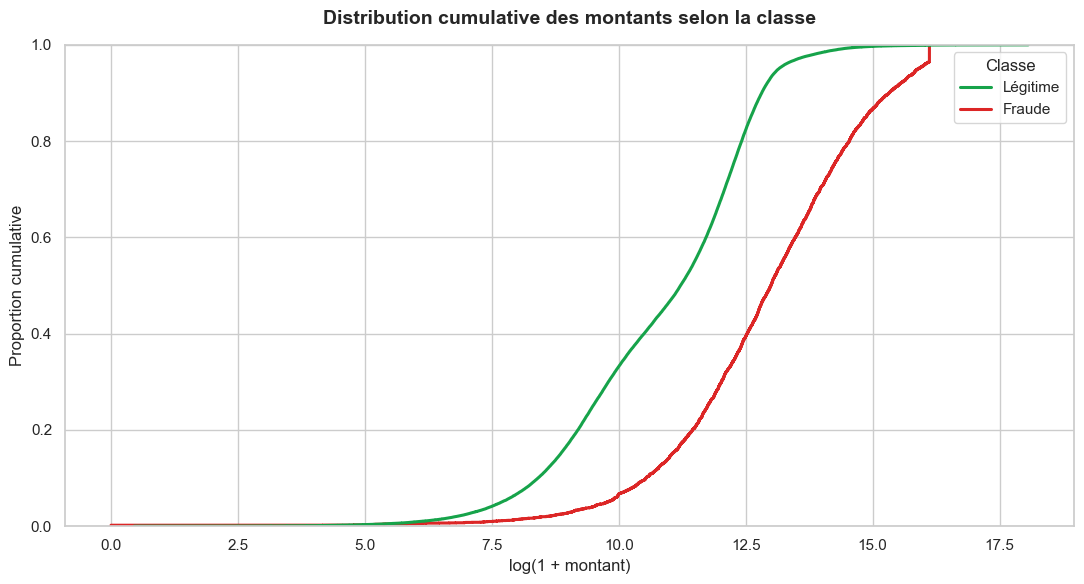

In [384]:
# Préparer les données
amount_plot_data = eda_numeric_sample[
    [
        "amount",
        "Classe",
    ]
].copy()

# Transformer les montants
amount_plot_data["log_amount"] = np.log1p(
    amount_plot_data["amount"]
)

# Créer le graphique
fig, ax = plt.subplots(
    figsize=(11, 6)
)

sns.ecdfplot(
    data=amount_plot_data,
    x="log_amount",
    hue="Classe",
    hue_order=[
        "Légitime",
        "Fraude",
    ],
    palette=class_palette,
    linewidth=2.2,
    ax=ax,
)

# Configurer le graphique
ax.set_title(
    "Distribution cumulative des montants selon la classe",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel("log(1 + montant)")
ax.set_ylabel("Proportion cumulative")

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "06_amount_ecdf_by_class.png"
)

plt.show()

In [385]:
# Créer les tranches de montant
amount_bins = pd.qcut(
    df["amount"],
    q=10,
    duplicates="drop",
)

# Construire le tableau temporaire
amount_bin_data = pd.DataFrame(
    {
        "Tranche": amount_bins,
        "isFraud": df["isFraud"],
        "amount": df["amount"],
    }
)

# Calculer les statistiques par tranche
amount_quantile_summary = (
    amount_bin_data
    .groupby(
        "Tranche",
        observed=True,
    )
    .agg(
        Transactions=("isFraud", "size"),
        Fraudes=("isFraud", "sum"),
        Montant_minimum=("amount", "min"),
        Montant_médian=("amount", "median"),
        Montant_maximum=("amount", "max"),
    )
    .reset_index()
)

# Calculer le taux de fraude
amount_quantile_summary["Taux de fraude (%)"] = (
    100
    * amount_quantile_summary["Fraudes"]
    / amount_quantile_summary["Transactions"]
)

# Ajouter un numéro de tranche
amount_quantile_summary["Décile"] = [
    f"D{index}"
    for index in range(
        1,
        len(amount_quantile_summary) + 1,
    )
]

# Afficher le tableau
display(
    amount_quantile_summary[
        [
            "Décile",
            "Transactions",
            "Fraudes",
            "Montant_minimum",
            "Montant_médian",
            "Montant_maximum",
            "Taux de fraude (%)",
        ]
    ]
)

,Décile,Transactions,Fraudes,Montant_minimum,Montant_médian,Montant_maximum,Taux de fraude (%)
0,D1,636263,148,0.00,"2,224.10","4,501.30",0.02
1,D2,636261,128,"4,501.31","6,998.11","9,866.15",0.02
2,D3,636262,148,"9,866.16","13,389.57","18,092.00",0.02
3,D4,636262,365,"18,092.04","25,118.26","36,371.32",0.06
4,D5,636262,617,"36,371.37","53,495.58","74,871.80",0.10
5,D6,636262,592,"74,872.08","98,050.78","122,563.76",0.09
6,D7,636262,581,"122,563.82","148,507.12","176,801.88",0.09
7,D8,636262,503,"176,802.01","208,721.51","246,611.16",0.08
8,D9,636262,719,"246,611.46","294,919.51","365,423.29",0.11
9,D10,636262,4412,"365,423.48","518,634.26","92,445,516.64",0.69


Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\07_fraud_rate_by_amount_decile.png


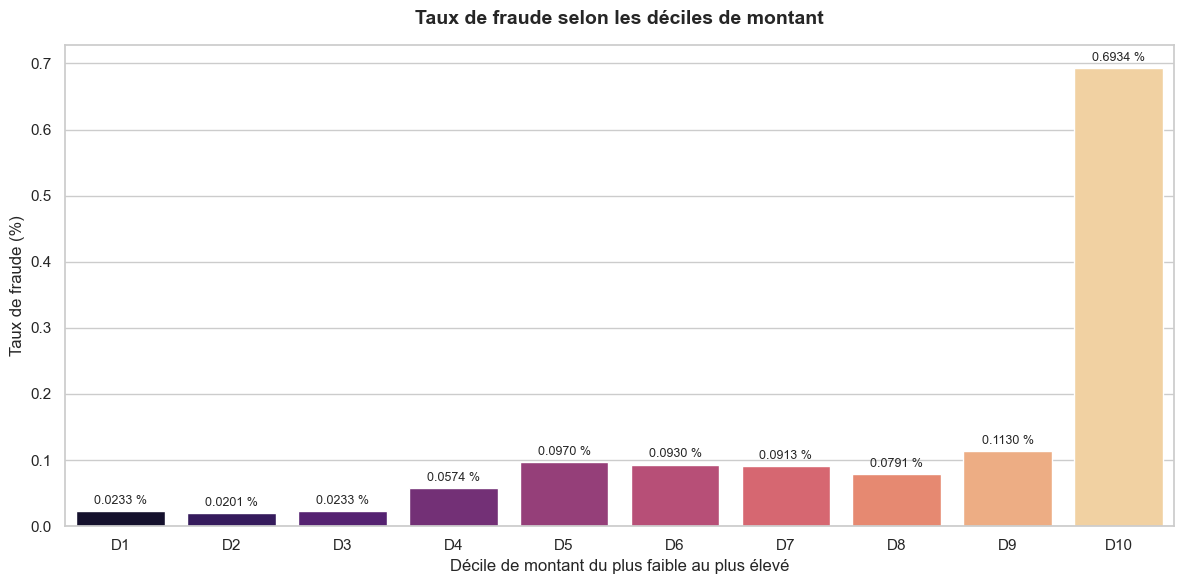

In [386]:
# Créer le graphique
fig, ax = plt.subplots(
    figsize=(12, 6)
)

sns.barplot(
    data=amount_quantile_summary,
    x="Décile",
    y="Taux de fraude (%)",
    hue="Décile",
    palette="magma",
    legend=False,
    ax=ax,
)

# Ajouter les annotations
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.4f %%",
        padding=3,
        fontsize=9,
    )

# Configurer le graphique
ax.set_title(
    "Taux de fraude selon les déciles de montant",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel(
    "Décile de montant du plus faible au plus élevé"
)

ax.set_ylabel(
    "Taux de fraude (%)"
)

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "07_fraud_rate_by_amount_decile.png"
)

plt.show()

In [387]:
# Sélectionner les fraudes
fraud_transactions = df.loc[
    df["isFraud"] == 1,
    [
        "type",
        "amount",
        "oldbalanceOrg",
        "newbalanceOrig",
        "step",
    ],
].copy()

# Créer le montant logarithmique
fraud_transactions["log_amount"] = np.log1p(
    fraud_transactions["amount"]
)

# Calculer les statistiques par type
fraud_amount_by_type = (
    fraud_transactions
    .groupby(
        "type",
        observed=True,
    )["amount"]
    .agg(
        Nombre="count",
        Moyenne="mean",
        Médiane="median",
        Q1=lambda values: values.quantile(0.25),
        Q3=lambda values: values.quantile(0.75),
        P95=lambda values: values.quantile(0.95),
        Maximum="max",
    )
    .reset_index()
)

# Afficher le tableau
display(fraud_amount_by_type)

,type,Nombre,Moyenne,Médiane,Q1,Q3,P95,Maximum
0,CASH_OUT,4116,"1,455,102.59","435,516.91","125,464.45","1,500,761.03","7,841,465.04","10,000,000.00"
1,TRANSFER,4097,"1,480,891.67","445,705.76","128,417.96","1,534,985.07","8,098,658.15","10,000,000.00"


Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\08_fraud_amount_by_type.png


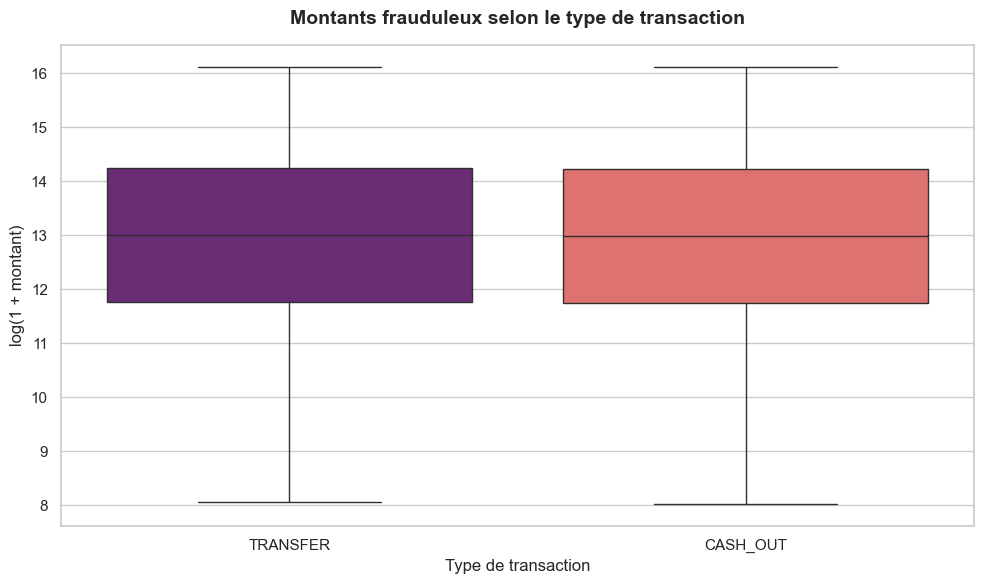

In [388]:
# Créer le graphique
fig, ax = plt.subplots(
    figsize=(10, 6)
)

sns.boxplot(
    data=fraud_transactions,
    x="type",
    y="log_amount",
    hue="type",
    palette="magma",
    legend=False,
    showfliers=False,
    ax=ax,
)

# Configurer le graphique
ax.set_title(
    "Montants frauduleux selon le type de transaction",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel(
    "Type de transaction"
)

ax.set_ylabel(
    "log(1 + montant)"
)

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "08_fraud_amount_by_type.png"
)

plt.show()

Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\09_amount_vs_oldbalanceOrg.png


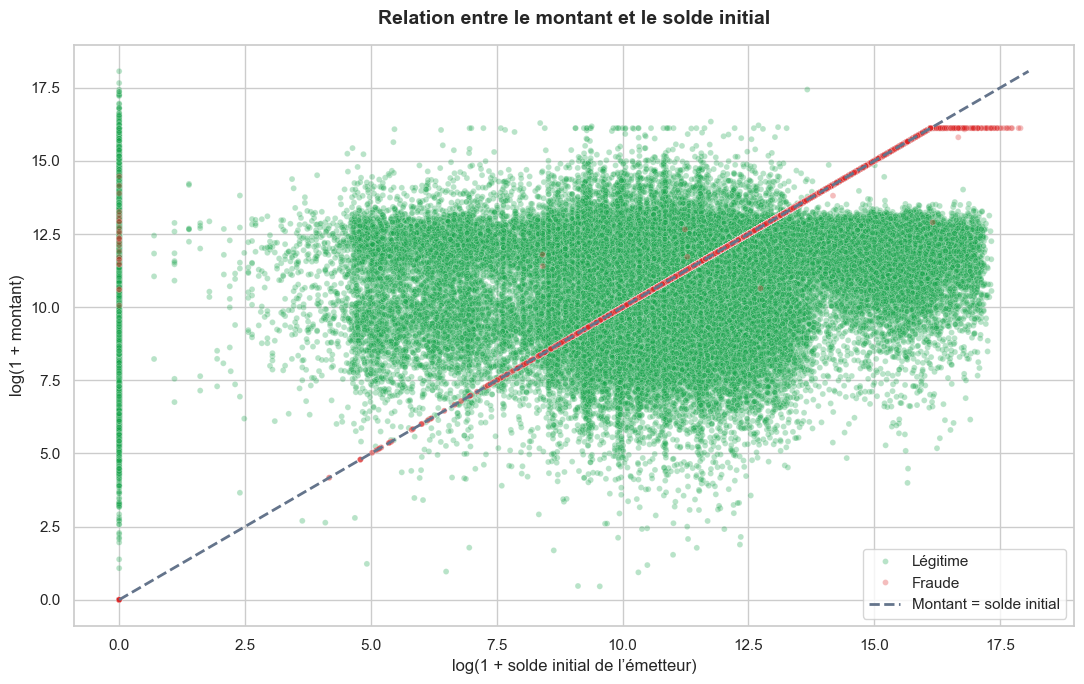

In [389]:
# Préparer les données
balance_amount_sample = eda_numeric_sample[
    [
        "amount",
        "oldbalanceOrg",
        "Classe",
    ]
].copy()

# Transformer les variables
balance_amount_sample["log_amount"] = np.log1p(
    balance_amount_sample["amount"]
)

balance_amount_sample["log_oldbalanceOrg"] = np.log1p(
    balance_amount_sample["oldbalanceOrg"]
)

# Créer le graphique
fig, ax = plt.subplots(
    figsize=(11, 7)
)

sns.scatterplot(
    data=balance_amount_sample,
    x="log_oldbalanceOrg",
    y="log_amount",
    hue="Classe",
    hue_order=[
        "Légitime",
        "Fraude",
    ],
    palette=class_palette,
    alpha=0.30,
    s=18,
    ax=ax,
)

# Calculer la valeur maximale
maximum_value = max(
    balance_amount_sample[
        "log_amount"
    ].max(),
    balance_amount_sample[
        "log_oldbalanceOrg"
    ].max(),
)

# Ajouter la diagonale
ax.plot(
    [0, maximum_value],
    [0, maximum_value],
    linestyle="--",
    linewidth=2,
    color=COLORS["neutral"],
    label="Montant = solde initial",
)

# Configurer le graphique
ax.set_title(
    "Relation entre le montant et le solde initial",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel(
    "log(1 + solde initial de l’émetteur)"
)

ax.set_ylabel(
    "log(1 + montant)"
)

ax.legend()

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "09_amount_vs_oldbalanceOrg.png"
)

plt.show()

In [390]:
# Définir la tolérance
balance_tolerance = 0.01

# Vérifier si le montant égale le solde
amount_equals_oldbalance = (
    (df["oldbalanceOrg"] > 0)
    & np.isclose(
        df["amount"],
        df["oldbalanceOrg"],
        atol=balance_tolerance,
        rtol=0,
    )
)

# Vérifier si le compte est vidé
origin_emptied = (
    (df["oldbalanceOrg"] > 0)
    & (df["newbalanceOrig"] == 0)
)

# Vérifier le transfert total
full_balance_transfer = (
    amount_equals_oldbalance
    & origin_emptied
)

# Vérifier si le montant dépasse le solde
amount_exceeds_balance = (
    df["amount"]
    > df["oldbalanceOrg"] + balance_tolerance
)

In [391]:
# Construire les données temporaires
emptying_data = pd.DataFrame(
    {
        "isFraud": df["isFraud"],
        "amount_equals_oldbalance": (
            amount_equals_oldbalance
        ),
        "origin_emptied": origin_emptied,
        "full_balance_transfer": (
            full_balance_transfer
        ),
        "amount_exceeds_balance": (
            amount_exceeds_balance
        ),
    }
)

# Calculer les statistiques
emptying_summary = (
    emptying_data
    .groupby("isFraud")
    .agg(
        Transactions=("isFraud", "size"),
        Montant_égal_au_solde=(
            "amount_equals_oldbalance",
            "sum",
        ),
        Compte_vidé=(
            "origin_emptied",
            "sum",
        ),
        Transfert_total=(
            "full_balance_transfer",
            "sum",
        ),
        Montant_supérieur_au_solde=(
            "amount_exceeds_balance",
            "sum",
        ),
    )
    .reset_index()
)

# Calculer les pourcentages
emptying_summary[
    "Taux montant égal au solde (%)"
] = (
    100
    * emptying_summary[
        "Montant_égal_au_solde"
    ]
    / emptying_summary["Transactions"]
)

emptying_summary[
    "Taux compte vidé (%)"
] = (
    100
    * emptying_summary["Compte_vidé"]
    / emptying_summary["Transactions"]
)

emptying_summary[
    "Taux transfert total (%)"
] = (
    100
    * emptying_summary["Transfert_total"]
    / emptying_summary["Transactions"]
)

emptying_summary[
    "Taux montant supérieur au solde (%)"
] = (
    100
    * emptying_summary[
        "Montant_supérieur_au_solde"
    ]
    / emptying_summary["Transactions"]
)

# Renommer les classes
emptying_summary["Classe"] = (
    emptying_summary["isFraud"]
    .map(
        {
            0: "Légitime",
            1: "Fraude",
        }
    )
)

# Afficher le tableau
display(emptying_summary)

,isFraud,Transactions,Montant_égal_au_solde,Compte_vidé,Transfert_total,Montant_supérieur_au_solde,Taux montant égal au solde (%),Taux compte vidé (%),Taux transfert total (%),Taux montant supérieur au solde (%),Classe
0,0,6354407,1,1512569,0,4079050,0.00,23.80,0.00,64.19,Légitime
1,1,8213,8018,8012,8008,29,97.63,97.55,97.50,0.35,Fraude


Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\10_account_emptying_patterns.png


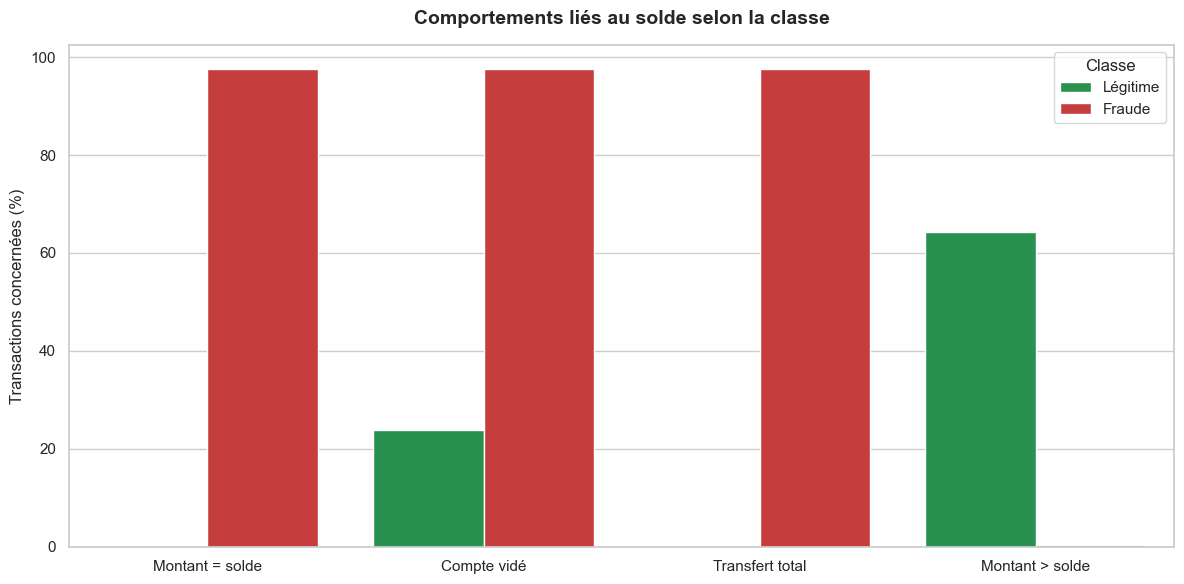

In [392]:
# Préparer les données
emptying_plot = emptying_summary[
    [
        "Classe",
        "Taux montant égal au solde (%)",
        "Taux compte vidé (%)",
        "Taux transfert total (%)",
        "Taux montant supérieur au solde (%)",
    ]
].melt(
    id_vars="Classe",
    var_name="Indicateur",
    value_name="Pourcentage",
)

# Simplifier les labels
emptying_plot["Indicateur"] = (
    emptying_plot["Indicateur"]
    .replace(
        {
            "Taux montant égal au solde (%)": (
                "Montant = solde"
            ),
            "Taux compte vidé (%)": (
                "Compte vidé"
            ),
            "Taux transfert total (%)": (
                "Transfert total"
            ),
            "Taux montant supérieur au solde (%)": (
                "Montant > solde"
            ),
        }
    )
)

# Créer le graphique
fig, ax = plt.subplots(
    figsize=(12, 6)
)

sns.barplot(
    data=emptying_plot,
    x="Indicateur",
    y="Pourcentage",
    hue="Classe",
    palette=class_palette,
    ax=ax,
)

# Configurer le graphique
ax.set_title(
    "Comportements liés au solde selon la classe",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel("")
ax.set_ylabel(
    "Transactions concernées (%)"
)

ax.legend(
    title="Classe"
)

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "10_account_emptying_patterns.png"
)

plt.show()

In [393]:
# Calculer le seuil élevé
high_amount_threshold = df["amount"].quantile(
    0.99
)

# Identifier les montants élevés
high_amount_mask = (
    df["amount"]
    >= high_amount_threshold
)

# Calculer le résumé
high_amount_summary = pd.DataFrame(
    {
        "Catégorie": [
            "Montants inférieurs au P99",
            "Montants supérieurs ou égaux au P99",
        ],
        "Transactions": [
            int((~high_amount_mask).sum()),
            int(high_amount_mask.sum()),
        ],
        "Fraudes": [
            int(
                df.loc[
                    ~high_amount_mask,
                    "isFraud",
                ].sum()
            ),
            int(
                df.loc[
                    high_amount_mask,
                    "isFraud",
                ].sum()
            ),
        ],
    }
)

# Calculer le taux de fraude
high_amount_summary["Taux de fraude (%)"] = (
    100
    * high_amount_summary["Fraudes"]
    / high_amount_summary["Transactions"]
)

# Afficher le seuil
print(
    f"Seuil du 99e percentile : "
    f"{high_amount_threshold:,.2f}"
)

# Afficher le tableau
display(high_amount_summary)

Seuil du 99e percentile : 1,615,979.47


,Catégorie,Transactions,Fraudes,Taux de fraude (%)
0,Montants inférieurs au P99,6298993,6244,0.10
1,Montants supérieurs ou égaux au P99,63627,1969,3.09


In [394]:
# Sélectionner les transactions signalées
flagged_amounts = df.loc[
    df["isFlaggedFraud"] == 1,
    [
        "amount",
        "type",
        "isFraud",
        "oldbalanceOrg",
        "newbalanceOrig",
    ],
].copy()

# Afficher les statistiques
if len(flagged_amounts) > 0:
    flagged_amount_summary = (
        flagged_amounts["amount"]
        .describe()
        .to_frame("Montant")
    )

    display(flagged_amount_summary)

    print(
        f"Montant minimum signalé : "
        f"{flagged_amounts['amount'].min():,.2f}"
    )

    print(
        f"Montant maximum signalé : "
        f"{flagged_amounts['amount'].max():,.2f}"
    )

    display(
        flagged_amounts.sort_values(
            "amount"
        )
    )

else:
    print(
        "Aucune transaction signalée."
    )

,Montant
count,16.00
mean,"4,861,597.73"
std,"3,572,499.10"
min,"353,874.22"
25%,"2,242,748.72"
50%,"4,234,245.09"
75%,"7,883,451.38"
max,"10,000,000.00"


Montant minimum signalé : 353,874.22
Montant maximum signalé : 10,000,000.00


,amount,type,isFraud,oldbalanceOrg,newbalanceOrig
6205439,"353,874.22",TRANSFER,1,"353,874.22","353,874.22"
6281484,"399,045.08",TRANSFER,1,"10,399,045.08","10,399,045.08"
3760288,"536,624.41",TRANSFER,1,"536,624.41","536,624.41"
3247297,"1,343,002.08",TRANSFER,1,"1,343,002.08","1,343,002.08"
6266413,"2,542,664.27",TRANSFER,1,"2,542,664.27","2,542,664.27"
6351225,"3,171,085.59",TRANSFER,1,"3,171,085.59","3,171,085.59"
6296014,"3,441,041.46",TRANSFER,1,"3,441,041.46","3,441,041.46"
6168499,"3,576,297.10",TRANSFER,1,"3,576,297.10","3,576,297.10"
5563713,"4,892,193.09",TRANSFER,1,"4,892,193.09","4,892,193.09"
2736446,"4,953,893.08",TRANSFER,1,"4,953,893.08","4,953,893.08"


Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\11_median_amount_over_time.png


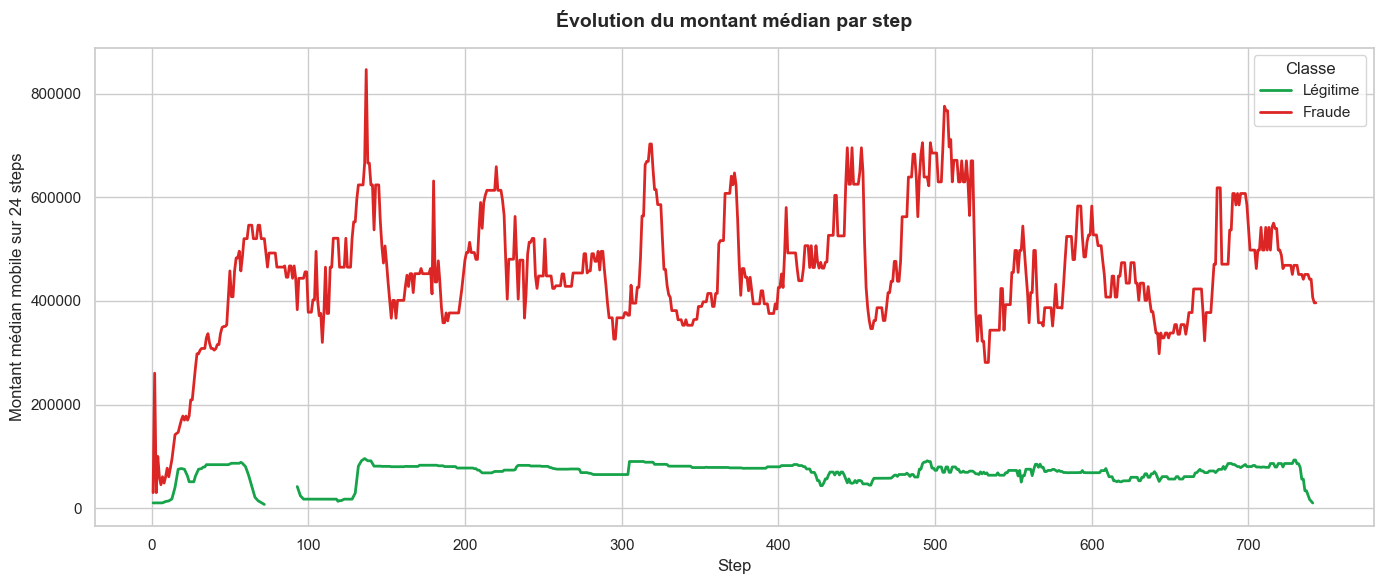

In [395]:
# Calculer les montants par step
amount_by_step = (
    df.groupby(
        [
            "step",
            "isFraud",
        ]
    )["amount"]
    .median()
    .unstack(fill_value=np.nan)
    .rename(
        columns={
            0: "Légitime",
            1: "Fraude",
        }
    )
)

# Calculer les moyennes mobiles
amount_by_step_rolling = (
    amount_by_step
    .rolling(
        window=24,
        min_periods=1,
    )
    .median()
)

# Créer le graphique
fig, ax = plt.subplots(
    figsize=(14, 6)
)

for class_name, color in class_palette.items():
    if class_name in amount_by_step_rolling.columns:
        ax.plot(
            amount_by_step_rolling.index,
            amount_by_step_rolling[class_name],
            label=class_name,
            color=color,
            linewidth=2,
        )

# Configurer le graphique
ax.set_title(
    "Évolution du montant médian par step",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel("Step")
ax.set_ylabel(
    "Montant médian mobile sur 24 steps"
)

ax.legend(
    title="Classe"
)

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "11_median_amount_over_time.png"
)

plt.show()

In [396]:
# Enregistrer les déciles
amount_quantile_summary.to_csv(
    tables_dir / "amount_quantile_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

# Enregistrer les montants par type
fraud_amount_by_type.to_csv(
    tables_dir / "fraud_amount_by_type.csv",
    index=False,
    encoding="utf-8-sig",
)

# Enregistrer les comportements
emptying_summary.to_csv(
    tables_dir / "account_emptying_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

# Enregistrer les montants élevés
high_amount_summary.to_csv(
    tables_dir / "high_amount_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

print(
    "Résultats de la section 4 enregistrés."
)

Résultats de la section 4 enregistrés.


## Conclusion de l’analyse des montants

### Observation

Les transactions frauduleuses présentent des montants nettement plus élevés que
les transactions légitimes.

Le montant médian d’une fraude est d’environ 441 423, contre 74 685 pour une
transaction légitime. Le montant moyen est également plus de huit fois supérieur
dans la classe fraude.

Le risque de fraude augmente fortement dans les tranches de montant élevées.
Les transactions situées au-dessus du 99e percentile présentent un taux de fraude
d’environ 3,09 %, contre environ 0,10 % pour les autres transactions.

Cependant, près de 76 % des fraudes restent sous ce seuil. Un système basé
uniquement sur les montants élevés manquerait donc une grande partie des fraudes.

### Interprétation métier

Le résultat le plus marquant concerne le comportement du compte émetteur.

Environ 97,6 % des transactions frauduleuses présentent un montant égal au solde
initial du compte et environ 97,5 % correspondent à un transfert vidant
complètement le compte.

Ce comportement suggère un schéma de fraude consistant à transférer rapidement
la totalité des fonds disponibles sur un compte compromis.

Les fraudes sont réparties presque équitablement entre les types `CASH_OUT` et
`TRANSFER`, ce qui confirme que le type d’opération constitue un signal utile,
mais insuffisant à lui seul.

### Impact sur le Feature Engineering

Les variables suivantes apparaissent prioritaires :

- `log_amount` ;
- `amount_to_oldbalance_ratio` ;
- `amount_equals_oldbalance` ;
- `is_origin_emptied` ;
- `full_balance_transfer` ;
- `amount_above_p99` ;
- `origin_balance_change` ;
- interaction entre `type` et `amount`.

### Impact sur les modèles Machine Learning

Le montant est fortement discriminant, mais il ne doit pas être utilisé comme
une règle isolée.

Les variables liées au vidage du compte devraient être particulièrement
informatives pour les modèles supervisés.

Les modèles devront toutefois apprendre des interactions entre plusieurs
variables afin de détecter également les fraudes de faible montant.

### Impact sur les Graph Neural Networks

Le montant pourra être utilisé comme attribut d’arête dans le graphe.

Les comportements de vidage du compte pourront être agrégés au niveau des nœuds
afin de caractériser les comptes présentant une activité suspecte.

Les relations entre comptes permettront ensuite de déterminer si ces opérations
s’inscrivent dans des structures ou des séquences transactionnelles anormales.

### Décision retenue

- Conserver le montant original et créer `log_amount`.
- Créer un ratio montant / solde initial.
- Créer un indicateur de vidage complet du compte.
- Créer un indicateur de montant élevé.
- Ne pas utiliser un seuil de montant comme règle unique de détection.
- Étudier ensuite l’évolution temporelle des fraudes.

# 5. Analyse temporelle des transactions

## Question métier

Les transactions frauduleuses présentent-elles des comportements temporels
différents des transactions légitimes ?

Cette section étudie l'évolution de l'activité transactionnelle et de la fraude
au niveau de la variable `step`, qui représente l'unité temporelle native de
PaySim.

L'objectif est notamment de déterminer :

- si les fraudes sont réparties uniformément dans le temps ;
- s'il existe des périodes de concentration de la fraude ;
- si les pics de fraude coïncident avec les pics d'activité globale ;
- si le taux de fraude évolue au cours de la simulation ;
- si certaines positions dans un cycle de 24 steps présentent davantage de
  fraude ;
- si les fraudes apparaissent sous forme de séquences temporelles rapprochées.

Ces analyses permettront de préparer la future modélisation par Dynamic Graph
Learning, où l'ordre d'apparition des transactions constitue une information
essentielle.

In [397]:
# Agréger les transactions par step
temporal_stats = (
    df.groupby("step")
    .agg(
        Transactions=("isFraud", "size"),
        Fraudes=("isFraud", "sum"),
        Montant_total=("amount", "sum"),
        Montant_médian=("amount", "median"),
    )
)

# Créer tous les steps de la période
all_steps = pd.Index(
    range(
        int(df["step"].min()),
        int(df["step"].max()) + 1,
    ),
    name="step",
)

# Ajouter les éventuels steps absents
temporal_stats = (
    temporal_stats
    .reindex(all_steps)
)

# Remplir les volumes absents
temporal_stats["Transactions"] = (
    temporal_stats["Transactions"]
    .fillna(0)
    .astype(int)
)

temporal_stats["Fraudes"] = (
    temporal_stats["Fraudes"]
    .fillna(0)
    .astype(int)
)

temporal_stats["Montant_total"] = (
    temporal_stats["Montant_total"]
    .fillna(0)
)

# Calculer le taux de fraude
temporal_stats["Taux de fraude (%)"] = np.where(
    temporal_stats["Transactions"] > 0,
    (
        100
        * temporal_stats["Fraudes"]
        / temporal_stats["Transactions"]
    ),
    np.nan,
)

# Afficher les premières lignes
display(temporal_stats.head())

,Transactions,Fraudes,Montant_total,Montant_médian,Taux de fraude (%)
step,,,,,
1,2708,16,"285,429,181.15","10,286.17",0.59
2,1014,8,"85,921,604.02","10,522.77",0.79
3,552,4,"43,293,884.42","14,091.98",0.72
4,565,10,"72,910,028.57","7,800.55",1.77
5,665,6,"45,548,089.75","6,902.52",0.90


In [398]:
# Définir la fenêtre temporelle
rolling_window = 24

# Calculer le volume moyen
temporal_stats["Transactions MA24"] = (
    temporal_stats["Transactions"]
    .rolling(
        window=rolling_window,
        min_periods=1,
    )
    .mean()
)

# Calculer le nombre moyen de fraudes
temporal_stats["Fraudes MA24"] = (
    temporal_stats["Fraudes"]
    .rolling(
        window=rolling_window,
        min_periods=1,
    )
    .mean()
)

# Calculer les fraudes cumulées sur 24 steps
rolling_frauds = (
    temporal_stats["Fraudes"]
    .rolling(
        window=rolling_window,
        min_periods=1,
    )
    .sum()
)

# Calculer les transactions cumulées sur 24 steps
rolling_transactions = (
    temporal_stats["Transactions"]
    .rolling(
        window=rolling_window,
        min_periods=1,
    )
    .sum()
)

# Calculer le taux de fraude mobile
temporal_stats["Taux fraude mobile 24 steps (%)"] = np.where(
    rolling_transactions > 0,
    100 * rolling_frauds / rolling_transactions,
    np.nan,
)

display(temporal_stats.head())

,Transactions,Fraudes,Montant_total,Montant_médian,Taux de fraude (%),Transactions MA24,Fraudes MA24,Taux fraude mobile 24 steps (%)
step,,,,,,,,
1,2708,16,"285,429,181.15","10,286.17",0.59,"2,708.00",16.00,0.59
2,1014,8,"85,921,604.02","10,522.77",0.79,"1,861.00",12.00,0.64
3,552,4,"43,293,884.42","14,091.98",0.72,"1,424.67",9.33,0.66
4,565,10,"72,910,028.57","7,800.55",1.77,"1,209.75",9.50,0.79
5,665,6,"45,548,089.75","6,902.52",0.90,"1,100.80",8.80,0.80


Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\12_transaction_volume_by_step.png


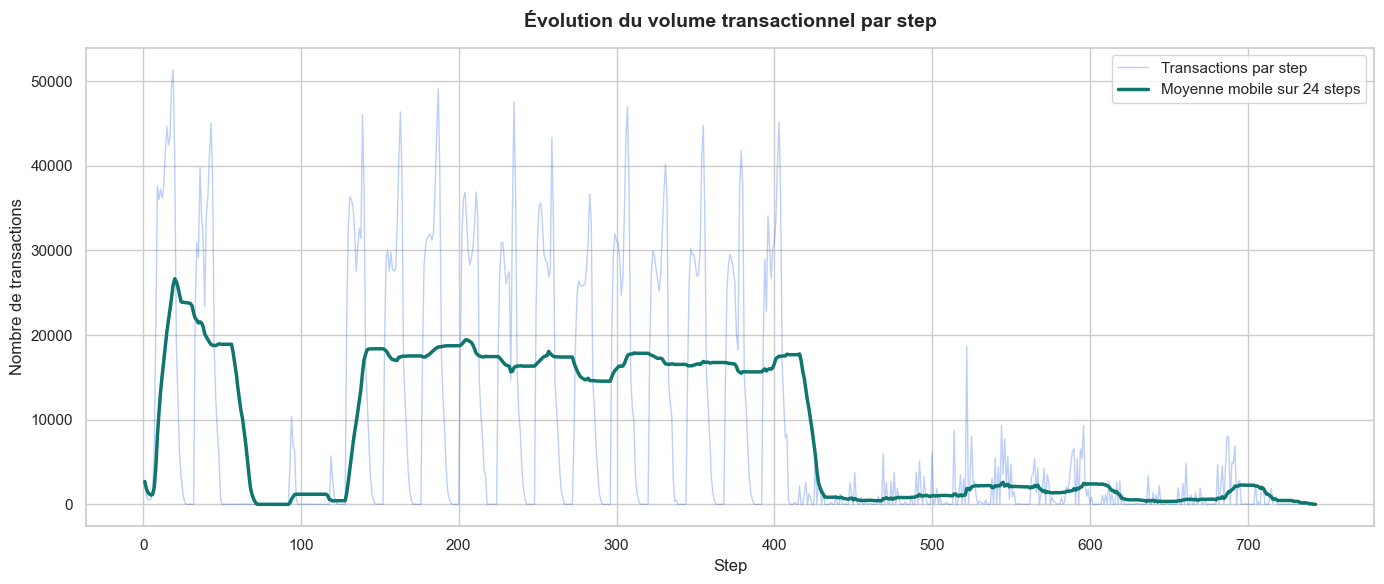

In [399]:
# Créer le graphique
fig, ax = plt.subplots(
    figsize=(14, 6)
)

# Tracer le volume brut
ax.plot(
    temporal_stats.index,
    temporal_stats["Transactions"],
    color=COLORS["primary"],
    alpha=0.30,
    linewidth=1,
    label="Transactions par step",
)

# Tracer la moyenne mobile
ax.plot(
    temporal_stats.index,
    temporal_stats["Transactions MA24"],
    color=COLORS["secondary"],
    linewidth=2.5,
    label="Moyenne mobile sur 24 steps",
)

# Configurer le graphique
ax.set_title(
    "Évolution du volume transactionnel par step",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel("Step")
ax.set_ylabel("Nombre de transactions")

ax.legend()

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "12_transaction_volume_by_step.png"
)

plt.show()

Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\13_fraud_count_by_step.png


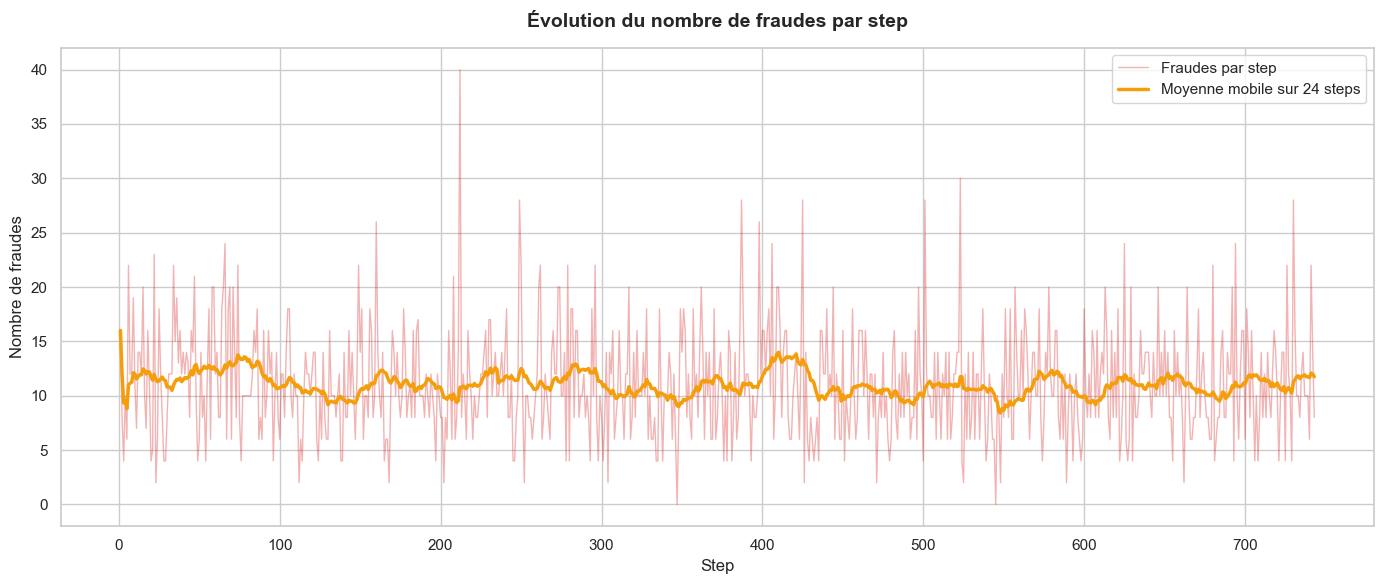

In [400]:
# Créer le graphique
fig, ax = plt.subplots(
    figsize=(14, 6)
)

# Tracer les fraudes
ax.plot(
    temporal_stats.index,
    temporal_stats["Fraudes"],
    color=COLORS["fraud"],
    alpha=0.35,
    linewidth=1,
    label="Fraudes par step",
)

# Tracer la moyenne mobile
ax.plot(
    temporal_stats.index,
    temporal_stats["Fraudes MA24"],
    color=COLORS["warning"],
    linewidth=2.5,
    label="Moyenne mobile sur 24 steps",
)

# Configurer le graphique
ax.set_title(
    "Évolution du nombre de fraudes par step",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel("Step")
ax.set_ylabel("Nombre de fraudes")

ax.legend()

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "13_fraud_count_by_step.png"
)

plt.show()

Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\14_fraud_rate_by_step.png


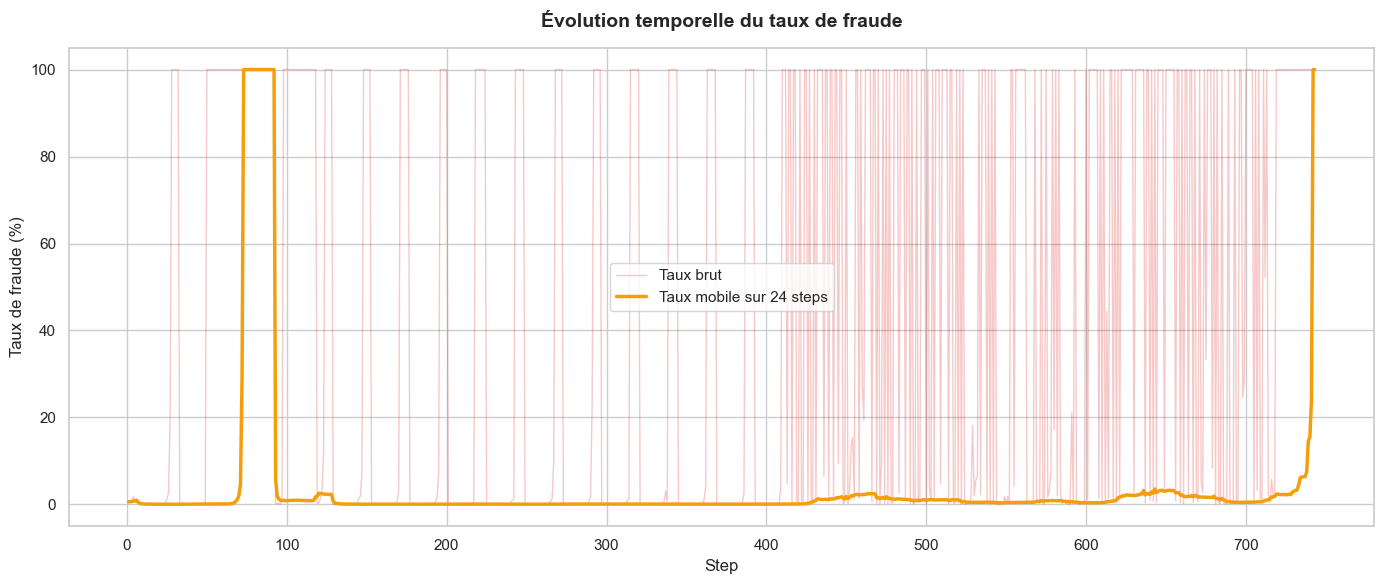

In [401]:
# Créer le graphique
fig, ax = plt.subplots(
    figsize=(14, 6)
)

# Tracer le taux brut
ax.plot(
    temporal_stats.index,
    temporal_stats["Taux de fraude (%)"],
    color=COLORS["fraud"],
    alpha=0.25,
    linewidth=1,
    label="Taux brut",
)

# Tracer le taux mobile
ax.plot(
    temporal_stats.index,
    temporal_stats["Taux fraude mobile 24 steps (%)"],
    color=COLORS["warning"],
    linewidth=2.5,
    label="Taux mobile sur 24 steps",
)

# Configurer le graphique
ax.set_title(
    "Évolution temporelle du taux de fraude",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel("Step")
ax.set_ylabel("Taux de fraude (%)")

ax.legend()

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "14_fraud_rate_by_step.png"
)

plt.show()

In [402]:
# Identifier les steps les plus actifs
top_transaction_steps = (
    temporal_stats
    .nlargest(
        10,
        "Transactions",
    )
    [
        [
            "Transactions",
            "Fraudes",
            "Taux de fraude (%)",
        ]
    ]
)

# Afficher les résultats
display(top_transaction_steps)

,Transactions,Fraudes,Taux de fraude (%)
step,,,
19,51352,11,0.02
18,49579,16,0.03
187,49083,10,0.02
235,47491,10,0.02
307,46968,16,0.03
163,46352,8,0.02
139,46054,4,0.01
403,45155,16,0.04
43,45060,13,0.03


In [403]:
# Identifier les principaux pics de fraude
top_fraud_steps = (
    temporal_stats
    .nlargest(
        10,
        "Fraudes",
    )
    [
        [
            "Transactions",
            "Fraudes",
            "Taux de fraude (%)",
        ]
    ]
)

# Afficher les résultats
display(top_fraud_steps)

,Transactions,Fraudes,Taux de fraude (%)
step,,,
212,34047,40,0.12
523,30,30,100.00
249,23209,28,0.12
387,28,28,100.00
425,28,28,100.00
501,28,28,100.00
730,28,28,100.00
160,27765,26,0.09
398,26656,26,0.10


In [404]:
# Sélectionner les steps actifs
active_steps = temporal_stats.loc[
    temporal_stats["Transactions"] > 0
].copy()

# Calculer le seuil minimum de volume
minimum_step_volume = (
    active_steps["Transactions"]
    .quantile(0.25)
)

# Filtrer les steps suffisamment actifs
reliable_rate_steps = active_steps.loc[
    active_steps["Transactions"]
    >= minimum_step_volume
]

# Identifier les taux les plus élevés
top_fraud_rate_steps = (
    reliable_rate_steps
    .nlargest(
        10,
        "Taux de fraude (%)",
    )
    [
        [
            "Transactions",
            "Fraudes",
            "Taux de fraude (%)",
        ]
    ]
)

# Afficher le seuil
print(
    f"Volume minimum retenu : "
    f"{minimum_step_volume:,.0f} transactions"
)

# Afficher les résultats
display(top_fraud_rate_steps)

Volume minimum retenu : 12 transactions


,Transactions,Fraudes,Taux de fraude (%)
step,,,
31,12,12,100.00
32,12,12,100.00
51,14,14,100.00
55,12,12,100.00
56,18,18,100.00
58,20,20,100.00
59,20,20,100.00
60,12,12,100.00
61,14,14,100.00


In [405]:
# Définir les bornes temporelles
step_min = df["step"].min()
step_max = df["step"].max()

# Créer quatre périodes chronologiques
period_labels = [
    "Période 1",
    "Période 2",
    "Période 3",
    "Période 4",
]

period_data = df[
    [
        "step",
        "isFraud",
        "amount",
    ]
].copy()

# Créer les périodes
period_data["Période"] = pd.cut(
    period_data["step"],
    bins=4,
    labels=period_labels,
    include_lowest=True,
)

# Calculer les statistiques
period_summary = (
    period_data
    .groupby(
        "Période",
        observed=True,
    )
    .agg(
        Transactions=("isFraud", "size"),
        Fraudes=("isFraud", "sum"),
        Montant_médian=("amount", "median"),
    )
    .reset_index()
)

# Calculer le taux de fraude
period_summary["Taux de fraude (%)"] = (
    100
    * period_summary["Fraudes"]
    / period_summary["Transactions"]
)

# Afficher le tableau
display(period_summary)

,Période,Transactions,Fraudes,Montant_médian,Taux de fraude (%)
0,Période 1,2247887,2122,"79,055.66",0.09
1,Période 2,3038001,2031,"72,735.76",0.07
2,Période 3,882793,1998,"73,220.42",0.23
3,Période 4,193939,2062,"71,625.47",1.06


Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\15_fraud_rate_by_period.png


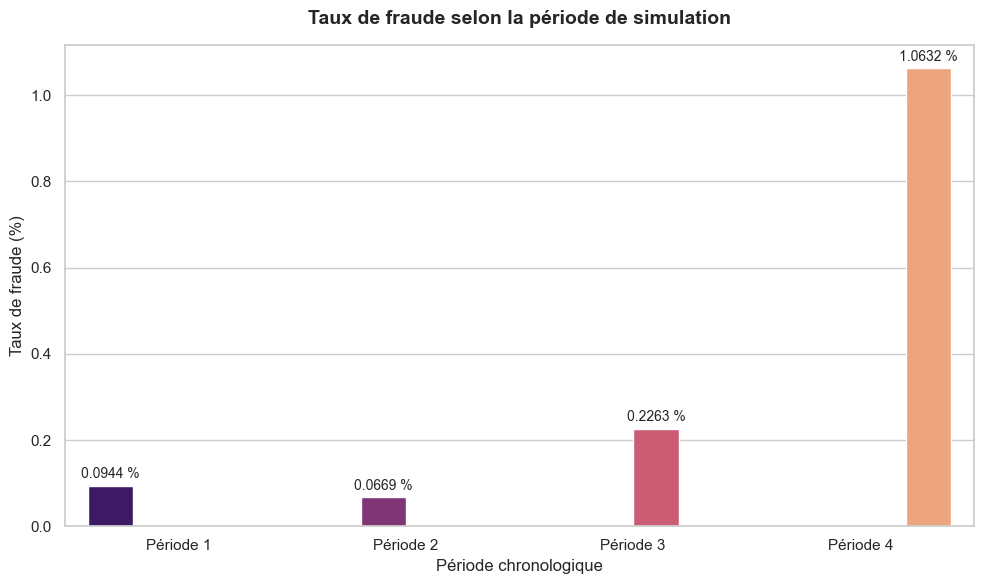

In [406]:
# Créer le graphique
fig, ax = plt.subplots(
    figsize=(10, 6)
)

sns.barplot(
    data=period_summary,
    x="Période",
    y="Taux de fraude (%)",
    hue="Période",
    palette="magma",
    legend=False,
    ax=ax,
)

# Ajouter les valeurs
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.4f %%",
        padding=3,
        fontsize=10,
    )

# Configurer le graphique
ax.set_title(
    "Taux de fraude selon la période de simulation",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel("Période chronologique")
ax.set_ylabel("Taux de fraude (%)")

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "15_fraud_rate_by_period.png"
)

plt.show()

In [407]:
# Créer la position dans le cycle
cycle_data = df[
    [
        "step",
        "isFraud",
    ]
].copy()

cycle_data["Position cycle"] = (
    (cycle_data["step"] - 1)
    % 24
)

# Calculer les statistiques
cycle_summary = (
    cycle_data
    .groupby(
        "Position cycle",
        observed=True,
    )
    .agg(
        Transactions=("isFraud", "size"),
        Fraudes=("isFraud", "sum"),
    )
    .reset_index()
)

# Calculer le taux de fraude
cycle_summary["Taux de fraude (%)"] = (
    100
    * cycle_summary["Fraudes"]
    / cycle_summary["Transactions"]
)

# Afficher le tableau
display(cycle_summary)

,Position cycle,Transactions,Fraudes,Taux de fraude (%)
0,0,27111,358,1.32
1,1,9018,372,4.13
2,2,2007,326,16.24
3,3,1241,274,22.08
4,4,1641,366,22.30
5,5,3420,358,10.47
6,6,8988,328,3.65
7,7,26915,368,1.37
8,8,283518,341,0.12
9,9,425729,375,0.09


Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\16_fraud_rate_by_cycle_position.png


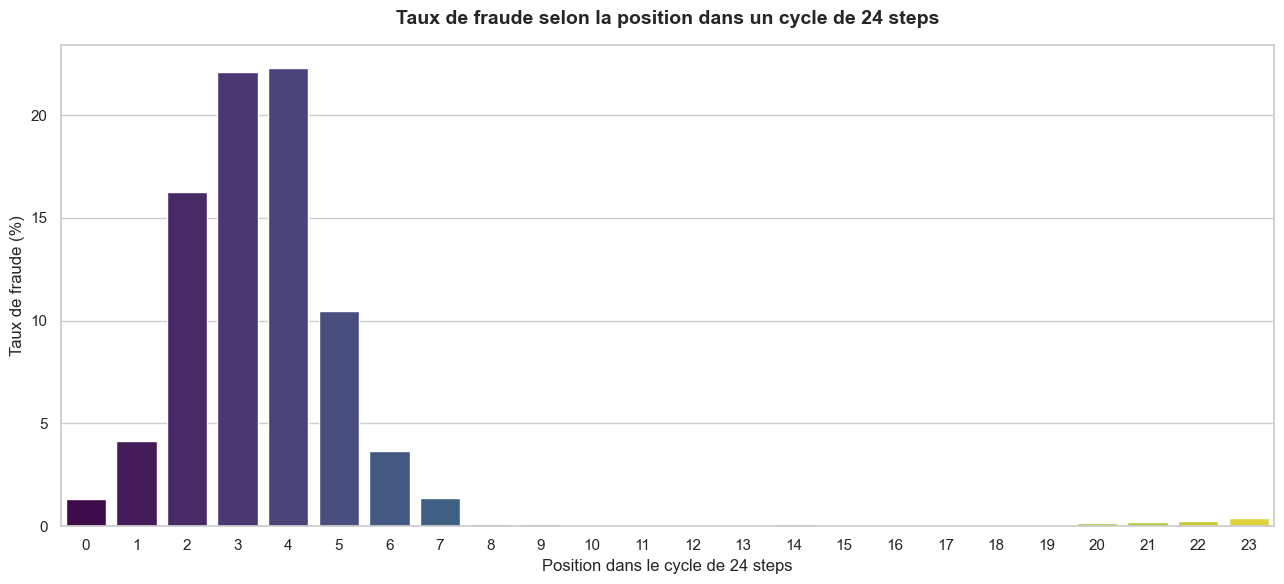

In [408]:
# Créer le graphique
fig, ax = plt.subplots(
    figsize=(13, 6)
)

sns.barplot(
    data=cycle_summary,
    x="Position cycle",
    y="Taux de fraude (%)",
    hue="Position cycle",
    palette="viridis",
    legend=False,
    ax=ax,
)

# Configurer le graphique
ax.set_title(
    "Taux de fraude selon la position dans un cycle de 24 steps",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel(
    "Position dans le cycle de 24 steps"
)

ax.set_ylabel(
    "Taux de fraude (%)"
)

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "16_fraud_rate_by_cycle_position.png"
)

plt.show()

In [409]:
# Compter les steps actifs
total_active_steps = int(
    (
        temporal_stats["Transactions"] > 0
    ).sum()
)

# Compter les steps avec fraude
fraud_active_steps = int(
    (
        temporal_stats["Fraudes"] > 0
    ).sum()
)

# Calculer la proportion
fraud_step_rate = (
    100
    * fraud_active_steps
    / total_active_steps
)

# Afficher les résultats
print(
    f"Steps avec activité : "
    f"{total_active_steps:,}"
)

print(
    f"Steps contenant au moins une fraude : "
    f"{fraud_active_steps:,}"
)

print(
    f"Part des steps contenant une fraude : "
    f"{fraud_step_rate:.2f} %"
)

Steps avec activité : 743
Steps contenant au moins une fraude : 741
Part des steps contenant une fraude : 99.73 %


In [410]:
# Identifier les steps contenant une fraude
fraud_steps = (
    temporal_stats
    .loc[
        temporal_stats["Fraudes"] > 0
    ]
    .index
    .to_numpy()
)

# Calculer les écarts
fraud_step_gaps = np.diff(
    fraud_steps
)

# Créer le résumé
if len(fraud_step_gaps) > 0:
    fraud_gap_summary = pd.Series(
        fraud_step_gaps,
        name="Écart entre steps frauduleux",
    ).describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
        ]
    )

    display(
        fraud_gap_summary.to_frame()
    )

else:
    print(
        "Pas assez de steps frauduleux "
        "pour calculer les écarts."
    )

,Écart entre steps frauduleux
count,740.00
mean,1.00
std,0.05
min,1.00
25%,1.00
50%,1.00
75%,1.00
90%,1.00
95%,1.00
99%,1.00


Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\17_fraud_step_gap_distribution.png


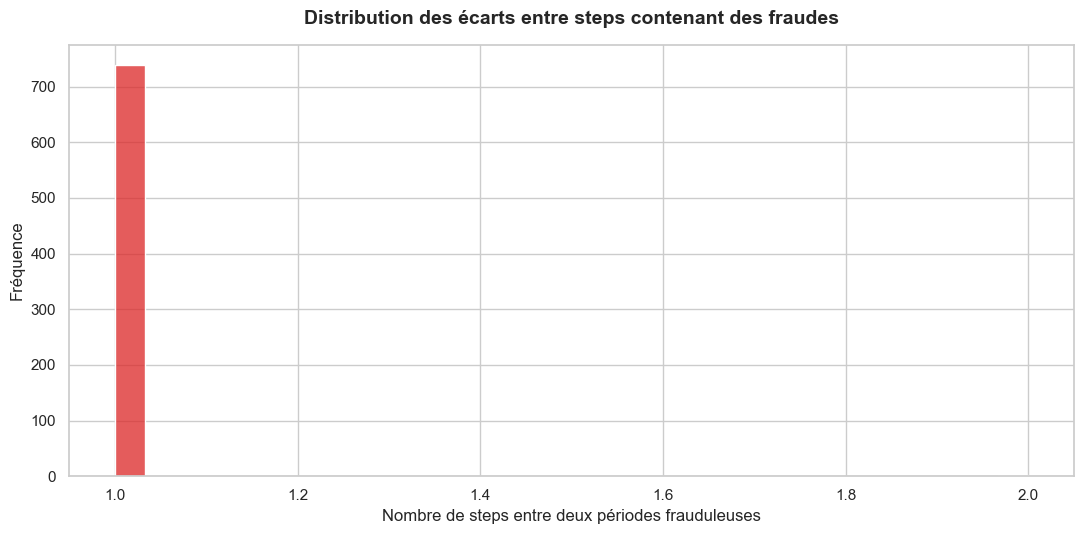

In [411]:
# Vérifier la présence des écarts
if len(fraud_step_gaps) > 0:

    # Créer le graphique
    fig, ax = plt.subplots(
        figsize=(11, 5.5)
    )

    sns.histplot(
        fraud_step_gaps,
        bins=30,
        color=COLORS["fraud"],
        ax=ax,
    )

    # Configurer le graphique
    ax.set_title(
        "Distribution des écarts entre steps contenant des fraudes",
        fontsize=14,
        fontweight="bold",
        pad=15,
    )

    ax.set_xlabel(
        "Nombre de steps entre deux périodes frauduleuses"
    )

    ax.set_ylabel(
        "Fréquence"
    )

    plt.tight_layout()

    # Enregistrer le graphique
    save_figure(
        "17_fraud_step_gap_distribution.png"
    )

    plt.show()

In [412]:
# Identifier le step avec le plus de fraudes
peak_fraud_step = (
    temporal_stats["Fraudes"]
    .idxmax()
)

peak_fraud_count = int(
    temporal_stats.loc[
        peak_fraud_step,
        "Fraudes",
    ]
)

# Identifier la période la plus risquée
highest_risk_period = (
    period_summary
    .sort_values(
        "Taux de fraude (%)",
        ascending=False,
    )
    .iloc[0]
)

# Identifier la position de cycle la plus risquée
highest_risk_cycle = (
    cycle_summary
    .sort_values(
        "Taux de fraude (%)",
        ascending=False,
    )
    .iloc[0]
)

# Afficher le résumé
print(
    f"Step avec le plus de fraudes : "
    f"{peak_fraud_step}"
)

print(
    f"Nombre de fraudes sur ce step : "
    f"{peak_fraud_count:,}"
)

print(
    f"Période avec le taux de fraude le plus élevé : "
    f"{highest_risk_period['Période']}"
)

print(
    f"Taux correspondant : "
    f"{highest_risk_period['Taux de fraude (%)']:.4f} %"
)

print(
    f"Position du cycle la plus risquée : "
    f"{int(highest_risk_cycle['Position cycle'])}"
)

print(
    f"Taux correspondant : "
    f"{highest_risk_cycle['Taux de fraude (%)']:.4f} %"
)

Step avec le plus de fraudes : 212
Nombre de fraudes sur ce step : 40
Période avec le taux de fraude le plus élevé : Période 4
Taux correspondant : 1.0632 %
Position du cycle la plus risquée : 4
Taux correspondant : 22.3035 %


In [413]:
# Enregistrer les statistiques temporelles
temporal_stats.reset_index().to_csv(
    tables_dir / "temporal_stats_by_step.csv",
    index=False,
    encoding="utf-8-sig",
)

# Enregistrer les périodes
period_summary.to_csv(
    tables_dir / "fraud_summary_by_period.csv",
    index=False,
    encoding="utf-8-sig",
)

# Enregistrer le cycle
cycle_summary.to_csv(
    tables_dir / "fraud_summary_by_cycle.csv",
    index=False,
    encoding="utf-8-sig",
)

# Enregistrer les principaux pics
top_fraud_steps.to_csv(
    tables_dir / "top_fraud_steps.csv",
    encoding="utf-8-sig",
)

print(
    "Résultats temporels enregistrés."
)

Résultats temporels enregistrés.


## Conclusion de l’analyse temporelle

### Observation

L’activité transactionnelle varie fortement au cours de la simulation.

Le nombre de transactions est particulièrement élevé durant les deux premières
périodes, avec plus de 2,2 millions puis 3 millions d’opérations. Il diminue
ensuite fortement pour atteindre environ 194 000 transactions dans la dernière
période.

À l’inverse, le nombre de fraudes reste relativement stable entre les quatre
périodes, avec environ 2 000 fraudes par période.

Le taux de fraude passe ainsi de 0,0944 % dans la première période à 1,0632 %
dans la dernière.

Le step 212 présente le nombre absolu de fraudes le plus élevé avec 40
transactions frauduleuses.

### Interprétation métier

L’augmentation du taux de fraude en fin de simulation ne correspond pas
principalement à une explosion du nombre de fraudes.

Elle résulte surtout de la forte diminution du nombre de transactions
légitimes tandis que le nombre de fraudes reste relativement stable.

Cette distinction est importante : un taux élevé n’indique pas nécessairement
une augmentation absolue de l’activité frauduleuse.

L’analyse du cycle de 24 steps montre également des taux de fraude très élevés
pour certaines positions de faible activité. La position 4 présente par
exemple le taux observé le plus important, autour de 22,3 %, mais elle ne
contient qu’environ 1 600 transactions.

Ces résultats doivent donc toujours être interprétés conjointement avec le
volume transactionnel.

### Limite liée au dataset

Cette structure temporelle peut être en partie liée au mécanisme de simulation
de PaySim.

Il serait donc imprudent d’interpréter les positions du cycle comme des heures
réelles présentant intrinsèquement davantage de fraude dans un environnement
Mobile Money réel.

L’intérêt principal de la variable `step` réside dans l’ordre chronologique
qu’elle fournit aux transactions.

### Impact sur le Feature Engineering

Les variables temporelles candidates comprennent :

- position dans un cycle de 24 steps ;
- nombre de transactions récentes du compte ;
- volume envoyé sur une fenêtre récente ;
- volume reçu sur une fenêtre récente ;
- temps depuis la dernière transaction ;
- nombre de destinataires récents ;
- fréquence récente de vidage du compte ;
- variation récente de l’activité du compte.

Ces variables devront être calculées uniquement à partir du passé afin
d’éviter toute fuite d’information temporelle.

### Impact sur les modèles Machine Learning

Le temps ne devra pas être utilisé uniquement comme une variable numérique
brute.

Les modèles classiques pourront bénéficier de caractéristiques décrivant
l’activité récente et le comportement historique du compte.

L’évaluation principale utilisera un découpage chronologique plutôt qu’un
split aléatoire.

### Impact sur le Dynamic Graph Learning

L’analyse confirme l’intérêt d’une représentation événementielle des
transactions :

(source, destination, timestamp, attributs)

Les modèles de graphes dynamiques pourront ainsi exploiter :

- l’ordre des interactions ;
- le temps entre deux transactions ;
- l’évolution du voisinage d’un compte ;
- les séquences rapides de transferts ;
- la répétition des interactions ;
- l’évolution des comportements au cours du temps.

### Décision retenue

- Conserver `step` comme timestamp principal.
- Utiliser un split chronologique.
- Comparer systématiquement taux de fraude et volume transactionnel.
- Ne pas interpréter une position du cycle comme une heure réelle à risque.
- Créer des features temporelles historiques dans le Notebook 03.
- Préserver l’ordre exact des événements pour le futur modèle dynamique.

# 6. Analyse des types de transactions

## Question métier

Certains types d'opérations Mobile Money présentent-ils un risque de fraude
plus important que les autres ?

Cette section analyse :

- la fréquence de chaque type de transaction ;
- le nombre de fraudes par type ;
- le taux de fraude par type ;
- la contribution de chaque type à l'ensemble des fraudes ;
- les différences de montant entre les types ;
- le lien entre le type de transaction et le vidage complet du compte.

L'objectif est d'identifier les catégories transactionnelles les plus risquées
sans construire une règle trop spécifique au dataset PaySim.

In [414]:
# Calculer la distribution des types
type_summary = (
    df["type"]
    .value_counts()
    .rename_axis("Type")
    .reset_index(name="Transactions")
)

# Calculer les pourcentages
type_summary["Part (%)"] = (
    100
    * type_summary["Transactions"]
    / len(df)
)

# Afficher le tableau
display(type_summary)

,Type,Transactions,Part (%)
0,CASH_OUT,2237500,35.17
1,PAYMENT,2151495,33.81
2,CASH_IN,1399284,21.99
3,TRANSFER,532909,8.38
4,DEBIT,41432,0.65


Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\18_transaction_distribution_by_type.png


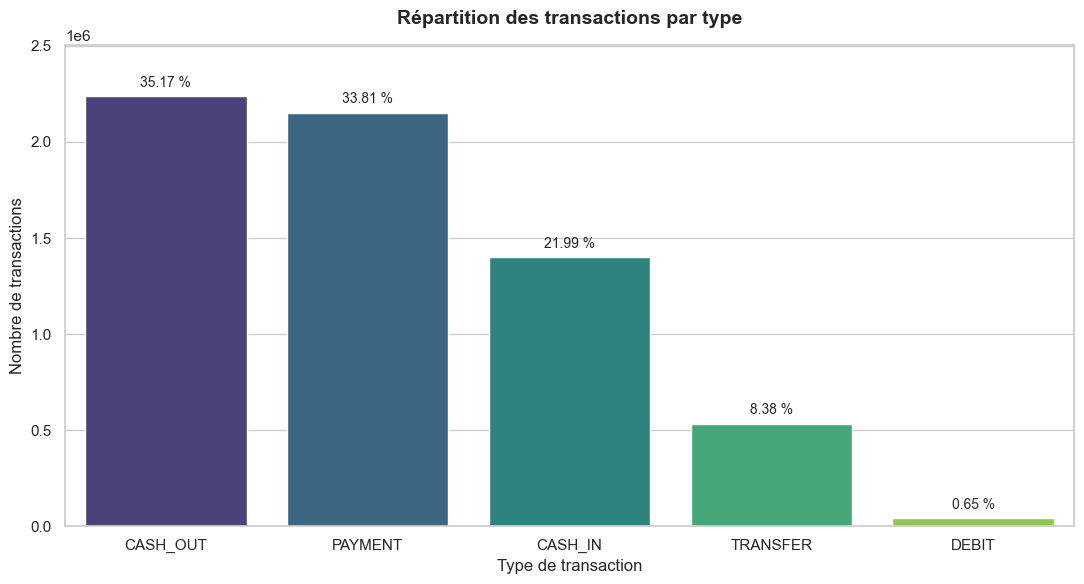

In [415]:
# Créer le graphique
fig, ax = plt.subplots(
    figsize=(11, 6)
)

sns.barplot(
    data=type_summary,
    x="Type",
    y="Transactions",
    hue="Type",
    palette="viridis",
    legend=False,
    ax=ax,
)

# Ajouter les pourcentages
for index, row in type_summary.iterrows():
    ax.text(
        index,
        row["Transactions"]
        + type_summary["Transactions"].max() * 0.015,
        f'{row["Part (%)"]:.2f} %',
        ha="center",
        va="bottom",
        fontsize=10,
    )

# Ajouter une marge
ax.set_ylim(
    0,
    type_summary["Transactions"].max() * 1.12,
)

# Configurer le graphique
ax.set_title(
    "Répartition des transactions par type",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel("Type de transaction")
ax.set_ylabel("Nombre de transactions")

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "18_transaction_distribution_by_type.png"
)

plt.show()

In [416]:
# Calculer les statistiques par type
fraud_by_type = (
    df.groupby(
        "type",
        observed=True,
    )
    .agg(
        Transactions=("isFraud", "size"),
        Fraudes=("isFraud", "sum"),
    )
    .reset_index()
)

# Calculer le taux de fraude
fraud_by_type["Taux de fraude (%)"] = (
    100
    * fraud_by_type["Fraudes"]
    / fraud_by_type["Transactions"]
)

# Calculer la contribution aux fraudes
fraud_by_type["Part des fraudes (%)"] = (
    100
    * fraud_by_type["Fraudes"]
    / df["isFraud"].sum()
)

# Trier par nombre de fraudes
fraud_by_type = (
    fraud_by_type
    .sort_values(
        "Fraudes",
        ascending=False,
    )
    .reset_index(drop=True)
)

# Afficher le tableau
display(fraud_by_type)

,type,Transactions,Fraudes,Taux de fraude (%),Part des fraudes (%)
0,CASH_OUT,2237500,4116,0.18,50.12
1,TRANSFER,532909,4097,0.77,49.88
2,CASH_IN,1399284,0,0.00,0.00
3,DEBIT,41432,0,0.00,0.00
4,PAYMENT,2151495,0,0.00,0.00


Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\19_fraud_rate_by_transaction_type.png


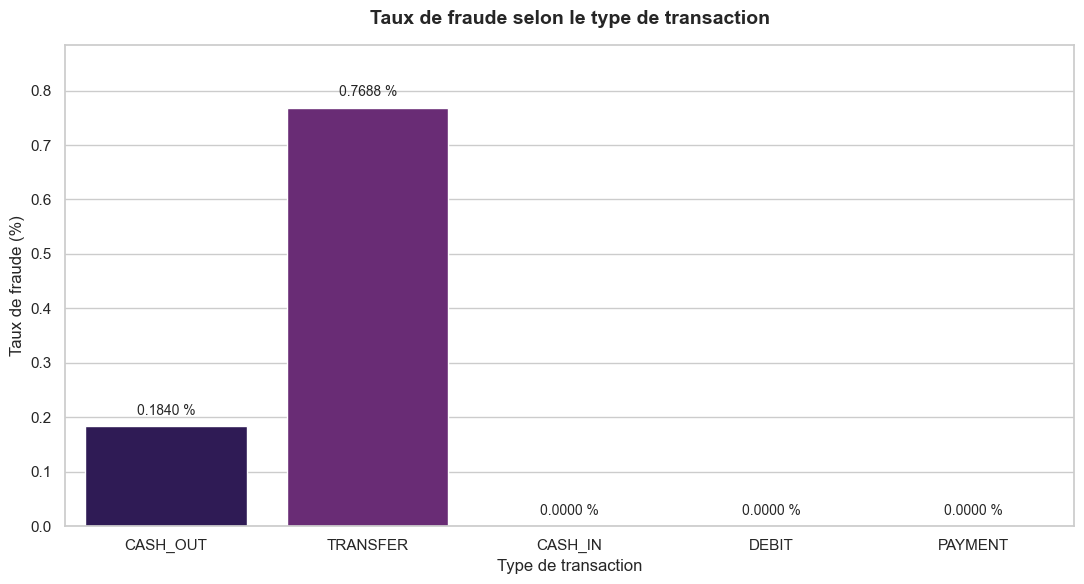

In [417]:
# Créer le graphique
fig, ax = plt.subplots(
    figsize=(11, 6)
)

sns.barplot(
    data=fraud_by_type,
    x="type",
    y="Taux de fraude (%)",
    hue="type",
    palette="magma",
    legend=False,
    ax=ax,
)

# Ajouter les valeurs
for index, row in fraud_by_type.iterrows():
    ax.text(
        index,
        row["Taux de fraude (%)"]
        + fraud_by_type["Taux de fraude (%)"].max() * 0.02,
        f'{row["Taux de fraude (%)"]:.4f} %',
        ha="center",
        va="bottom",
        fontsize=10,
    )

# Ajouter une marge
ax.set_ylim(
    0,
    fraud_by_type["Taux de fraude (%)"].max() * 1.15,
)

# Configurer le graphique
ax.set_title(
    "Taux de fraude selon le type de transaction",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel("Type de transaction")
ax.set_ylabel("Taux de fraude (%)")

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "19_fraud_rate_by_transaction_type.png"
)

plt.show()

Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\20_fraud_contribution_by_type.png


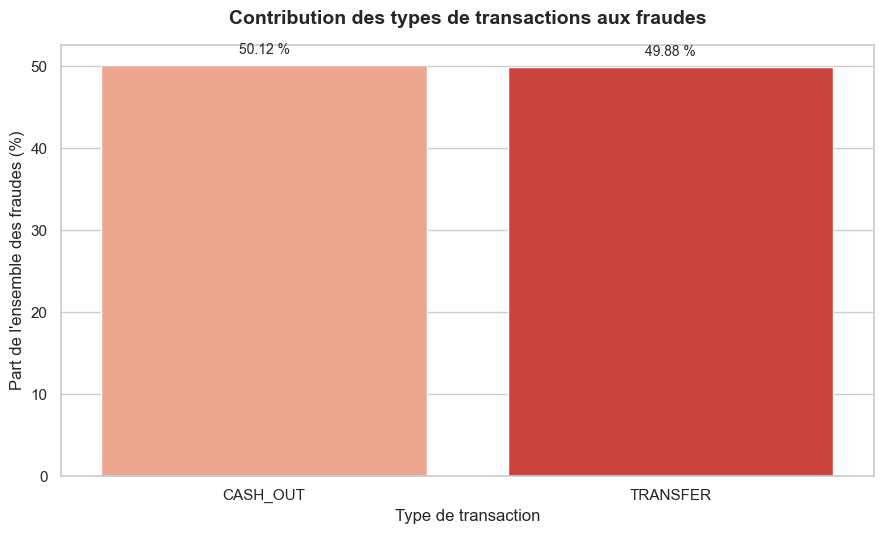

In [418]:
# Sélectionner les types avec fraude
fraud_contribution = fraud_by_type.loc[
    fraud_by_type["Fraudes"] > 0
].copy()

# Créer le graphique
fig, ax = plt.subplots(
    figsize=(9, 5.5)
)

sns.barplot(
    data=fraud_contribution,
    x="type",
    y="Part des fraudes (%)",
    hue="type",
    palette="Reds",
    legend=False,
    ax=ax,
)

# Ajouter les pourcentages
for index, row in fraud_contribution.iterrows():
    ax.text(
        index,
        row["Part des fraudes (%)"] + 1,
        f'{row["Part des fraudes (%)"]:.2f} %',
        ha="center",
        va="bottom",
        fontsize=10,
    )

# Configurer le graphique
ax.set_title(
    "Contribution des types de transactions aux fraudes",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel("Type de transaction")
ax.set_ylabel("Part de l'ensemble des fraudes (%)")

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "20_fraud_contribution_by_type.png"
)

plt.show()

In [419]:
# Calculer les statistiques de montant
amount_type_class = (
    df.groupby(
        [
            "type",
            "isFraud",
        ],
        observed=True,
    )
    .agg(
        Transactions=("amount", "size"),
        Montant_moyen=("amount", "mean"),
        Montant_médian=("amount", "median"),
        P95=(
            "amount",
            lambda values: values.quantile(0.95),
        ),
    )
    .reset_index()
)

# Renommer les classes
amount_type_class["Classe"] = (
    amount_type_class["isFraud"]
    .map(
        {
            0: "Légitime",
            1: "Fraude",
        }
    )
)

# Afficher le tableau
display(
    amount_type_class[
        [
            "type",
            "Classe",
            "Transactions",
            "Montant_moyen",
            "Montant_médian",
            "P95",
        ]
    ]
)

,type,Classe,Transactions,Montant_moyen,Montant_médian,P95
0,CASH_IN,Légitime,1399284,"168,920.24","143,427.71","412,005.13"
1,CASH_OUT,Légitime,2233384,"173,917.16","146,946.56","426,154.64"
2,CASH_OUT,Fraude,4116,"1,455,102.59","435,516.91","7,841,465.04"
3,DEBIT,Légitime,41432,"5,483.67","3,048.99","14,795.35"
4,PAYMENT,Légitime,2151495,"13,057.60","9,482.19","37,835.66"
5,TRANSFER,Légitime,528812,"906,229.01","486,521.91","2,646,555.80"
6,TRANSFER,Fraude,4097,"1,480,891.67","445,705.76","8,098,658.15"


In [420]:
# Sélectionner les types à risque
risky_types = [
    "TRANSFER",
    "CASH_OUT",
]

# Filtrer les transactions
risky_type_data = df.loc[
    df["type"].isin(risky_types)
].copy()

# Créer les labels
risky_type_data["Classe"] = (
    risky_type_data["isFraud"]
    .map(
        {
            0: "Légitime",
            1: "Fraude",
        }
    )
)

# Créer le montant logarithmique
risky_type_data["log_amount"] = np.log1p(
    risky_type_data["amount"]
)

Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\21_amount_by_risky_type_and_class.png


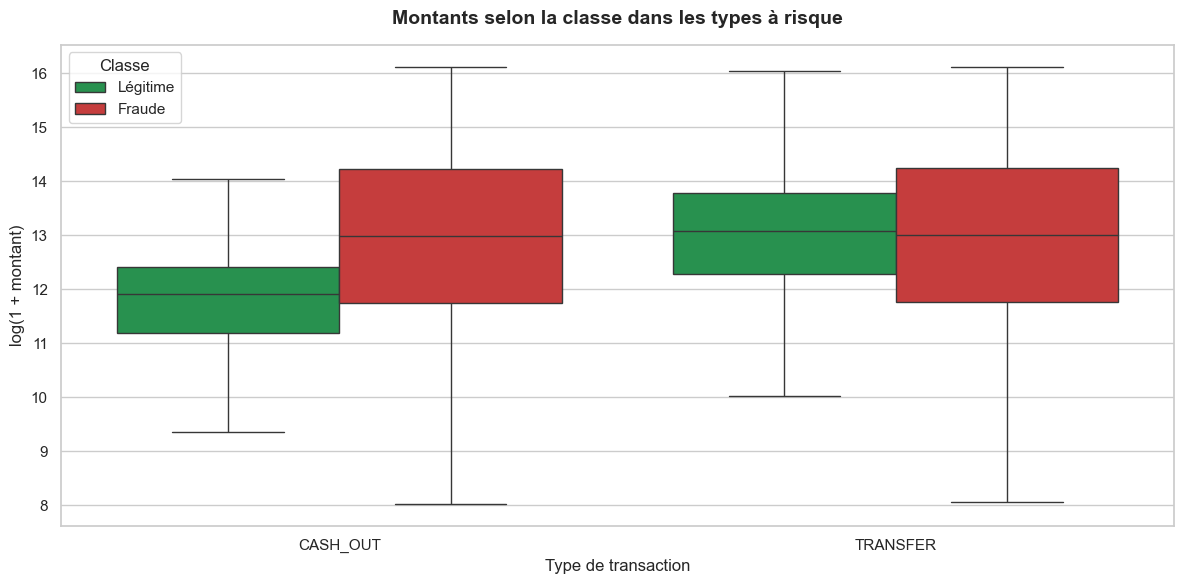

In [421]:
# Sélectionner toutes les fraudes
risky_fraud = risky_type_data.loc[
    risky_type_data["isFraud"] == 1
]

# Sélectionner les transactions légitimes
risky_legitimate = risky_type_data.loc[
    risky_type_data["isFraud"] == 0
]

# Échantillonner les transactions légitimes
risky_legitimate_sample = risky_legitimate.sample(
    n=min(
        100_000,
        len(risky_legitimate),
    ),
    random_state=RANDOM_STATE,
)

# Combiner les données
risky_plot_data = pd.concat(
    [
        risky_legitimate_sample,
        risky_fraud,
    ],
    ignore_index=True,
)

# Créer le graphique
fig, ax = plt.subplots(
    figsize=(12, 6)
)

sns.boxplot(
    data=risky_plot_data,
    x="type",
    y="log_amount",
    hue="Classe",
    hue_order=[
        "Légitime",
        "Fraude",
    ],
    palette=class_palette,
    showfliers=False,
    ax=ax,
)

# Configurer le graphique
ax.set_title(
    "Montants selon la classe dans les types à risque",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel("Type de transaction")
ax.set_ylabel("log(1 + montant)")

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "21_amount_by_risky_type_and_class.png"
)

plt.show()

In [422]:
# Définir la tolérance
balance_tolerance = 0.01

# Identifier les transferts correspondant au solde
amount_equals_balance = (
    (df["oldbalanceOrg"] > 0)
    & np.isclose(
        df["amount"],
        df["oldbalanceOrg"],
        atol=balance_tolerance,
        rtol=0,
    )
)

# Identifier les comptes vidés
origin_emptied_type = (
    (df["oldbalanceOrg"] > 0)
    & (df["newbalanceOrig"] == 0)
)

# Identifier les transferts complets
full_balance_type = (
    amount_equals_balance
    & origin_emptied_type
)

# Créer les données temporaires
type_pattern_data = pd.DataFrame(
    {
        "type": df["type"],
        "isFraud": df["isFraud"],
        "Full balance transfer": full_balance_type,
    }
)

In [423]:
# Calculer les statistiques
full_balance_by_type = (
    type_pattern_data
    .groupby(
        [
            "type",
            "isFraud",
        ],
        observed=True,
    )
    .agg(
        Transactions=(
            "isFraud",
            "size",
        ),
        Transferts_totaux=(
            "Full balance transfer",
            "sum",
        ),
    )
    .reset_index()
)

# Calculer les pourcentages
full_balance_by_type[
    "Taux transfert total (%)"
] = (
    100
    * full_balance_by_type["Transferts_totaux"]
    / full_balance_by_type["Transactions"]
)

# Renommer les classes
full_balance_by_type["Classe"] = (
    full_balance_by_type["isFraud"]
    .map(
        {
            0: "Légitime",
            1: "Fraude",
        }
    )
)

# Afficher le tableau
display(
    full_balance_by_type[
        [
            "type",
            "Classe",
            "Transactions",
            "Transferts_totaux",
            "Taux transfert total (%)",
        ]
    ]
)

,type,Classe,Transactions,Transferts_totaux,Taux transfert total (%)
0,CASH_IN,Légitime,1399284,0,0.00
1,CASH_OUT,Légitime,2233384,0,0.00
2,CASH_OUT,Fraude,4116,4075,99.00
3,DEBIT,Légitime,41432,0,0.00
4,PAYMENT,Légitime,2151495,0,0.00
5,TRANSFER,Légitime,528812,0,0.00
6,TRANSFER,Fraude,4097,3933,96.00


Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\22_full_balance_transfer_by_type.png


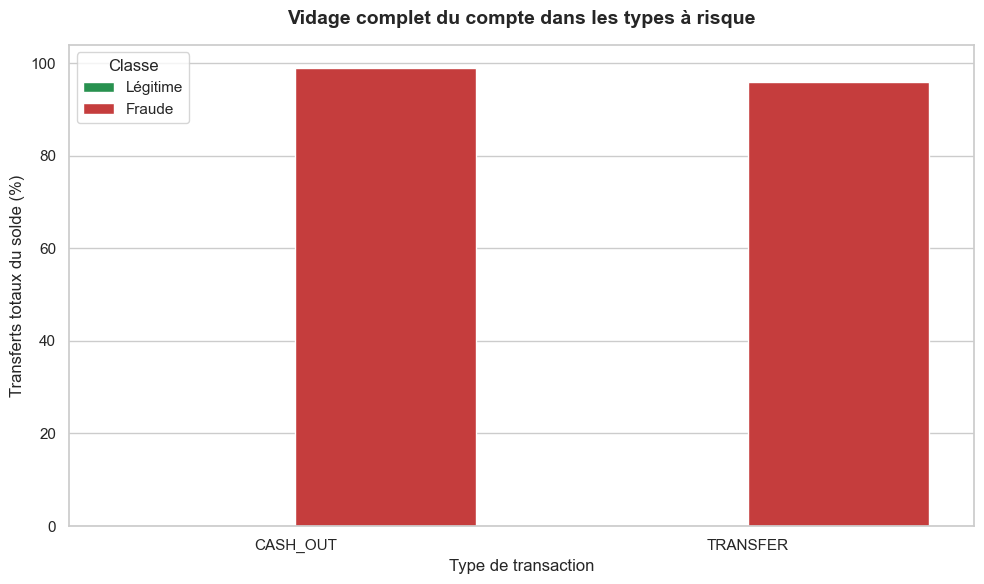

In [424]:
# Sélectionner les types à risque
full_balance_risky = (
    full_balance_by_type
    .loc[
        full_balance_by_type[
            "type"
        ].isin(risky_types)
    ]
)

# Créer le graphique
fig, ax = plt.subplots(
    figsize=(10, 6)
)

sns.barplot(
    data=full_balance_risky,
    x="type",
    y="Taux transfert total (%)",
    hue="Classe",
    hue_order=[
        "Légitime",
        "Fraude",
    ],
    palette=class_palette,
    ax=ax,
)

# Configurer le graphique
ax.set_title(
    "Vidage complet du compte dans les types à risque",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel("Type de transaction")
ax.set_ylabel("Transferts totaux du solde (%)")

ax.legend(
    title="Classe"
)

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "22_full_balance_transfer_by_type.png"
)

plt.show()

In [425]:
# Importer le test statistique
from scipy.stats import chi2_contingency

# Créer la table de contingence
type_fraud_table = pd.crosstab(
    df["type"],
    df["isFraud"],
)

# Calculer le test du Chi-deux
chi2, p_value, _, _ = chi2_contingency(
    type_fraud_table
)

# Calculer le nombre d'observations
n_observations = (
    type_fraud_table
    .to_numpy()
    .sum()
)

# Calculer les dimensions
rows, columns = type_fraud_table.shape

# Calculer le V de Cramér
cramers_v = np.sqrt(
    chi2
    / (
        n_observations
        * min(
            rows - 1,
            columns - 1,
        )
    )
)

# Afficher les résultats
print(
    f"Chi-deux : {chi2:,.2f}"
)

if p_value < 1e-300:
    print(
        "p-value : < 1e-300"
    )
else:
    print(
        f"p-value : {p_value:.3e}"
    )

print(
    f"V de Cramér : {cramers_v:.4f}"
)

Chi-deux : 22,082.54
p-value : < 1e-300
V de Cramér : 0.0589


In [426]:
# Créer la synthèse
type_risk_summary = (
    fraud_by_type[
        [
            "type",
            "Transactions",
            "Fraudes",
            "Taux de fraude (%)",
            "Part des fraudes (%)",
        ]
    ]
    .copy()
)

# Ajouter le niveau de risque observé
type_risk_summary[
    "Fraude observée"
] = np.where(
    type_risk_summary["Fraudes"] > 0,
    "Oui",
    "Non",
)

# Afficher le tableau
display(type_risk_summary)

,type,Transactions,Fraudes,Taux de fraude (%),Part des fraudes (%),Fraude observée
0,CASH_OUT,2237500,4116,0.18,50.12,Oui
1,TRANSFER,532909,4097,0.77,49.88,Oui
2,CASH_IN,1399284,0,0.00,0.00,Non
3,DEBIT,41432,0,0.00,0.00,Non
4,PAYMENT,2151495,0,0.00,0.00,Non


In [427]:
# Enregistrer la distribution
type_summary.to_csv(
    tables_dir / "transaction_type_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

# Enregistrer les fraudes par type
fraud_by_type.to_csv(
    tables_dir / "fraud_by_transaction_type.csv",
    index=False,
    encoding="utf-8-sig",
)

# Enregistrer les montants
amount_type_class.to_csv(
    tables_dir / "amount_by_type_and_class.csv",
    index=False,
    encoding="utf-8-sig",
)

# Enregistrer les comportements
full_balance_by_type.to_csv(
    tables_dir / "full_balance_by_type.csv",
    index=False,
    encoding="utf-8-sig",
)

print(
    "Résultats de la section 6 enregistrés."
)

Résultats de la section 6 enregistrés.


## Conclusion de l’analyse des types de transactions

### Observation

Les 8 213 transactions frauduleuses du dataset sont exclusivement observées
dans deux catégories :

- `CASH_OUT` : 4 116 fraudes, soit 50,12 % de l'ensemble des fraudes ;
- `TRANSFER` : 4 097 fraudes, soit 49,88 %.

Cependant, ces deux types ne présentent pas le même niveau de risque.

Le taux de fraude est d'environ 0,184 % pour `CASH_OUT`, contre 0,769 % pour
`TRANSFER`. Une transaction de type `TRANSFER` présente donc un taux de fraude
environ quatre fois supérieur à celui d'une transaction `CASH_OUT`.

Aucune fraude n'est observée dans `CASH_IN`, `DEBIT` et `PAYMENT`.

### Interprétation métier

Le type de transaction apporte une information importante sur le risque.

`TRANSFER` apparaît comme le type présentant le risque conditionnel le plus
élevé, même s'il représente beaucoup moins de transactions que `CASH_OUT`.

Cependant, le type ne permet pas à lui seul d'identifier une fraude puisque
la grande majorité des transactions `TRANSFER` et `CASH_OUT` restent
légitimes.

L'interaction avec le comportement de vidage du compte est beaucoup plus
discriminante.

Environ 99 % des `CASH_OUT` frauduleux et 96 % des `TRANSFER` frauduleux
correspondent à un transfert complet du solde disponible.

### Analyse statistique

Le test du Chi-deux confirme l'existence d'une association statistiquement
significative entre le type de transaction et la fraude.

La p-value est inférieure à 1e-300.

Cependant, le V de Cramér est seulement de 0,0589, indiquant une association
globale faible.

Ce résultat s'explique notamment par l'extrême rareté de la fraude dans le
dataset. Le type apporte donc une information utile, mais ne constitue pas
une variable suffisamment discriminante lorsqu'il est étudié isolément.

### Limite liée à PaySim

L'absence totale de fraude dans `PAYMENT`, `CASH_IN` et `DEBIT` constitue une
caractéristique spécifique du dataset PaySim.

Cette structure ne doit pas être considérée comme une règle générale applicable
à tous les systèmes Mobile Money réels.

De même, la très forte association entre fraude et vidage complet du compte
peut en partie provenir du mécanisme utilisé pour générer les fraudes dans le
simulateur.

### Impact sur le Feature Engineering

Les variables candidates comprennent :

- encodage du type de transaction ;
- interaction entre `type` et `amount` ;
- interaction entre `type` et `full_balance_transfer` ;
- fréquence historique de chaque type par compte ;
- proportion récente de `TRANSFER` ;
- proportion récente de `CASH_OUT` ;
- changement inhabituel du comportement transactionnel d'un compte.

### Impact sur les modèles Machine Learning

La variable `type` sera conservée comme variable catégorielle.

Les modèles devront apprendre ses interactions avec le montant, les soldes
et le comportement de vidage du compte.

Une étude d'ablation pourra également comparer les performances avec et sans
les variables très spécifiques au mécanisme de simulation PaySim.

### Impact sur les Graph Neural Networks

Le type de transaction pourra être représenté comme un attribut d'arête.

Chaque interaction du graphe pourra ainsi être décrite par :

- le compte source ;
- le compte destination ;
- le type de transaction ;
- le montant ;
- les soldes ;
- le timestamp ;
- les indicateurs comportementaux.

Le modèle pourra alors apprendre non seulement qu'un transfert est risqué,
mais surtout dans quel contexte relationnel et temporel il devient suspect.

### Décision retenue

- Conserver `type` comme variable explicative.
- Utiliser `type` comme attribut d'arête dans le graphe.
- Ne pas exclure `PAYMENT`, `CASH_IN` ou `DEBIT` du dataset.
- Ne pas attribuer manuellement un label de risque selon le type.
- Créer des interactions entre type, montant et vidage du compte.
- Étudier plus tard la dépendance des modèles aux patterns spécifiques de
  PaySim.

# 7. Analyse comportementale des comptes

## Question métier

Certains comptes présentent-ils des comportements transactionnels atypiques ou
une implication particulière dans les fraudes ?

Jusqu'à présent, les analyses ont principalement étudié chaque transaction
individuellement.

Cette section change de niveau d'analyse en s'intéressant aux comptes présents
dans :

- `nameOrig` : compte à l'origine de la transaction ;
- `nameDest` : compte destinataire.

L'objectif est d'étudier :

- le nombre de transactions émises et reçues ;
- les comptes les plus actifs ;
- les volumes financiers envoyés et reçus ;
- les comptes impliqués dans des fraudes ;
- la répétition éventuelle des interactions frauduleuses ;
- les destinations récurrentes des transactions frauduleuses.

Cette analyse prépare directement la future représentation en graphe :

- compte = nœud ;
- transaction = arête orientée ;
- montant, type et timestamp = attributs de l'arête.

In [428]:
# Compter les transactions émises
origin_activity = (
    df["nameOrig"]
    .value_counts()
    .rename("Transactions émises")
)

# Afficher les statistiques
origin_activity_summary = (
    origin_activity
    .describe(
        percentiles=[
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
        ]
    )
    .to_frame()
)

display(origin_activity_summary)

,Transactions émises
count,"6,353,307.00"
mean,1.00
std,0.04
min,1.00
50%,1.00
75%,1.00
90%,1.00
95%,1.00
99%,1.00
max,3.00


In [429]:
# Sélectionner les comptes les plus actifs
top_origin_accounts = (
    origin_activity
    .head(20)
    .reset_index()
)

# Renommer les colonnes
top_origin_accounts.columns = [
    "Compte",
    "Transactions émises",
]

# Afficher le tableau
display(top_origin_accounts)

,Compte,Transactions émises
0,C2098525306,3
1,C400299098,3
2,C1999539787,3
3,C1065307291,3
4,C545315117,3
5,C1976208114,3
6,C1784010646,3
7,C1530544995,3
8,C1902386530,3
9,C1677795071,3


Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\23_top_origin_accounts.png


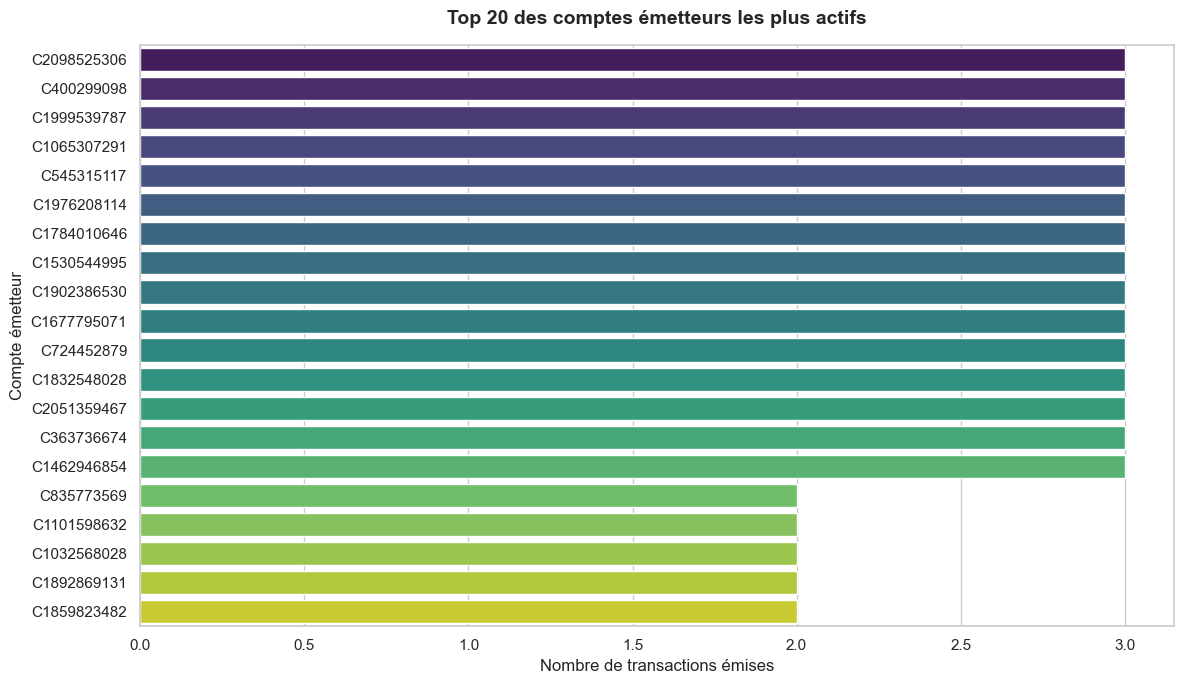

In [430]:
# Créer le graphique
fig, ax = plt.subplots(
    figsize=(12, 7)
)

sns.barplot(
    data=top_origin_accounts,
    y="Compte",
    x="Transactions émises",
    hue="Compte",
    palette="viridis",
    legend=False,
    ax=ax,
)

# Configurer le graphique
ax.set_title(
    "Top 20 des comptes émetteurs les plus actifs",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel("Nombre de transactions émises")
ax.set_ylabel("Compte émetteur")

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "23_top_origin_accounts.png"
)

plt.show()

In [431]:
# Compter les transactions reçues
destination_activity = (
    df["nameDest"]
    .value_counts()
    .rename("Transactions reçues")
)

# Afficher les statistiques
destination_activity_summary = (
    destination_activity
    .describe(
        percentiles=[
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
        ]
    )
    .to_frame()
)

display(destination_activity_summary)

,Transactions reçues
count,"2,722,362.00"
mean,2.34
std,4.55
min,1.00
50%,1.00
75%,1.00
90%,5.00
95%,10.00
99%,25.00
max,113.00


In [432]:
# Sélectionner les principaux destinataires
top_destination_accounts = (
    destination_activity
    .head(20)
    .reset_index()
)

# Renommer les colonnes
top_destination_accounts.columns = [
    "Compte",
    "Transactions reçues",
]

# Afficher le tableau
display(top_destination_accounts)

,Compte,Transactions reçues
0,C1286084959,113
1,C985934102,109
2,C665576141,105
3,C2083562754,102
4,C248609774,101
5,C1590550415,101
6,C451111351,99
7,C1789550256,99
8,C1360767589,98
9,C1023714065,97


Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\24_top_destination_accounts.png


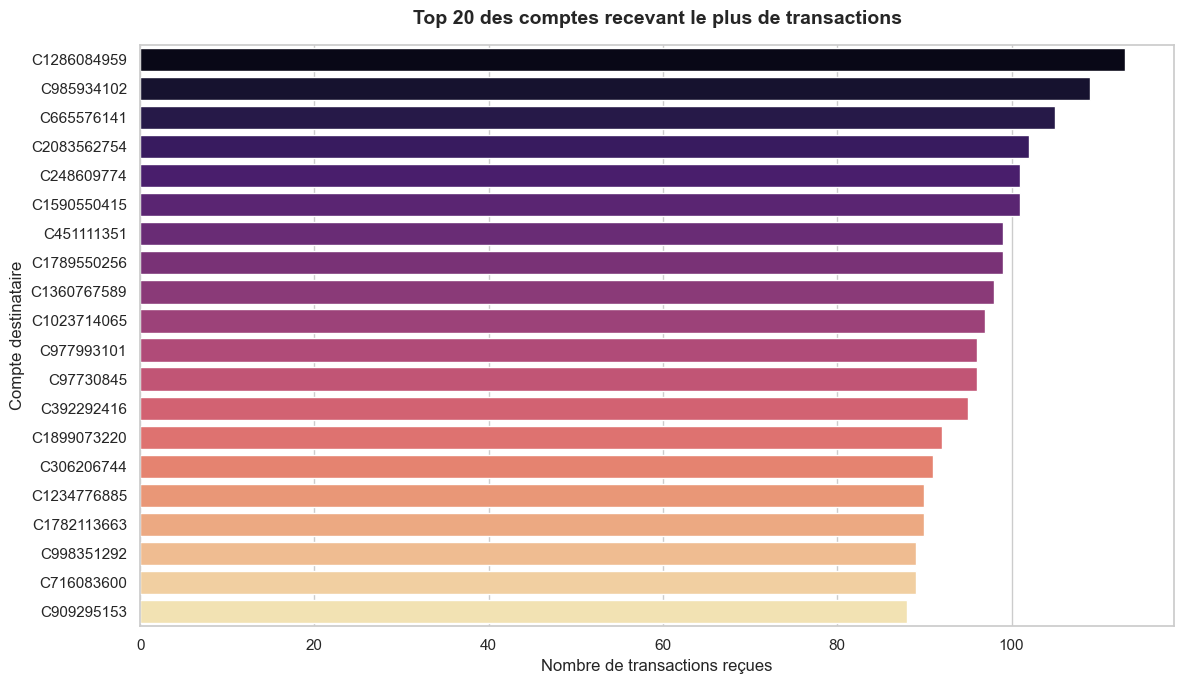

In [433]:
# Créer le graphique
fig, ax = plt.subplots(
    figsize=(12, 7)
)

sns.barplot(
    data=top_destination_accounts,
    y="Compte",
    x="Transactions reçues",
    hue="Compte",
    palette="magma",
    legend=False,
    ax=ax,
)

# Configurer le graphique
ax.set_title(
    "Top 20 des comptes recevant le plus de transactions",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel("Nombre de transactions reçues")
ax.set_ylabel("Compte destinataire")

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "24_top_destination_accounts.png"
)

plt.show()

Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\25_origin_activity_distribution.png


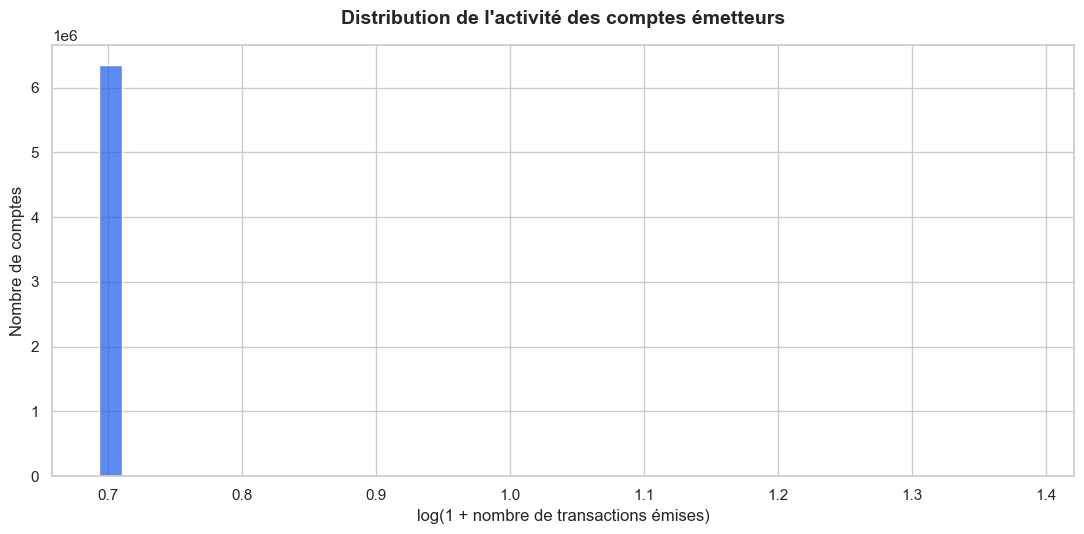

In [434]:
# Préparer les données
origin_activity_plot = (
    origin_activity
    .reset_index(drop=True)
)

# Créer le graphique
fig, ax = plt.subplots(
    figsize=(11, 5.5)
)

sns.histplot(
    np.log1p(origin_activity_plot),
    bins=40,
    color=COLORS["primary"],
    ax=ax,
)

# Configurer le graphique
ax.set_title(
    "Distribution de l'activité des comptes émetteurs",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel(
    "log(1 + nombre de transactions émises)"
)

ax.set_ylabel(
    "Nombre de comptes"
)

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "25_origin_activity_distribution.png"
)

plt.show()

Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\26_destination_activity_distribution.png


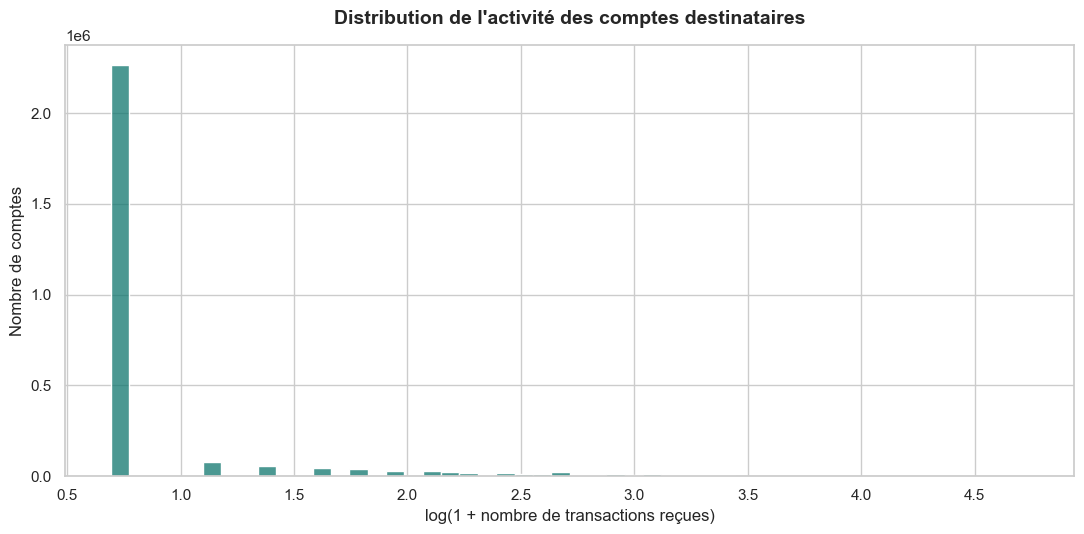

In [435]:
# Préparer les données
destination_activity_plot = (
    destination_activity
    .reset_index(drop=True)
)

# Créer le graphique
fig, ax = plt.subplots(
    figsize=(11, 5.5)
)

sns.histplot(
    np.log1p(destination_activity_plot),
    bins=50,
    color=COLORS["secondary"],
    ax=ax,
)

# Configurer le graphique
ax.set_title(
    "Distribution de l'activité des comptes destinataires",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel(
    "log(1 + nombre de transactions reçues)"
)

ax.set_ylabel(
    "Nombre de comptes"
)

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "26_destination_activity_distribution.png"
)

plt.show()

In [436]:
# Calculer le volume envoyé
origin_volume = (
    df.groupby(
        "nameOrig",
        observed=True,
    )["amount"]
    .agg(
        Transactions="count",
        Volume_total="sum",
        Montant_moyen="mean",
        Montant_médian="median",
        Montant_maximum="max",
    )
)

# Identifier les plus gros volumes
top_origin_volume = (
    origin_volume
    .nlargest(
        20,
        "Volume_total",
    )
    .reset_index()
)

# Afficher le tableau
display(top_origin_volume)

,nameOrig,Transactions,Volume_total,Montant_moyen,Montant_médian,Montant_maximum
0,C1715283297,1,"92,445,516.64","92,445,516.64","92,445,516.64","92,445,516.64"
1,C2127282686,1,"73,823,490.36","73,823,490.36","73,823,490.36","73,823,490.36"
2,C2044643633,1,"71,172,480.42","71,172,480.42","71,172,480.42","71,172,480.42"
3,C1425667947,1,"69,886,731.30","69,886,731.30","69,886,731.30","69,886,731.30"
4,C1584456031,1,"69,337,316.27","69,337,316.27","69,337,316.27","69,337,316.27"
5,C811810230,1,"67,500,761.29","67,500,761.29","67,500,761.29","67,500,761.29"
6,C420748282,1,"66,761,272.21","66,761,272.21","66,761,272.21","66,761,272.21"
7,C1139847449,1,"64,234,448.19","64,234,448.19","64,234,448.19","64,234,448.19"
8,C300140823,1,"63,847,992.58","63,847,992.58","63,847,992.58","63,847,992.58"
9,C372535854,1,"63,294,839.63","63,294,839.63","63,294,839.63","63,294,839.63"


In [437]:
# Calculer le volume reçu
destination_volume = (
    df.groupby(
        "nameDest",
        observed=True,
    )["amount"]
    .agg(
        Transactions="count",
        Volume_total="sum",
        Montant_moyen="mean",
        Montant_médian="median",
        Montant_maximum="max",
    )
)

# Identifier les plus gros volumes
top_destination_volume = (
    destination_volume
    .nlargest(
        20,
        "Volume_total",
    )
    .reset_index()
)

# Afficher le tableau
display(top_destination_volume)

,nameDest,Transactions,Volume_total,Montant_moyen,Montant_médian,Montant_maximum
0,C439737079,18,"357,440,831.44","19,857,823.97","1,980,334.86","92,445,516.64"
1,C707403537,17,"299,374,418.42","17,610,259.91","16,334,860.62","52,042,803.47"
2,C167875008,28,"274,736,432.80","9,812,015.46","204,837.17","69,886,731.30"
3,C20253152,20,"270,116,188.69","13,505,809.43","502,222.86","54,561,579.68"
4,C172409641,57,"255,310,174.25","4,479,125.86","311,529.39","60,154,456.05"
5,C268913927,35,"253,484,588.10","7,242,416.80","227,707.81","53,920,358.88"
6,C936857833,46,"227,780,012.02","4,951,739.39","342,671.82","51,391,814.47"
7,C65111466,22,"227,443,845.85","10,338,356.63","376,526.20","64,234,448.19"
8,C744189981,26,"225,173,861.73","8,660,533.14","284,922.93","61,733,761.65"
9,C1406193485,46,"224,778,961.83","4,886,499.17","317,095.46","58,318,373.20"


In [438]:
# Sélectionner les fraudes
fraud_data = df.loc[
    df["isFraud"] == 1,
    [
        "nameOrig",
        "nameDest",
        "amount",
        "type",
        "step",
    ],
].copy()

# Afficher la taille
print(
    f"Transactions frauduleuses : "
    f"{len(fraud_data):,}"
)

print(
    f"Émetteurs frauduleux uniques : "
    f"{fraud_data['nameOrig'].nunique():,}"
)

print(
    f"Destinataires frauduleux uniques : "
    f"{fraud_data['nameDest'].nunique():,}"
)

Transactions frauduleuses : 8,213
Émetteurs frauduleux uniques : 8,213
Destinataires frauduleux uniques : 8,169


In [439]:
# Compter les fraudes par émetteur
fraud_origin_counts = (
    fraud_data["nameOrig"]
    .value_counts()
    .rename("Fraudes émises")
)

# Afficher les statistiques
display(
    fraud_origin_counts
    .describe()
    .to_frame()
)

# Afficher les principaux comptes
display(
    fraud_origin_counts
    .head(20)
    .to_frame()
)

,Fraudes émises
count,"8,213.00"
mean,1.00
std,0.00
min,1.00
25%,1.00
50%,1.00
75%,1.00
max,1.00


,Fraudes émises
nameOrig,
C1305486145,1
C840083671,1
C1420196421,1
C2101527076,1
C137533655,1
C1118430673,1
C749981943,1
C1334405552,1
C467632528,1


In [440]:
# Compter les fraudes reçues
fraud_destination_counts = (
    fraud_data["nameDest"]
    .value_counts()
    .rename("Fraudes reçues")
)

# Afficher les statistiques
display(
    fraud_destination_counts
    .describe()
    .to_frame()
)

# Afficher les principales destinations
display(
    fraud_destination_counts
    .head(20)
    .to_frame()
)

,Fraudes reçues
count,"8,169.00"
mean,1.01
std,0.07
min,1.00
25%,1.00
50%,1.00
75%,1.00
max,2.00


,Fraudes reçues
nameDest,
C410033330,2
C803116137,2
C904300960,2
C1013511446,2
C2020337583,2
C200064275,2
C185805228,2
C52390890,2
C935310781,2


In [441]:
# Compter les émetteurs récidivistes
repeated_fraud_origins = (
    fraud_origin_counts
    .loc[
        fraud_origin_counts > 1
    ]
)

# Compter les destinations récurrentes
repeated_fraud_destinations = (
    fraud_destination_counts
    .loc[
        fraud_destination_counts > 1
    ]
)

# Afficher les résultats
print(
    "Émetteurs impliqués dans plusieurs fraudes : "
    f"{len(repeated_fraud_origins):,}"
)

print(
    "Destinations recevant plusieurs fraudes : "
    f"{len(repeated_fraud_destinations):,}"
)

Émetteurs impliqués dans plusieurs fraudes : 0
Destinations recevant plusieurs fraudes : 44


In [442]:
# Identifier les destinations récurrentes
repeated_destination_ids = (
    repeated_fraud_destinations
    .index
)

# Identifier les transactions concernées
repeated_destination_mask = (
    fraud_data["nameDest"]
    .isin(repeated_destination_ids)
)

# Calculer le nombre de fraudes
frauds_to_repeated_destinations = int(
    repeated_destination_mask.sum()
)

# Calculer le pourcentage
frauds_to_repeated_destinations_rate = (
    100
    * frauds_to_repeated_destinations
    / len(fraud_data)
)

# Afficher les résultats
print(
    "Fraudes dirigées vers une destination "
    "frauduleuse récurrente : "
    f"{frauds_to_repeated_destinations:,}"
)

print(
    "Part correspondante : "
    f"{frauds_to_repeated_destinations_rate:.2f} %"
)

Fraudes dirigées vers une destination frauduleuse récurrente : 88
Part correspondante : 1.07 %


In [443]:
# Compter les couples frauduleux
fraud_pairs = (
    fraud_data
    .groupby(
        [
            "nameOrig",
            "nameDest",
        ],
        observed=True,
    )
    .size()
    .rename("Nombre de fraudes")
    .sort_values(
        ascending=False
    )
)

# Sélectionner les couples répétés
repeated_fraud_pairs = (
    fraud_pairs
    .loc[
        fraud_pairs > 1
    ]
)

# Afficher les résultats
print(
    "Couples source-destination frauduleux uniques : "
    f"{len(fraud_pairs):,}"
)

print(
    "Couples frauduleux répétés : "
    f"{len(repeated_fraud_pairs):,}"
)

display(
    repeated_fraud_pairs
    .head(20)
    .to_frame()
)

Couples source-destination frauduleux uniques : 8,213
Couples frauduleux répétés : 0


,,Nombre de fraudes
nameOrig,nameDest,


In [444]:
# Sélectionner les principaux destinataires
top_destination_ids = (
    destination_activity
    .head(100)
    .index
)

# Filtrer leurs transactions
top_destination_interactions = df.loc[
    df["nameDest"].isin(
        top_destination_ids
    ),
    [
        "nameOrig",
        "nameDest",
        "amount",
        "isFraud",
    ],
]

# Calculer leurs caractéristiques
top_destination_behavior = (
    top_destination_interactions
    .groupby(
        "nameDest",
        observed=True,
    )
    .agg(
        Transactions=("nameOrig", "size"),
        Émetteurs_uniques=("nameOrig", "nunique"),
        Volume_reçu=("amount", "sum"),
        Fraudes_reçues=("isFraud", "sum"),
    )
    .sort_values(
        "Transactions",
        ascending=False,
    )
)

# Afficher les résultats
display(
    top_destination_behavior
    .head(20)
)

,Transactions,Émetteurs_uniques,Volume_reçu,Fraudes_reçues
nameDest,,,,
C1286084959,113,113,"77,428,943.31",0
C985934102,109,109,"42,422,887.98",0
C665576141,105,105,"88,749,384.38",0
C2083562754,102,102,"53,073,938.76",0
C248609774,101,101,"40,680,160.99",0
C1590550415,101,101,"43,206,101.59",0
C451111351,99,99,"37,453,031.39",0
C1789550256,99,99,"177,885,264.60",0
C1360767589,98,98,"35,121,289.27",0


In [445]:
# Extraire le préfixe de l’émetteur
origin_prefix = (
    df["nameOrig"]
    .astype(str)
    .str[0]
)

# Extraire le préfixe du destinataire
destination_prefix = (
    df["nameDest"]
    .astype(str)
    .str[0]
)

# Créer le tableau
prefix_summary = pd.DataFrame(
    {
        "Origine": (
            origin_prefix
            .value_counts()
        ),
        "Destination": (
            destination_prefix
            .value_counts()
        ),
    }
).fillna(0)

# Afficher le tableau
display(prefix_summary)

,Origine,Destination
C,"6,362,620.00",4211125
M,0.00,2151495


In [446]:
# Extraire les préfixes frauduleux
fraud_destination_prefix = (
    fraud_data["nameDest"]
    .astype(str)
    .str[0]
    .value_counts()
    .rename("Fraudes")
)

# Afficher les résultats
display(
    fraud_destination_prefix
    .to_frame()
)

,Fraudes
nameDest,
C,8213


In [447]:
# Créer la synthèse
behavior_summary = pd.DataFrame(
    {
        "Indicateur": [
            "Comptes émetteurs uniques",
            "Comptes destinataires uniques",
            "Émetteurs frauduleux uniques",
            "Destinataires frauduleux uniques",
            "Émetteurs impliqués dans plusieurs fraudes",
            "Destinations recevant plusieurs fraudes",
            "Couples frauduleux répétés",
        ],
        "Valeur": [
            df["nameOrig"].nunique(),
            df["nameDest"].nunique(),
            fraud_data["nameOrig"].nunique(),
            fraud_data["nameDest"].nunique(),
            len(repeated_fraud_origins),
            len(repeated_fraud_destinations),
            len(repeated_fraud_pairs),
        ],
    }
)

# Afficher le tableau
display(behavior_summary)

,Indicateur,Valeur
0,Comptes émetteurs uniques,6353307
1,Comptes destinataires uniques,2722362
2,Émetteurs frauduleux uniques,8213
3,Destinataires frauduleux uniques,8169
4,Émetteurs impliqués dans plusieurs fraudes,0
5,Destinations recevant plusieurs fraudes,44
6,Couples frauduleux répétés,0


In [448]:
# Enregistrer les principaux comptes émetteurs
top_origin_accounts.to_csv(
    tables_dir / "top_origin_accounts.csv",
    index=False,
    encoding="utf-8-sig",
)

# Enregistrer les principaux destinataires
top_destination_accounts.to_csv(
    tables_dir / "top_destination_accounts.csv",
    index=False,
    encoding="utf-8-sig",
)

# Enregistrer les destinations frauduleuses
fraud_destination_counts.head(100).to_csv(
    tables_dir / "top_fraud_destinations.csv",
    encoding="utf-8-sig",
)

# Enregistrer la synthèse
behavior_summary.to_csv(
    tables_dir / "account_behavior_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

print(
    "Résultats comportementaux enregistrés."
)

Résultats comportementaux enregistrés.


## Conclusion de l'analyse comportementale des comptes

### Observation

La structure comportementale des comptes présente une forte asymétrie entre
les émetteurs et les destinataires.

Le dataset contient environ 6,35 millions de comptes émetteurs uniques pour
6,36 millions de transactions. Les comptes sources sont donc très peu
récurrents et les plus actifs n'émettent que trois transactions.

À l'inverse, les comptes destinataires présentent davantage de récurrence.
Certaines destinations reçoivent plus de 100 transactions et le 99e percentile
atteint 25 transactions reçues.

Concernant la fraude, les 8 213 transactions frauduleuses sont associées à
8 213 émetteurs différents.

Aucun émetteur n'est impliqué dans plusieurs fraudes.

Les 8 213 fraudes concernent également 8 169 destinations différentes.
Seulement 44 destinations reçoivent deux fraudes, ce qui représente 88
transactions frauduleuses, soit environ 1,07 % des fraudes.

Aucun couple source-destination frauduleux n'est répété.

### Interprétation métier

Contrairement à l'hypothèse d'un réseau constitué de fraudeurs fortement
récurrents, PaySim génère principalement des transactions frauduleuses
impliquant des comptes différents.

La récidive directe d'un même compte source ou d'un même couple
source-destination constitue donc un signal très limité dans ce dataset.

Les comptes destinataires présentent toutefois davantage de connectivité que
les émetteurs et constituent une source d'information relationnelle plus
importante.

L'analyse montre également qu'un compte très connecté n'est pas nécessairement
suspect. Les destinations les plus actives du dataset ne présentent pas
automatiquement davantage de fraude.

### Limite liée au dataset

Cette faible répétition des acteurs frauduleux constitue une caractéristique
importante de PaySim.

Elle limite l'analyse de réseaux de fraude récurrents et devra être explicitement
mentionnée lors de l'évaluation des modèles Graph Neural Networks.

La performance des modèles de graphe ne devra donc pas être justifiée
uniquement par leur capacité à détecter des communautés de fraudeurs.

### Impact sur le Feature Engineering

Les features comportementales les plus pertinentes seront principalement :

- nombre historique de transactions reçues ;
- nombre de sources uniques d'une destination ;
- volume historique reçu ;
- volume historique envoyé ;
- nombre de voisins uniques ;
- temps depuis la dernière interaction ;
- activité récente sur une fenêtre temporelle ;
- concentration des flux vers certaines destinations.

Les features reposant sur la récidive de l'émetteur seront étudiées mais leur
utilité pourrait être limitée par la structure du dataset.

### Impact sur les modèles Machine Learning

Les identifiants `nameOrig` et `nameDest` ne seront pas encodés directement
par One-Hot Encoding.

Ils présentent une cardinalité extrêmement élevée et beaucoup d'identifiants
apparaissent une seule fois.

Les modèles tabulaires utiliseront plutôt des statistiques historiques dérivées
de ces identifiants.

### Impact sur les Graph Neural Networks

Les comptes seront représentés comme des nœuds et les transactions comme des
arêtes orientées.

La tâche principale sera formulée comme une classification temporelle d'arêtes :

(source, destination, timestamp, attributs) → fraude / légitime

La forte proportion de comptes sources peu récurrents favorise l'utilisation
de modèles capables de généraliser à de nouveaux nœuds à partir de leurs
caractéristiques et de leur voisinage.

Les approches inductives et temporelles seront donc privilégiées.

### Décision retenue

- Utiliser les comptes comme nœuds du graphe.
- Utiliser les transactions comme arêtes orientées.
- Formuler la tâche comme une classification d'arêtes.
- Ne pas utiliser directement les identifiants dans les modèles tabulaires.
- Prioriser les informations de voisinage et les statistiques des destinations.
- Ne pas supposer l'existence de communautés frauduleuses fortement récurrentes.
- Mentionner explicitement cette limite de PaySim dans le mémoire.

# 8. Analyse des patterns suspects

## Question métier

Existe-t-il des combinaisons de comportements transactionnels particulièrement
associées à la fraude ?

Les analyses précédentes ont montré plusieurs signaux potentiels :

- les fraudes présentent généralement des montants plus élevés ;
- les types `TRANSFER` et `CASH_OUT` concentrent les fraudes ;
- de nombreuses fraudes correspondent au vidage complet du compte émetteur ;
- les soldes avant et après transaction présentent des comportements particuliers ;
- les destinations frauduleuses sont majoritairement peu récurrentes.

Cette section combine ces observations afin d'identifier des patterns plus
complexes.

L'objectif est de préparer les futures variables du Feature Engineering et de
déterminer quelles informations pourront être utilisées comme attributs des
arêtes et des nœuds du graphe.

Les analyses restent descriptives. Aucun pattern observé ne sera transformé
directement en règle déterministe de détection.

In [449]:
# Définir la tolérance
balance_tolerance = 0.01

# Calculer le seuil des montants élevés
high_amount_threshold = (
    df["amount"]
    .quantile(0.99)
)

# Identifier les types à risque
risky_type_mask = (
    df["type"]
    .isin(
        [
            "TRANSFER",
            "CASH_OUT",
        ]
    )
)

# Identifier les montants élevés
high_amount_mask = (
    df["amount"]
    >= high_amount_threshold
)

# Identifier les montants égaux au solde
amount_equals_balance_mask = (
    (df["oldbalanceOrg"] > 0)
    & pd.Series(
        np.isclose(
            df["amount"],
            df["oldbalanceOrg"],
            atol=balance_tolerance,
            rtol=0,
        ),
        index=df.index,
    )
)

# Identifier les comptes vidés
origin_emptied_mask = (
    (df["oldbalanceOrg"] > 0)
    & (df["newbalanceOrig"] == 0)
)

# Identifier les transferts complets
full_balance_transfer_mask = (
    amount_equals_balance_mask
    & origin_emptied_mask
)

# Identifier les soldes nuls
origin_zero_before_mask = (
    df["oldbalanceOrg"] == 0
)

origin_zero_after_mask = (
    df["newbalanceOrig"] == 0
)

destination_zero_before_mask = (
    df["oldbalanceDest"] == 0
)

destination_zero_after_mask = (
    df["newbalanceDest"] == 0
)

print(
    f"Seuil du 99e percentile : "
    f"{high_amount_threshold:,.2f}"
)

Seuil du 99e percentile : 1,615,979.47


In [450]:
# Calculer le taux global de fraude
overall_fraud_rate = (
    df["isFraud"].mean()
)

# Créer la fonction de synthèse
def summarize_pattern(
    pattern_name,
    mask,
):
    # Convertir le masque
    mask = pd.Series(
        mask,
        index=df.index,
    ).fillna(False)

    # Créer les classes
    fraud_mask = (
        df["isFraud"] == 1
    )

    legitimate_mask = (
        df["isFraud"] == 0
    )

    # Compter les transactions
    pattern_transactions = int(
        mask.sum()
    )

    pattern_frauds = int(
        (
            mask
            & fraud_mask
        ).sum()
    )

    pattern_legitimate = int(
        (
            mask
            & legitimate_mask
        ).sum()
    )

    # Calculer le taux de fraude
    if pattern_transactions > 0:
        pattern_fraud_rate = (
            pattern_frauds
            / pattern_transactions
        )
    else:
        pattern_fraud_rate = np.nan

    # Calculer la prévalence chez les fraudes
    fraud_prevalence = (
        100
        * pattern_frauds
        / fraud_mask.sum()
    )

    # Calculer la prévalence chez les légitimes
    legitimate_prevalence = (
        100
        * pattern_legitimate
        / legitimate_mask.sum()
    )

    # Calculer le lift
    if (
        pattern_fraud_rate > 0
        and overall_fraud_rate > 0
    ):
        risk_lift = (
            pattern_fraud_rate
            / overall_fraud_rate
        )
    else:
        risk_lift = 0

    # Retourner les résultats
    return {
        "Pattern": pattern_name,
        "Transactions": pattern_transactions,
        "Fraudes": pattern_frauds,
        "Taux de fraude (%)": (
            100 * pattern_fraud_rate
        ),
        "Prévalence fraude (%)": fraud_prevalence,
        "Prévalence légitime (%)": legitimate_prevalence,
        "Lift de risque": risk_lift,
    }

In [451]:
# Définir les patterns
pattern_results = [
    summarize_pattern(
        "Type à risque",
        risky_type_mask,
    ),
    summarize_pattern(
        "Montant élevé",
        high_amount_mask,
    ),
    summarize_pattern(
        "Montant = solde initial",
        amount_equals_balance_mask,
    ),
    summarize_pattern(
        "Compte émetteur vidé",
        origin_emptied_mask,
    ),
    summarize_pattern(
        "Transfert total du solde",
        full_balance_transfer_mask,
    ),
    summarize_pattern(
        "Solde origine nul avant",
        origin_zero_before_mask,
    ),
    summarize_pattern(
        "Solde origine nul après",
        origin_zero_after_mask,
    ),
    summarize_pattern(
        "Solde destination nul avant",
        destination_zero_before_mask,
    ),
    summarize_pattern(
        "Type à risque + transfert total",
        risky_type_mask
        & full_balance_transfer_mask,
    ),
    summarize_pattern(
        "Type à risque + montant élevé",
        risky_type_mask
        & high_amount_mask,
    ),
]

# Construire le tableau
pattern_summary = pd.DataFrame(
    pattern_results
)

# Trier par lift
pattern_summary = (
    pattern_summary
    .sort_values(
        "Lift de risque",
        ascending=False,
    )
    .reset_index(drop=True)
)

# Afficher le tableau
display(pattern_summary)

,Pattern,Transactions,Fraudes,Taux de fraude (%),Prévalence fraude (%),Prévalence légitime (%),Lift de risque
0,Type à risque + transfert total,8008,8008,100.00,97.50,0.00,774.70
1,Transfert total du solde,8008,8008,100.00,97.50,0.00,774.70
2,Montant = solde initial,8019,8018,99.99,97.63,0.00,774.60
3,Type à risque + montant élevé,63622,1969,3.09,23.97,0.97,23.98
4,Montant élevé,63627,1969,3.09,23.97,0.97,23.97
5,Compte émetteur vidé,1520581,8012,0.53,97.55,23.80,4.08
6,Type à risque,2770409,8213,0.30,100.00,43.47,2.30
7,Solde origine nul après,3609566,8053,0.22,98.05,56.68,1.73
8,Solde destination nul avant,2704388,5351,0.20,65.15,42.48,1.53
9,Solde origine nul avant,2102449,41,0.00,0.50,33.09,0.02


Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\27_suspicious_pattern_risk_lift.png


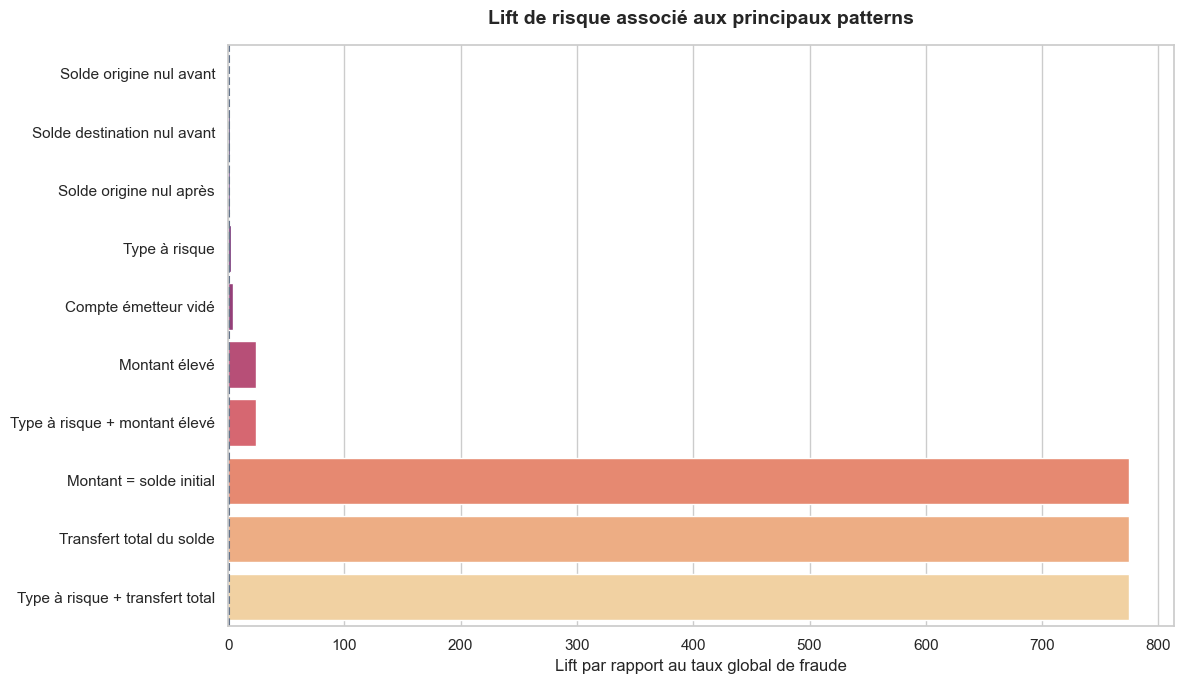

In [452]:
# Préparer les données
pattern_plot = (
    pattern_summary
    .sort_values(
        "Lift de risque",
        ascending=True,
    )
)

# Créer le graphique
fig, ax = plt.subplots(
    figsize=(12, 7)
)

sns.barplot(
    data=pattern_plot,
    y="Pattern",
    x="Lift de risque",
    hue="Pattern",
    palette="magma",
    legend=False,
    ax=ax,
)

# Ajouter la référence
ax.axvline(
    1,
    color=COLORS["neutral"],
    linestyle="--",
    linewidth=1.5,
    label="Risque moyen",
)

# Configurer le graphique
ax.set_title(
    "Lift de risque associé aux principaux patterns",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel(
    "Lift par rapport au taux global de fraude"
)

ax.set_ylabel("")

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "27_suspicious_pattern_risk_lift.png"
)

plt.show()

In [453]:
# Créer les données de combinaison
combination_data = pd.DataFrame(
    {
        "isFraud": (
            df["isFraud"]
            .astype("int8")
        ),
        "Type à risque": (
            risky_type_mask
        ),
        "Montant élevé": (
            high_amount_mask
        ),
        "Transfert total": (
            full_balance_transfer_mask
        ),
    }
)

# Agréger les combinaisons
combination_summary = (
    combination_data
    .groupby(
        [
            "Type à risque",
            "Montant élevé",
            "Transfert total",
        ],
        observed=True,
    )
    .agg(
        Transactions=("isFraud", "size"),
        Fraudes=("isFraud", "sum"),
    )
    .reset_index()
)

# Calculer le taux de fraude
combination_summary[
    "Taux de fraude (%)"
] = (
    100
    * combination_summary["Fraudes"]
    / combination_summary["Transactions"]
)

# Trier les combinaisons
combination_summary = (
    combination_summary
    .sort_values(
        "Taux de fraude (%)",
        ascending=False,
    )
)

# Afficher le tableau
display(combination_summary)

,Type à risque,Montant élevé,Transfert total,Transactions,Fraudes,Taux de fraude (%)
5,True,True,True,1814,1814,100.00
3,True,False,True,6194,6194,100.00
4,True,True,False,61808,155,0.25
2,True,False,False,2700593,50,0.00
1,False,True,False,5,0,0.00
0,False,False,False,3592206,0,0.00


In [454]:
# Définir le volume minimum
minimum_pattern_volume = 100

# Filtrer les combinaisons
reliable_combinations = (
    combination_summary
    .loc[
        combination_summary[
            "Transactions"
        ] >= minimum_pattern_volume
    ]
    .copy()
)

# Afficher les résultats
display(
    reliable_combinations
)

,Type à risque,Montant élevé,Transfert total,Transactions,Fraudes,Taux de fraude (%)
5,True,True,True,1814,1814,100.00
3,True,False,True,6194,6194,100.00
4,True,True,False,61808,155,0.25
2,True,False,False,2700593,50,0.00
0,False,False,False,3592206,0,0.00


In [455]:
# Créer les indicateurs
zero_balance_data = pd.DataFrame(
    {
        "isFraud": df["isFraud"],
        "Origine avant = 0": (
            origin_zero_before_mask
        ),
        "Origine après = 0": (
            origin_zero_after_mask
        ),
        "Destination avant = 0": (
            destination_zero_before_mask
        ),
        "Destination après = 0": (
            destination_zero_after_mask
        ),
    }
)

# Agréger selon la classe
zero_balance_summary = (
    zero_balance_data
    .groupby("isFraud")
    .agg(
        {
            "Origine avant = 0": "mean",
            "Origine après = 0": "mean",
            "Destination avant = 0": "mean",
            "Destination après = 0": "mean",
        }
    )
    .mul(100)
    .reset_index()
)

# Renommer la classe
zero_balance_summary["Classe"] = (
    zero_balance_summary["isFraud"]
    .map(
        {
            0: "Légitime",
            1: "Fraude",
        }
    )
)

# Afficher le tableau
display(zero_balance_summary)

,isFraud,Origine avant = 0,Origine après = 0,Destination avant = 0,Destination après = 0,Classe
0,0,33.09,56.68,42.48,38.33,Légitime
1,1,0.50,98.05,65.15,49.81,Fraude


Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\28_zero_balance_patterns.png


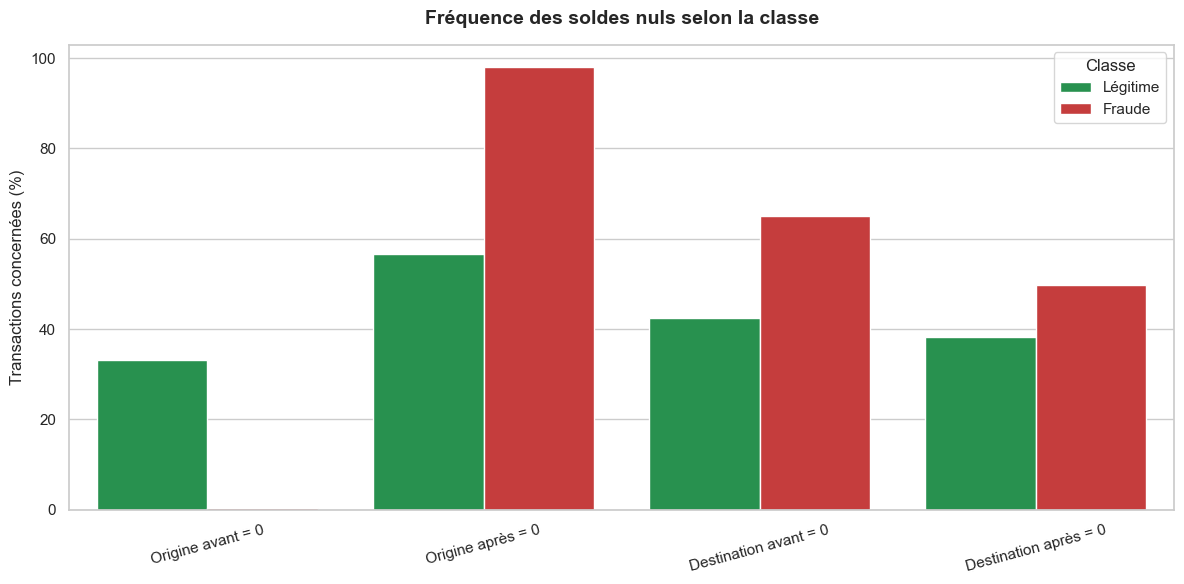

In [456]:
# Préparer les données
zero_balance_plot = (
    zero_balance_summary
    .drop(
        columns="isFraud"
    )
    .melt(
        id_vars="Classe",
        var_name="Pattern",
        value_name="Pourcentage",
    )
)

# Créer le graphique
fig, ax = plt.subplots(
    figsize=(12, 6)
)

sns.barplot(
    data=zero_balance_plot,
    x="Pattern",
    y="Pourcentage",
    hue="Classe",
    palette=class_palette,
    ax=ax,
)

# Configurer le graphique
ax.set_title(
    "Fréquence des soldes nuls selon la classe",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel("")
ax.set_ylabel(
    "Transactions concernées (%)"
)

ax.tick_params(
    axis="x",
    rotation=15,
)

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "28_zero_balance_patterns.png"
)

plt.show()

In [457]:
# Sélectionner les colonnes nécessaires
balance_columns = [
    "type",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "isFraud",
]

# Sélectionner les fraudes à risque
fraud_balance_sample = df.loc[
    (
        (df["isFraud"] == 1)
        & risky_type_mask
    ),
    balance_columns,
].copy()

# Sélectionner les légitimes à risque
legitimate_balance_data = df.loc[
    (
        (df["isFraud"] == 0)
        & risky_type_mask
    ),
    balance_columns,
]

# Échantillonner les légitimes
legitimate_balance_sample = (
    legitimate_balance_data
    .sample(
        n=min(
            100_000,
            len(legitimate_balance_data),
        ),
        random_state=RANDOM_STATE,
    )
    .copy()
)

# Combiner les classes
balance_consistency_sample = pd.concat(
    [
        legitimate_balance_sample,
        fraud_balance_sample,
    ],
    ignore_index=True,
)

# Créer les labels
balance_consistency_sample["Classe"] = (
    balance_consistency_sample["isFraud"]
    .map(
        {
            0: "Légitime",
            1: "Fraude",
        }
    )
)

print(
    f"Taille de l'échantillon : "
    f"{len(balance_consistency_sample):,}"
)

Taille de l'échantillon : 108,213


In [458]:
# Calculer le solde théorique de l’émetteur
balance_consistency_sample[
    "Expected_origin_balance"
] = (
    balance_consistency_sample[
        "oldbalanceOrg"
    ]
    - balance_consistency_sample[
        "amount"
    ]
)

# Calculer l’écart origine
balance_consistency_sample[
    "Origin_balance_residual"
] = (
    balance_consistency_sample[
        "newbalanceOrig"
    ]
    - balance_consistency_sample[
        "Expected_origin_balance"
    ]
).abs()

# Calculer le solde théorique du destinataire
balance_consistency_sample[
    "Expected_destination_balance"
] = (
    balance_consistency_sample[
        "oldbalanceDest"
    ]
    + balance_consistency_sample[
        "amount"
    ]
)

# Calculer l’écart destination
balance_consistency_sample[
    "Destination_balance_residual"
] = (
    balance_consistency_sample[
        "newbalanceDest"
    ]
    - balance_consistency_sample[
        "Expected_destination_balance"
    ]
).abs()

In [459]:
# Calculer les statistiques
balance_residual_summary = (
    balance_consistency_sample
    .groupby("Classe")
    .agg(
        Origine_médiane=(
            "Origin_balance_residual",
            "median",
        ),
        Origine_P95=(
            "Origin_balance_residual",
            lambda values: values.quantile(0.95),
        ),
        Destination_médiane=(
            "Destination_balance_residual",
            "median",
        ),
        Destination_P95=(
            "Destination_balance_residual",
            lambda values: values.quantile(0.95),
        ),
    )
    .reset_index()
)

# Afficher le tableau
display(
    balance_residual_summary
)

,Classe,Origine_médiane,Origine_P95,Destination_médiane,Destination_P95
0,Fraude,0.00,0.00,"9,511.69","4,585,021.28"
1,Légitime,"143,968.85","902,665.73",0.00,"179,086.51"


In [460]:
# Identifier les écarts faibles
balance_consistency_sample[
    "Origin_consistent"
] = (
    balance_consistency_sample[
        "Origin_balance_residual"
    ]
    <= balance_tolerance
)

balance_consistency_sample[
    "Destination_consistent"
] = (
    balance_consistency_sample[
        "Destination_balance_residual"
    ]
    <= balance_tolerance
)

# Calculer les proportions
balance_consistency_summary = (
    balance_consistency_sample
    .groupby("Classe")
    .agg(
        Cohérence_origine=(
            "Origin_consistent",
            "mean",
        ),
        Cohérence_destination=(
            "Destination_consistent",
            "mean",
        ),
    )
    .mul(100)
    .reset_index()
)

# Afficher le tableau
display(
    balance_consistency_summary
)

,Classe,Cohérence_origine,Cohérence_destination
0,Fraude,99.45,43.50
1,Légitime,9.71,77.38


In [461]:
# Identifier les écarts faibles
balance_consistency_sample[
    "Origin_consistent"
] = (
    balance_consistency_sample[
        "Origin_balance_residual"
    ]
    <= balance_tolerance
)

balance_consistency_sample[
    "Destination_consistent"
] = (
    balance_consistency_sample[
        "Destination_balance_residual"
    ]
    <= balance_tolerance
)

# Calculer les proportions
balance_consistency_summary = (
    balance_consistency_sample
    .groupby("Classe")
    .agg(
        Cohérence_origine=(
            "Origin_consistent",
            "mean",
        ),
        Cohérence_destination=(
            "Destination_consistent",
            "mean",
        ),
    )
    .mul(100)
    .reset_index()
)

# Afficher le tableau
display(
    balance_consistency_summary
)

,Classe,Cohérence_origine,Cohérence_destination
0,Fraude,99.45,43.50
1,Légitime,9.71,77.38


Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\29_balance_residuals_by_class.png


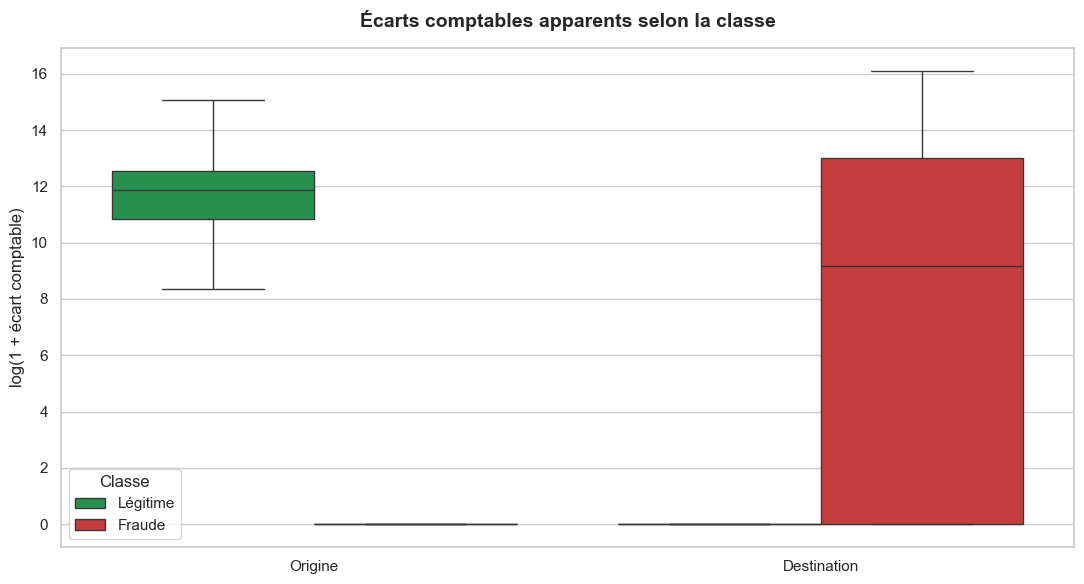

In [462]:
# Préparer les données
residual_plot = (
    balance_consistency_sample[
        [
            "Classe",
            "Origin_balance_residual",
            "Destination_balance_residual",
        ]
    ]
    .copy()
)

# Transformer les écarts
residual_plot[
    "Origine"
] = np.log1p(
    residual_plot[
        "Origin_balance_residual"
    ]
)

residual_plot[
    "Destination"
] = np.log1p(
    residual_plot[
        "Destination_balance_residual"
    ]
)

# Restructurer les données
residual_plot = (
    residual_plot[
        [
            "Classe",
            "Origine",
            "Destination",
        ]
    ]
    .melt(
        id_vars="Classe",
        var_name="Compte",
        value_name="log_residual",
    )
)

# Créer le graphique
fig, ax = plt.subplots(
    figsize=(11, 6)
)

sns.boxplot(
    data=residual_plot,
    x="Compte",
    y="log_residual",
    hue="Classe",
    palette=class_palette,
    showfliers=False,
    ax=ax,
)

# Configurer le graphique
ax.set_title(
    "Écarts comptables apparents selon la classe",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel("")
ax.set_ylabel(
    "log(1 + écart comptable)"
)

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "29_balance_residuals_by_class.png"
)

plt.show()

In [463]:
# Calculer le maximum frauduleux
observed_fraud_cap = (
    df.loc[
        df["isFraud"] == 1,
        "amount",
    ]
    .max()
)

# Créer une zone proche du plafond
near_cap_threshold = (
    observed_fraud_cap
    * 0.99
)

# Identifier les transactions au plafond
exact_cap_mask = np.isclose(
    df["amount"],
    observed_fraud_cap,
    atol=balance_tolerance,
    rtol=0,
)

# Identifier les transactions proches du plafond
near_cap_mask = (
    df["amount"]
    >= near_cap_threshold
)

# Afficher les valeurs
print(
    f"Maximum frauduleux observé : "
    f"{observed_fraud_cap:,.2f}"
)

print(
    f"Seuil proche du plafond : "
    f"{near_cap_threshold:,.2f}"
)

Maximum frauduleux observé : 10,000,000.00
Seuil proche du plafond : 9,900,000.00


In [464]:
# Résumer les patterns du plafond
cap_summary = pd.DataFrame(
    [
        summarize_pattern(
            "Montant exactement au plafond observé",
            exact_cap_mask,
        ),
        summarize_pattern(
            "Montant dans les 1 % du plafond",
            near_cap_mask,
        ),
    ]
)

# Afficher le tableau
display(cap_summary)

,Pattern,Transactions,Fraudes,Taux de fraude (%),Prévalence fraude (%),Prévalence légitime (%),Lift de risque
0,Montant exactement au plafond observé,3207,287,8.95,3.49,0.05,69.33
1,Montant dans les 1 % du plafond,5707,293,5.13,3.57,0.09,39.77


In [465]:
# Recalculer l’activité si nécessaire
if "origin_activity" not in globals():
    origin_activity = (
        df["nameOrig"]
        .value_counts()
    )

if "destination_activity" not in globals():
    destination_activity = (
        df["nameDest"]
        .value_counts()
    )

# Sélectionner les fraudes
fraud_edge_sample = df.loc[
    df["isFraud"] == 1,
    [
        "nameOrig",
        "nameDest",
        "isFraud",
    ],
].copy()

# Échantillonner les transactions légitimes
legitimate_edge_sample = (
    df.loc[
        df["isFraud"] == 0,
        [
            "nameOrig",
            "nameDest",
            "isFraud",
        ],
    ]
    .sample(
        n=100_000,
        random_state=RANDOM_STATE,
    )
    .copy()
)

# Combiner les données
edge_context_sample = pd.concat(
    [
        legitimate_edge_sample,
        fraud_edge_sample,
    ],
    ignore_index=True,
)

# Ajouter le degré sortant
edge_context_sample[
    "Origin_out_degree"
] = (
    edge_context_sample[
        "nameOrig"
    ]
    .map(origin_activity)
)

# Ajouter le degré entrant
edge_context_sample[
    "Destination_in_degree"
] = (
    edge_context_sample[
        "nameDest"
    ]
    .map(destination_activity)
)

# Ajouter la classe
edge_context_sample["Classe"] = (
    edge_context_sample["isFraud"]
    .map(
        {
            0: "Légitime",
            1: "Fraude",
        }
    )
)

In [466]:
# Comparer les degrés
edge_context_summary = (
    edge_context_sample
    .groupby("Classe")
    .agg(
        Degré_sortant_médian=(
            "Origin_out_degree",
            "median",
        ),
        Degré_sortant_P95=(
            "Origin_out_degree",
            lambda values: values.quantile(0.95),
        ),
        Degré_entrant_médian=(
            "Destination_in_degree",
            "median",
        ),
        Degré_entrant_P95=(
            "Destination_in_degree",
            lambda values: values.quantile(0.95),
        ),
        Degré_entrant_max=(
            "Destination_in_degree",
            "max",
        ),
    )
    .reset_index()
)

# Afficher le tableau
display(
    edge_context_summary
)

,Classe,Degré_sortant_médian,Degré_sortant_P95,Degré_entrant_médian,Degré_entrant_P95,Degré_entrant_max
0,Fraude,1.00,1.00,4.00,28.00,89
1,Légitime,1.00,1.00,7.00,37.00,113


Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\30_destination_degree_by_class.png


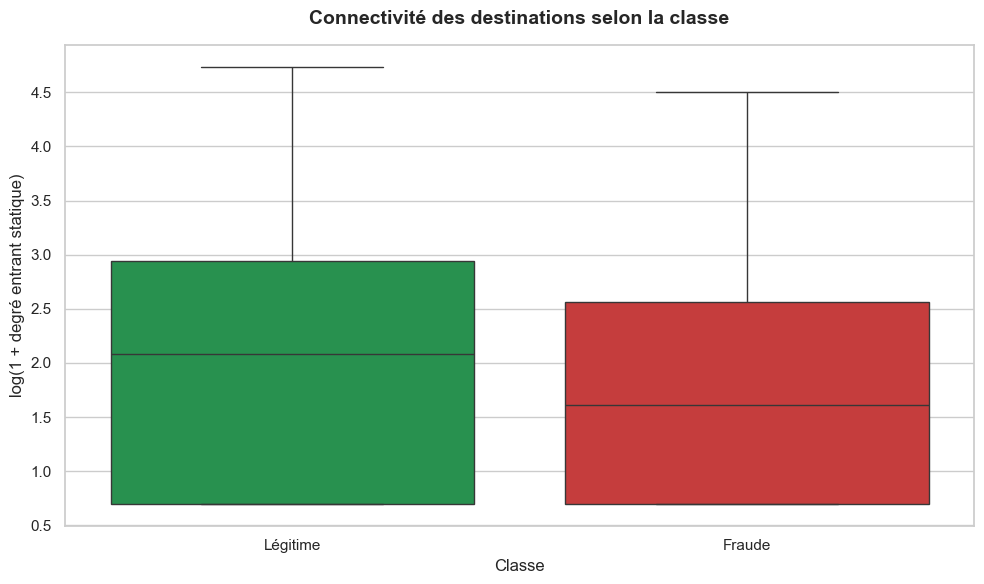

In [467]:
# Créer la transformation
edge_context_sample[
    "log_destination_degree"
] = np.log1p(
    edge_context_sample[
        "Destination_in_degree"
    ]
)

# Créer le graphique
fig, ax = plt.subplots(
    figsize=(10, 6)
)

sns.boxplot(
    data=edge_context_sample,
    x="Classe",
    y="log_destination_degree",
    order=[
        "Légitime",
        "Fraude",
    ],
    hue="Classe",
    palette=class_palette,
    legend=False,
    showfliers=False,
    ax=ax,
)

# Configurer le graphique
ax.set_title(
    "Connectivité des destinations selon la classe",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel("Classe")

ax.set_ylabel(
    "log(1 + degré entrant statique)"
)

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "30_destination_degree_by_class.png"
)

plt.show()

In [468]:
# Enregistrer les patterns
pattern_summary.to_csv(
    tables_dir
    / "suspicious_pattern_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

# Enregistrer les combinaisons
combination_summary.to_csv(
    tables_dir
    / "suspicious_pattern_combinations.csv",
    index=False,
    encoding="utf-8-sig",
)

# Enregistrer les soldes nuls
zero_balance_summary.to_csv(
    tables_dir
    / "zero_balance_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

# Enregistrer les écarts
balance_residual_summary.to_csv(
    tables_dir
    / "balance_residual_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

# Enregistrer le contexte relationnel
edge_context_summary.to_csv(
    tables_dir
    / "edge_context_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

print(
    "Résultats de la section 8 enregistrés."
)

Résultats de la section 8 enregistrés.


## Conclusion de l'analyse des patterns suspects

### Observation

L'analyse combinée des caractéristiques transactionnelles met en évidence
plusieurs patterns fortement associés à la fraude.

Le signal le plus important est le transfert de la totalité du solde du compte
émetteur.

Parmi les 8 008 transactions correspondant à un transfert total du solde,
les 8 008 sont frauduleuses. Ce comportement concerne environ 97,5 % de
l'ensemble des fraudes.

De même, 8 018 des 8 019 transactions dont le montant est égal au solde
initial sont frauduleuses.

Les montants élevés présentent également un risque accru, mais ils sont
nettement moins discriminants que le comportement de vidage complet du compte.

### Interprétation métier

Le scénario de fraude dominant dans PaySim correspond à un compte disposant
de fonds dont la quasi-totalité du solde est transférée au cours d'une seule
transaction.

Le solde final de l'émetteur devient ainsi très fréquemment nul.

Ce comportement constitue un signal extrêmement fort dans le dataset, mais
son niveau de discrimination suggère également qu'il peut provenir directement
du mécanisme utilisé par PaySim pour générer les transactions frauduleuses.

### Analyse des soldes

Environ 98,05 % des fraudes présentent un solde final de l'émetteur égal à
zéro, contre 56,68 % des transactions légitimes.

À l'inverse, seulement 0,50 % des fraudes commencent avec un solde émetteur
nul, contre environ 33,09 % des transactions légitimes.

La cohérence comptable apparente du compte émetteur est également très
différente selon la classe.

En utilisant la relation simplifiée :

`oldbalanceOrg - amount ≈ newbalanceOrig`

environ 99,45 % des transactions frauduleuses sont cohérentes, contre seulement
9,71 % des transactions légitimes étudiées.

Ce résultat contre-intuitif constitue probablement une caractéristique du
simulateur et devra être interprété avec prudence.

### Analyse des montants extrêmes

Le maximum frauduleux observé est de 10 millions.

Les transactions exactement égales à cette valeur présentent un taux de fraude
d'environ 8,95 %, soit un risque très supérieur à la moyenne.

Cependant, ce pattern ne concerne qu'une faible proportion des fraudes et ne
sera pas utilisé comme règle ou feature directement dérivée de la cible.

### Analyse relationnelle

Les comptes destinataires impliqués dans les fraudes ne présentent pas une
connectivité particulièrement élevée.

Le degré entrant médian est de 4 pour les transactions frauduleuses, contre 7
pour les transactions légitimes de l'échantillon.

Le Graph Learning ne devra donc pas reposer uniquement sur la détection de
hubs ou de comptes fortement connectés.

Son intérêt résidera davantage dans la combinaison entre :

- la structure locale du réseau ;
- les attributs des transactions ;
- l'historique des comptes ;
- l'ordre temporel des interactions.

### Limite liée au dataset

La quasi-séparation entre fraude et non-fraude produite par certains patterns,
notamment le transfert total du solde, représente un risque de surévaluation
des performances des modèles.

Un modèle peut obtenir d'excellentes performances en apprenant principalement
les règles utilisées par le simulateur pour générer les fraudes.

Cette limite devra être explicitement discutée dans le mémoire.

### Impact sur le Feature Engineering

Les principales variables candidates sont :

- `log_amount` ;
- `amount_to_oldbalance_ratio` ;
- `amount_equals_oldbalance` ;
- `origin_emptied` ;
- `full_balance_transfer` ;
- `origin_balance_residual` ;
- `destination_balance_residual` ;
- indicateurs de soldes nuls ;
- degré historique des comptes ;
- nombre historique de voisins ;
- volumes entrants et sortants récents.

Toutes les caractéristiques comportementales et relationnelles devront être
calculées uniquement à partir des événements passés.

### Impact sur les modèles Machine Learning

Les variables liées au solde de l'émetteur devraient être très fortement
prédictives.

Cependant, une étude d'ablation sera nécessaire afin de vérifier dans quelle
mesure les performances reposent sur les patterns spécifiques à PaySim.

Une comparaison pourra notamment être réalisée entre :

- un modèle utilisant toutes les features ;
- un modèle excluant les variables directement liées au vidage complet du
  compte.

### Impact sur les Graph Neural Networks

Les patterns transactionnels deviendront des attributs d'arêtes tandis que
les statistiques historiques des comptes deviendront des attributs de nœuds.

La tâche restera formulée comme une classification temporelle d'arêtes.

Les caractéristiques structurelles ne devront pas être calculées à partir du
graphe complet avant le split temporel afin d'éviter toute fuite d'information.

### Décision retenue

- Conserver les patterns de vidage comme candidats au Feature Engineering.
- Ne pas considérer ces patterns comme des règles universelles de fraude.
- Ne pas créer de feature utilisant le plafond frauduleux découvert à partir
  de la cible.
- Calculer les futures features relationnelles de manière chronologique.
- Prévoir une étude d'ablation sur les features fortement spécifiques à PaySim.
- Évaluer la capacité des modèles à apprendre au-delà des règles du simulateur.

# 9. Analyse des corrélations

## Question métier

Certaines variables numériques décrivent-elles des informations fortement
redondantes ou présentent-elles une relation particulière avec la fraude ?

Cette section étudie les corrélations entre :

- le montant de la transaction ;
- les soldes de l'émetteur ;
- les soldes du destinataire ;
- la dimension temporelle ;
- la variable cible `isFraud`.

Deux approches sont utilisées :

- la corrélation de Pearson pour mesurer les relations linéaires ;
- la corrélation de Spearman pour détecter les relations monotones.

La matrice de corrélation constitue uniquement un outil exploratoire.

Une corrélation faible avec `isFraud` ne signifie pas qu'une variable est
inutile. Une variable peut devenir fortement informative lorsqu'elle est
combinée à d'autres caractéristiques ou utilisée dans un modèle non linéaire.

In [469]:
# Définir les variables
correlation_variables = [
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "step",
    "isFraud",
]

# Vérifier les colonnes
missing_corr_columns = [
    variable
    for variable in correlation_variables
    if variable not in df.columns
]

# Vérifier le résultat
if missing_corr_columns:
    raise KeyError(
        f"Variables absentes : {missing_corr_columns}"
    )

print("Variables utilisées pour les corrélations :")

for variable in correlation_variables:
    print(f"- {variable}")

Variables utilisées pour les corrélations :
- amount
- oldbalanceOrg
- newbalanceOrig
- oldbalanceDest
- newbalanceDest
- step
- isFraud


In [470]:
# Calculer la matrice de Pearson
pearson_corr = (
    df[correlation_variables]
    .corr(
        method="pearson"
    )
)

# Afficher la matrice
display(
    pearson_corr.round(4)
)

,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,step,isFraud
amount,1.00,-0.00,-0.01,0.29,0.46,0.02,0.08
oldbalanceOrg,-0.00,1.00,1.00,0.07,0.04,-0.01,0.01
newbalanceOrig,-0.01,1.00,1.00,0.07,0.04,-0.01,-0.01
oldbalanceDest,0.29,0.07,0.07,1.00,0.98,0.03,-0.01
newbalanceDest,0.46,0.04,0.04,0.98,1.00,0.03,0.00
step,0.02,-0.01,-0.01,0.03,0.03,1.00,0.03
isFraud,0.08,0.01,-0.01,-0.01,0.00,0.03,1.00


Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\31_pearson_correlation_matrix.png


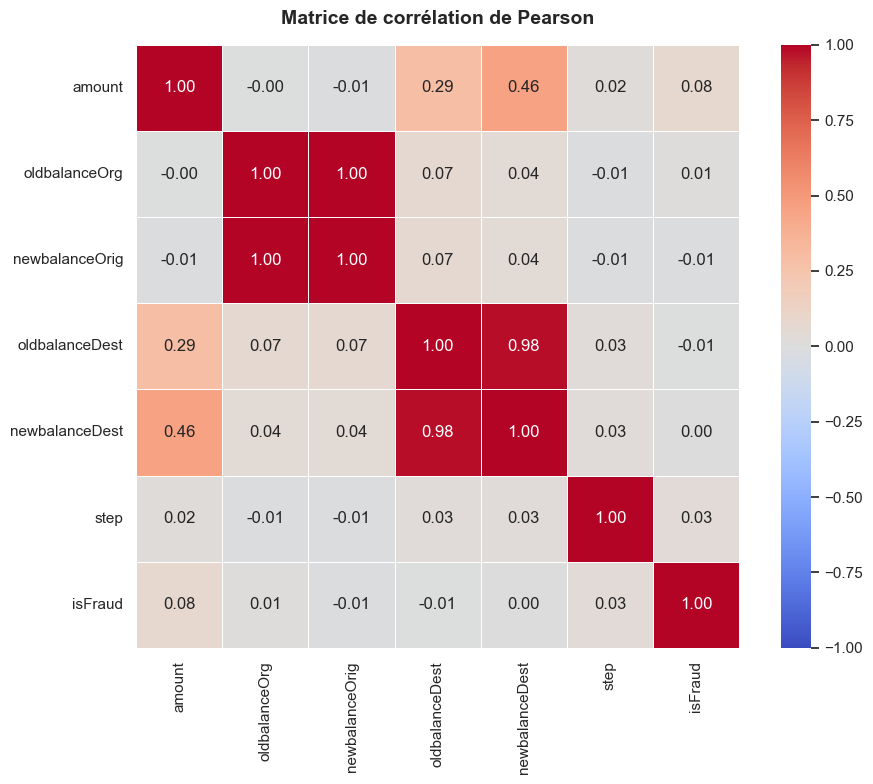

In [471]:
# Créer le graphique
fig, ax = plt.subplots(
    figsize=(10, 8)
)

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    ax=ax,
)

# Configurer le graphique
ax.set_title(
    "Matrice de corrélation de Pearson",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "31_pearson_correlation_matrix.png"
)

plt.show()

In [472]:
# Extraire les corrélations avec la cible
target_correlations = (
    pearson_corr["isFraud"]
    .drop("isFraud")
    .sort_values(
        key=lambda values: values.abs(),
        ascending=False,
    )
    .to_frame(
        "Corrélation avec isFraud"
    )
)

# Ajouter la valeur absolue
target_correlations[
    "Corrélation absolue"
] = (
    target_correlations[
        "Corrélation avec isFraud"
    ]
    .abs()
)

# Afficher le tableau
display(
    target_correlations.round(4)
)

,Corrélation avec isFraud,Corrélation absolue
amount,0.08,0.08
step,0.03,0.03
oldbalanceOrg,0.01,0.01
newbalanceOrig,-0.01,0.01
oldbalanceDest,-0.01,0.01
newbalanceDest,0.00,0.00


Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\32_target_correlations.png


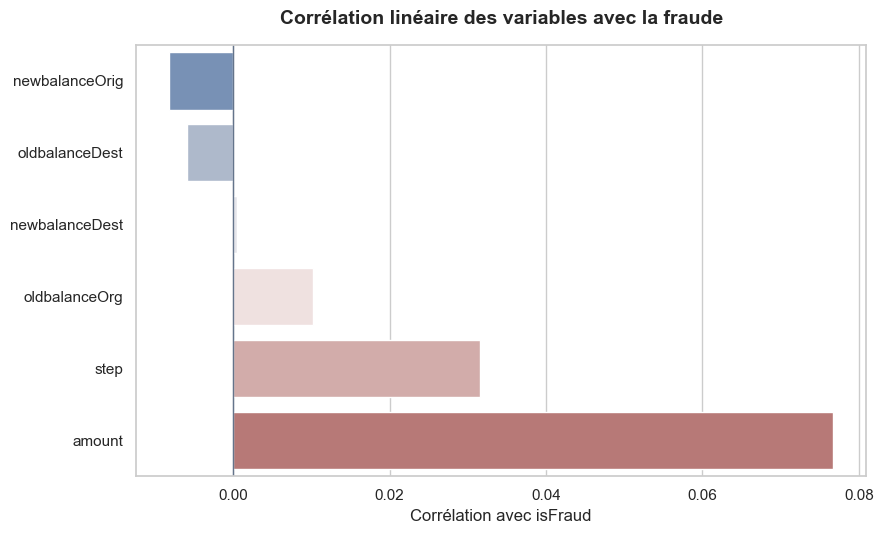

In [473]:
# Préparer les données
target_corr_plot = (
    target_correlations
    .reset_index()
    .rename(
        columns={
            "index": "Variable"
        }
    )
    .sort_values(
        "Corrélation avec isFraud"
    )
)

# Créer le graphique
fig, ax = plt.subplots(
    figsize=(9, 5.5)
)

sns.barplot(
    data=target_corr_plot,
    y="Variable",
    x="Corrélation avec isFraud",
    hue="Variable",
    palette="vlag",
    legend=False,
    ax=ax,
)

# Ajouter la ligne centrale
ax.axvline(
    0,
    color=COLORS["neutral"],
    linewidth=1,
)

# Configurer le graphique
ax.set_title(
    "Corrélation linéaire des variables avec la fraude",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel(
    "Corrélation avec isFraud"
)

ax.set_ylabel("")

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "32_target_correlations.png"
)

plt.show()

In [474]:
# Retirer la cible
feature_corr = (
    pearson_corr
    .drop(
        index="isFraud",
        columns="isFraud",
    )
)
 
# Créer la matrice triangulaire
upper_triangle = np.triu(
    np.ones(
        feature_corr.shape
    ),
    k=1,
).astype(bool)

# Transformer en tableau
strong_correlations = (
    feature_corr
    .where(upper_triangle)
    .stack()
    .reset_index()
)

# Renommer les colonnes
strong_correlations.columns = [
    "Variable 1",
    "Variable 2",
    "Corrélation",
]

# Calculer la valeur absolue
strong_correlations[
    "Corrélation absolue"
] = (
    strong_correlations[
        "Corrélation"
    ]
    .abs()
)

# Filtrer les fortes corrélations
strong_correlations = (
    strong_correlations
    .loc[
        strong_correlations[
            "Corrélation absolue"
        ] >= 0.70
    ]
    .sort_values(
        "Corrélation absolue",
        ascending=False,
    )
)

# Afficher les résultats
display(
    strong_correlations
    .round(4)
)

,Variable 1,Variable 2,Corrélation,Corrélation absolue
8,oldbalanceOrg,newbalanceOrig,1.00,1.00
22,oldbalanceDest,newbalanceDest,0.98,0.98


In [475]:
# Définir la taille de l'échantillon
spearman_sample_size = min(
    1_000_000,
    len(df),
)

# Créer un échantillon représentatif
spearman_sample = (
    df[
        correlation_variables
    ]
    .sample(
        n=spearman_sample_size,
        random_state=RANDOM_STATE,
    )
    .copy()
)

# Calculer le nombre de fraudes
spearman_fraud_count = int(
    spearman_sample["isFraud"].sum()
)

# Calculer le taux de fraude
spearman_fraud_rate = (
    100
    * spearman_sample["isFraud"].mean()
)

# Afficher les informations
print(
    f"Taille de l'échantillon : "
    f"{len(spearman_sample):,}"
)

print(
    f"Fraudes dans l'échantillon : "
    f"{spearman_fraud_count:,}"
)

print(
    f"Taux de fraude : "
    f"{spearman_fraud_rate:.4f} %"
)

Taille de l'échantillon : 1,000,000
Fraudes dans l'échantillon : 1,266
Taux de fraude : 0.1266 %


In [476]:
# Calculer la matrice de Spearman
spearman_corr = (
    spearman_sample[
        correlation_variables
    ]
    .corr(
        method="spearman"
    )
)

# Afficher la matrice
display(
    spearman_corr.round(4)
)

,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,step,isFraud
amount,1.00,0.05,-0.07,0.60,0.67,0.00,0.04
oldbalanceOrg,0.05,1.00,0.80,0.02,-0.01,-0.01,0.04
newbalanceOrig,-0.07,0.80,1.00,0.04,-0.09,-0.01,-0.03
oldbalanceDest,0.60,0.02,0.04,1.00,0.94,-0.00,-0.02
newbalanceDest,0.67,-0.01,-0.09,0.94,1.00,-0.00,-0.01
step,0.00,-0.01,-0.01,-0.00,-0.00,1.00,0.02
isFraud,0.04,0.04,-0.03,-0.02,-0.01,0.02,1.00


Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\33_spearman_correlation_matrix.png


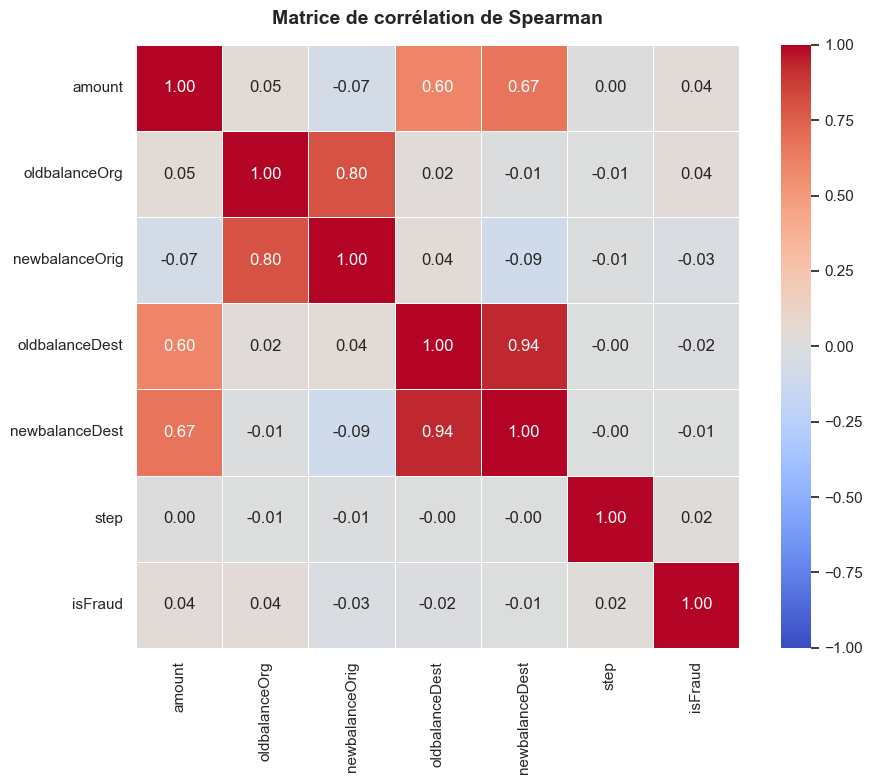

In [477]:
# Créer le graphique
fig, ax = plt.subplots(
    figsize=(10, 8)
)

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    ax=ax,
)

# Configurer le graphique
ax.set_title(
    "Matrice de corrélation de Spearman",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "33_spearman_correlation_matrix.png"
)

plt.show()

In [478]:
# Extraire le triangle supérieur
correlation_comparison = []

for index, variable_1 in enumerate(
    correlation_variables
):
    for variable_2 in correlation_variables[
        index + 1:
    ]:
        correlation_comparison.append(
            {
                "Variable 1": variable_1,
                "Variable 2": variable_2,
                "Pearson": (
                    pearson_corr.loc[
                        variable_1,
                        variable_2,
                    ]
                ),
                "Spearman": (
                    spearman_corr.loc[
                        variable_1,
                        variable_2,
                    ]
                ),
            }
        )

# Construire le tableau
correlation_comparison = pd.DataFrame(
    correlation_comparison
)

# Calculer la différence
correlation_comparison[
    "Différence absolue"
] = (
    correlation_comparison[
        "Pearson"
    ]
    - correlation_comparison[
        "Spearman"
    ]
).abs()

# Trier les résultats
correlation_comparison = (
    correlation_comparison
    .sort_values(
        "Différence absolue",
        ascending=False,
    )
)

# Afficher les principaux écarts
display(
    correlation_comparison
    .head(15)
    .round(4)
)

,Variable 1,Variable 2,Pearson,Spearman,Différence absolue
2,amount,oldbalanceDest,0.29,0.60,0.30
3,amount,newbalanceDest,0.46,0.67,0.21
6,oldbalanceOrg,newbalanceOrig,1.00,0.80,0.20
12,newbalanceOrig,newbalanceDest,0.04,-0.09,0.14
1,amount,newbalanceOrig,-0.01,-0.07,0.06
8,oldbalanceOrg,newbalanceDest,0.04,-0.01,0.05
0,amount,oldbalanceOrg,-0.00,0.05,0.05
7,oldbalanceOrg,oldbalanceDest,0.07,0.02,0.04
5,amount,isFraud,0.08,0.04,0.04
15,oldbalanceDest,newbalanceDest,0.98,0.94,0.04


In [479]:
# Extraire le triangle supérieur
correlation_comparison = []

for index, variable_1 in enumerate(
    correlation_variables
):
    for variable_2 in correlation_variables[
        index + 1:
    ]:
        correlation_comparison.append(
            {
                "Variable 1": variable_1,
                "Variable 2": variable_2,
                "Pearson": (
                    pearson_corr.loc[
                        variable_1,
                        variable_2,
                    ]
                ),
                "Spearman": (
                    spearman_corr.loc[
                        variable_1,
                        variable_2,
                    ]
                ),
            }
        )

# Construire le tableau
correlation_comparison = pd.DataFrame(
    correlation_comparison
)

# Calculer la différence
correlation_comparison[
    "Différence absolue"
] = (
    correlation_comparison[
        "Pearson"
    ]
    - correlation_comparison[
        "Spearman"
    ]
).abs()

# Trier les résultats
correlation_comparison = (
    correlation_comparison
    .sort_values(
        "Différence absolue",
        ascending=False,
    )
)

# Afficher les principaux écarts
display(
    correlation_comparison
    .head(15)
    .round(4)
)

,Variable 1,Variable 2,Pearson,Spearman,Différence absolue
2,amount,oldbalanceDest,0.29,0.60,0.30
3,amount,newbalanceDest,0.46,0.67,0.21
6,oldbalanceOrg,newbalanceOrig,1.00,0.80,0.20
12,newbalanceOrig,newbalanceDest,0.04,-0.09,0.14
1,amount,newbalanceOrig,-0.01,-0.07,0.06
8,oldbalanceOrg,newbalanceDest,0.04,-0.01,0.05
0,amount,oldbalanceOrg,-0.00,0.05,0.05
7,oldbalanceOrg,oldbalanceDest,0.07,0.02,0.04
5,amount,isFraud,0.08,0.04,0.04
15,oldbalanceDest,newbalanceDest,0.98,0.94,0.04


In [480]:
# Définir les variables de solde
balance_variables = [
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
]

# Extraire les corrélations
balance_corr = (
    pearson_corr
    .loc[
        balance_variables,
        balance_variables,
    ]
)

# Afficher le tableau
display(
    balance_corr.round(4)
)

,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest
oldbalanceOrg,1.00,1.00,0.07,0.04
newbalanceOrig,1.00,1.00,0.07,0.04
oldbalanceDest,0.07,0.07,1.00,0.98
newbalanceDest,0.04,0.04,0.98,1.00


Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\34_balance_correlation_matrix.png


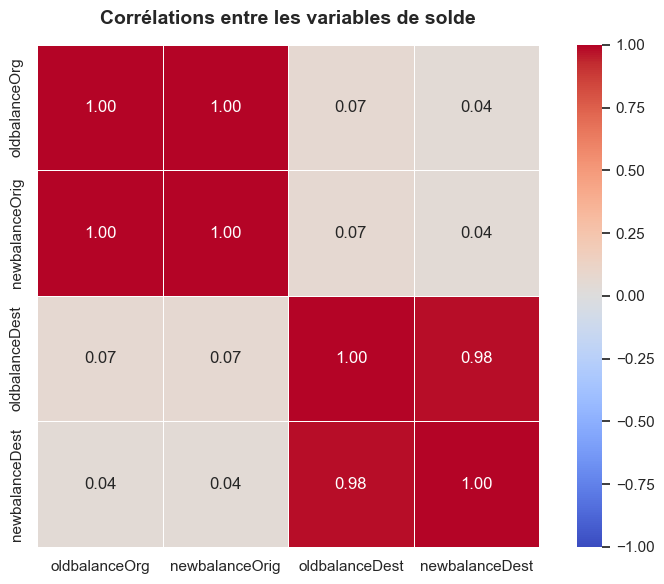

In [481]:
# Créer le graphique
fig, ax = plt.subplots(
    figsize=(8, 6)
)

sns.heatmap(
    balance_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    ax=ax,
)

# Configurer le graphique
ax.set_title(
    "Corrélations entre les variables de solde",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "34_balance_correlation_matrix.png"
)

plt.show()

In [482]:
# Enregistrer Pearson
pearson_corr.to_csv(
    tables_dir
    / "pearson_correlation_matrix.csv",
    encoding="utf-8-sig",
)

# Enregistrer Spearman
spearman_corr.to_csv(
    tables_dir
    / "spearman_correlation_matrix.csv",
    encoding="utf-8-sig",
)

# Enregistrer les corrélations cible
target_correlations.to_csv(
    tables_dir
    / "target_correlations.csv",
    encoding="utf-8-sig",
)

# Enregistrer les fortes corrélations
strong_correlations.to_csv(
    tables_dir
    / "strong_feature_correlations.csv",
    index=False,
    encoding="utf-8-sig",
)

print(
    "Résultats de corrélation enregistrés."
)

Résultats de corrélation enregistrés.


## Conclusion de l'analyse des corrélations

### Observation

Les corrélations linéaires entre les variables numériques et la cible
`isFraud` sont globalement faibles.

`amount` présente la corrélation linéaire la plus élevée avec la fraude,
avec un coefficient de Pearson d'environ 0,077.

Les autres variables présentent des coefficients très proches de zéro.

À l'inverse, certaines variables financières sont fortement corrélées entre
elles.

La corrélation entre `oldbalanceOrg` et `newbalanceOrig` atteint environ
0,999, tandis que celle entre `oldbalanceDest` et `newbalanceDest` atteint
environ 0,977.

### Interprétation

La faiblesse des corrélations individuelles avec `isFraud` ne signifie pas
que les variables étudiées sont peu utiles.

Les analyses précédentes ont montré que certains comportements résultant de
la combinaison de plusieurs variables sont extrêmement discriminants.

Par exemple, la combinaison :

`amount ≈ oldbalanceOrg` et `newbalanceOrig = 0`

est très fortement associée à la fraude alors que les variables brutes qui
la composent présentent individuellement des corrélations linéaires faibles
avec la cible.

La détection de fraude apparaît donc comme un problème principalement
non linéaire et interactionnel.

### Pearson et Spearman

Les coefficients de Pearson et de Spearman mettent également en évidence
des relations de nature différente entre certaines variables.

Pearson mesure principalement les dépendances linéaires tandis que Spearman
permet de détecter des relations monotones.

Les écarts observés entre ces deux mesures indiquent que certaines relations
financières ne sont pas strictement linéaires.

### Multicolinéarité

Deux couples présentent une très forte corrélation :

- `oldbalanceOrg` et `newbalanceOrig` ;
- `oldbalanceDest` et `newbalanceDest`.

Cette redondance est cohérente puisque ces variables représentent les soldes
d'un même compte avant et après une transaction.

Elles ne seront cependant pas supprimées à ce stade.

Leur évolution constitue une information métier essentielle pour construire
des variables comme les variations de solde et les écarts comptables.

### Impact sur le Feature Engineering

L'analyse confirme l'intérêt de créer des variables décrivant les relations
entre plusieurs attributs, notamment :

- variation du solde de l'émetteur ;
- variation du solde du destinataire ;
- ratio montant / solde disponible ;
- vidage complet du compte ;
- écarts comptables ;
- interactions entre montant et type de transaction.

### Impact sur les modèles Machine Learning

Les modèles linéaires constitueront une baseline utile mais pourraient avoir
des difficultés à capturer seuls certains comportements complexes.

Les modèles non linéaires comme Random Forest, XGBoost ou LightGBM devraient
être mieux adaptés à l'apprentissage des interactions observées durant l'EDA.

La multicolinéarité devra être particulièrement surveillée pour la régression
logistique.

### Impact sur le Graph Learning

Les corrélations tabulaires ne mesurent aucune dépendance entre les comptes
du réseau.

Deux transactions ayant des caractéristiques numériques similaires peuvent
présenter des risques différents selon leur contexte relationnel et temporel.

L'exploration de la structure du graphe constitue donc une dimension
complémentaire aux analyses statistiques classiques.

### Décision retenue

- Conserver toutes les variables numériques pour le moment.
- Ne supprimer aucune variable uniquement à cause d'une forte corrélation.
- Exploiter les relations entre soldes durant le Feature Engineering.
- Utiliser les modèles linéaires comme baseline et les comparer à des modèles
  non linéaires.
- Compléter l'analyse tabulaire par l'étude explicite du graphe transactionnel.

# 10. Analyse orientée Graph Learning

## Pourquoi représenter les transactions sous forme de graphe ?

Jusqu'à présent, chaque transaction a principalement été analysée comme une
observation indépendante.

Cependant, une transaction Mobile Money représente naturellement une relation
entre deux comptes :

`Compte source → Transaction → Compte destination`

Cette structure peut être représentée par un graphe orienté dans lequel :

- les comptes `nameOrig` et `nameDest` constituent les nœuds ;
- chaque transaction constitue une arête orientée ;
- `amount`, `type`, `step` et les soldes constituent des attributs d'arêtes ;
- `isFraud` constitue le label associé à l'arête.

L'objectif de cette section n'est pas encore de construire le graphe final
destiné aux modèles GNN.

Il s'agit de réaliser une première exploration structurelle afin de répondre
aux questions suivantes :

1. Quelle est la taille du réseau transactionnel ?
2. Le graphe est-il dense ou sparse ?
3. Certains comptes jouent-ils un rôle de hub ?
4. Les comptes peuvent-ils être simultanément émetteurs et destinataires ?
5. Quelle structure présentent les relations frauduleuses ?
6. Comment le graphe évolue-t-il dans le temps ?
7. Quelle formulation Graph Learning semble la plus adaptée au problème ?

Cette analyse servira directement à préparer le Notebook
`05_graph_construction.ipynb`.

In [483]:
# Importer NetworkX
import networkx as nx

# Afficher la version
print(
    f"Version NetworkX : {nx.__version__}"
)

Version NetworkX : 3.6.1


## Définition du graphe

Nous considérons un graphe transactionnel orienté :

\[
G = (V, E)
\]

où :

- \(V\) représente l'ensemble des comptes ;
- \(E\) représente l'ensemble des transactions.

Une transaction \(e_{ij}^{t}\) relie un compte source \(i\) à un compte
destination \(j\) au step temporel \(t\).

Chaque arête peut être décrite par :

- montant ;
- type de transaction ;
- timestamp ;
- soldes avant et après transaction ;
- indicateurs comportementaux ;
- label de fraude.

La cible appartenant à la transaction, la tâche principale sera formulée
comme une **classification d'arêtes**, et plus précisément comme une
classification temporelle d'arêtes pour les futurs modèles dynamiques.

In [484]:
# Extraire les identifiants uniques
origin_nodes = pd.Index(
    df["nameOrig"].unique()
)

destination_nodes = pd.Index(
    df["nameDest"].unique()
)

# Calculer les comptes présents dans les deux rôles
common_nodes = origin_nodes.intersection(
    destination_nodes
)

# Calculer les statistiques
n_origin_nodes = len(
    origin_nodes
)

n_destination_nodes = len(
    destination_nodes
)

n_common_nodes = len(
    common_nodes
)

n_total_nodes = (
    n_origin_nodes
    + n_destination_nodes
    - n_common_nodes
)

# Afficher les résultats
print(
    f"Comptes sources uniques : "
    f"{n_origin_nodes:,}"
)

print(
    f"Comptes destinations uniques : "
    f"{n_destination_nodes:,}"
)

print(
    f"Comptes apparaissant dans les deux rôles : "
    f"{n_common_nodes:,}"
)

print(
    f"Nombre total de nœuds : "
    f"{n_total_nodes:,}"
)

Comptes sources uniques : 6,353,307
Comptes destinations uniques : 2,722,362
Comptes apparaissant dans les deux rôles : 1,769
Nombre total de nœuds : 9,073,900


In [485]:
# Calculer le nombre de transactions
n_transaction_edges = len(
    df
)

# Identifier les paires répétées
duplicate_edge_mask = (
    df[
        [
            "nameOrig",
            "nameDest",
        ]
    ]
    .duplicated()
)

# Compter les répétitions
n_repeated_edges = int(
    duplicate_edge_mask.sum()
)

# Calculer le nombre de relations uniques
n_unique_edges = (
    n_transaction_edges
    - n_repeated_edges
)

# Identifier les boucles
self_loop_mask = (
    df["nameOrig"]
    == df["nameDest"]
)

n_self_loops = int(
    self_loop_mask.sum()
)

# Afficher les résultats
print(
    f"Transactions / arêtes temporelles : "
    f"{n_transaction_edges:,}"
)

print(
    f"Relations source-destination uniques : "
    f"{n_unique_edges:,}"
)

print(
    f"Transactions répétant une paire existante : "
    f"{n_repeated_edges:,}"
)

print(
    f"Boucles source = destination : "
    f"{n_self_loops:,}"
)

Transactions / arêtes temporelles : 6,362,620
Relations source-destination uniques : 6,362,620
Transactions répétant une paire existante : 0
Boucles source = destination : 0


In [486]:
# Calculer le degré entrant moyen
average_in_degree = (
    n_unique_edges
    / n_total_nodes
)

# Calculer le degré sortant moyen
average_out_degree = (
    n_unique_edges
    / n_total_nodes
)

# Calculer le degré total moyen
average_total_degree = (
    2
    * n_unique_edges
    / n_total_nodes
)

# Calculer la densité
if n_total_nodes > 1:
    graph_density = (
        n_unique_edges
        / (
            n_total_nodes
            * (n_total_nodes - 1)
        )
    )
else:
    graph_density = np.nan

# Calculer le taux de répétition
repeated_edge_rate = (
    100
    * n_repeated_edges
    / n_transaction_edges
)

# Créer le tableau
graph_global_summary = pd.DataFrame(
    {
        "Indicateur": [
            "Nœuds",
            "Arêtes transactionnelles",
            "Relations uniques",
            "Degré entrant moyen",
            "Degré sortant moyen",
            "Degré total moyen",
            "Densité",
            "Arêtes répétées (%)",
            "Boucles",
        ],
        "Valeur": [
            n_total_nodes,
            n_transaction_edges,
            n_unique_edges,
            average_in_degree,
            average_out_degree,
            average_total_degree,
            graph_density,
            repeated_edge_rate,
            n_self_loops,
        ],
    }
)

# Afficher le tableau
display(
    graph_global_summary
)

,Indicateur,Valeur
0,Nœuds,"9,073,900.00"
1,Arêtes transactionnelles,"6,362,620.00"
2,Relations uniques,"6,362,620.00"
3,Degré entrant moyen,0.70
4,Degré sortant moyen,0.70
5,Degré total moyen,1.40
6,Densité,0.00
7,Arêtes répétées (%),0.00
8,Boucles,0.00


In [487]:
# Calculer le degré sortant
out_degree = (
    df["nameOrig"]
    .value_counts()
    .rename("Degré sortant")
)

# Calculer le degré entrant
in_degree = (
    df["nameDest"]
    .value_counts()
    .rename("Degré entrant")
)

# Créer le résumé
degree_summary = pd.DataFrame(
    {
        "Indicateur": [
            "Degré sortant médian",
            "Degré sortant P95",
            "Degré sortant P99",
            "Degré sortant maximum",
            "Degré entrant médian",
            "Degré entrant P95",
            "Degré entrant P99",
            "Degré entrant maximum",
        ],
        "Valeur": [
            out_degree.median(),
            out_degree.quantile(0.95),
            out_degree.quantile(0.99),
            out_degree.max(),
            in_degree.median(),
            in_degree.quantile(0.95),
            in_degree.quantile(0.99),
            in_degree.max(),
        ],
    }
)

# Afficher le tableau
display(
    degree_summary
)

,Indicateur,Valeur
0,Degré sortant médian,1.00
1,Degré sortant P95,1.00
2,Degré sortant P99,1.00
3,Degré sortant maximum,3.00
4,Degré entrant médian,1.00
5,Degré entrant P95,10.00
6,Degré entrant P99,25.00
7,Degré entrant maximum,113.00


In [488]:
# Sélectionner les principaux candidats
top_out_candidates = (
    out_degree
    .nlargest(200)
    .index
)

top_in_candidates = (
    in_degree
    .nlargest(200)
    .index
)

# Combiner les candidats
candidate_nodes = (
    pd.Index(top_out_candidates)
    .union(
        pd.Index(top_in_candidates)
    )
)

# Construire la table
top_degree_nodes = pd.DataFrame(
    index=candidate_nodes
)

# Ajouter les degrés
top_degree_nodes[
    "Degré sortant"
] = (
    out_degree
    .reindex(candidate_nodes)
    .fillna(0)
)

top_degree_nodes[
    "Degré entrant"
] = (
    in_degree
    .reindex(candidate_nodes)
    .fillna(0)
)

# Calculer le degré total
top_degree_nodes[
    "Degré total"
] = (
    top_degree_nodes[
        "Degré sortant"
    ]
    + top_degree_nodes[
        "Degré entrant"
    ]
)

# Trier les résultats
top_degree_nodes = (
    top_degree_nodes
    .sort_values(
        "Degré total",
        ascending=False,
    )
    .head(20)
    .reset_index()
)

# Renommer le compte
top_degree_nodes = (
    top_degree_nodes
    .rename(
        columns={
            "index": "Compte"
        }
    )
)

# Afficher le tableau
display(
    top_degree_nodes
)

,Compte,Degré sortant,Degré entrant,Degré total
0,C1286084959,0.00,113.00,113.00
1,C985934102,0.00,109.00,109.00
2,C665576141,0.00,105.00,105.00
3,C2083562754,0.00,102.00,102.00
4,C1590550415,0.00,101.00,101.00
5,C248609774,0.00,101.00,101.00
6,C451111351,0.00,99.00,99.00
7,C1789550256,0.00,99.00,99.00
8,C1360767589,0.00,98.00,98.00
9,C1023714065,0.00,97.00,97.00


Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\35_top_connected_nodes.png


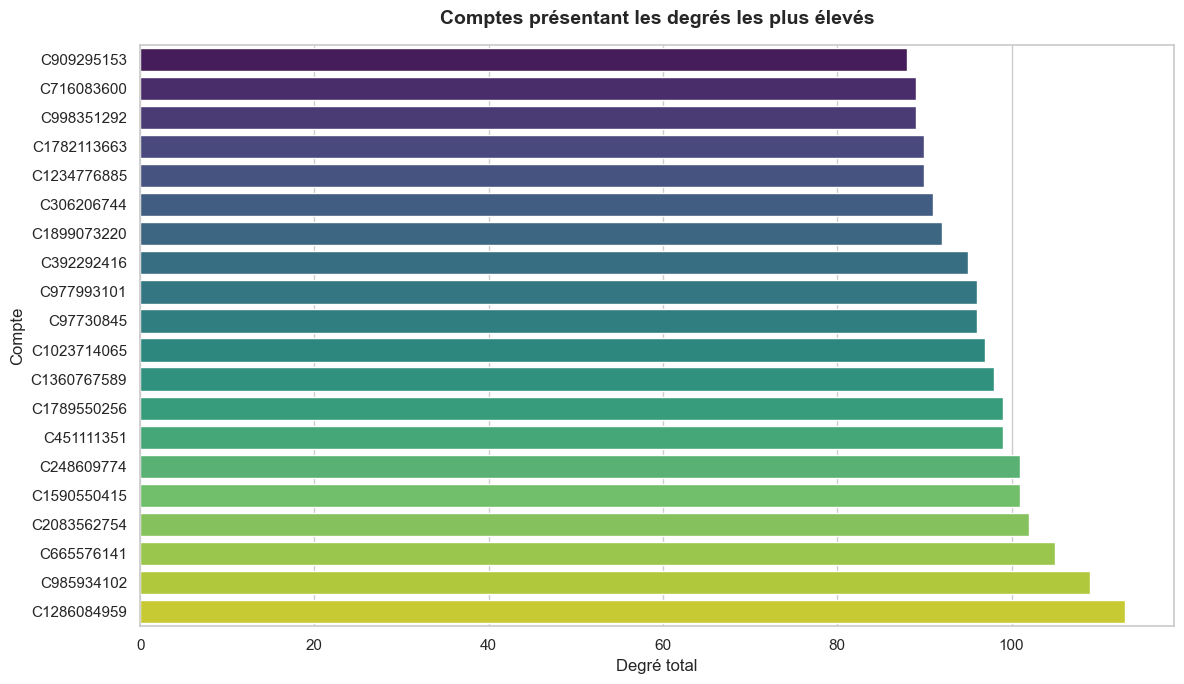

In [489]:
# Préparer les données
top_degree_plot = (
    top_degree_nodes
    .sort_values(
        "Degré total",
        ascending=True,
    )
)

# Créer le graphique
fig, ax = plt.subplots(
    figsize=(12, 7)
)

sns.barplot(
    data=top_degree_plot,
    y="Compte",
    x="Degré total",
    hue="Compte",
    palette="viridis",
    legend=False,
    ax=ax,
)

# Configurer le graphique
ax.set_title(
    "Comptes présentant les degrés les plus élevés",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel(
    "Degré total"
)

ax.set_ylabel(
    "Compte"
)

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "35_top_connected_nodes.png"
)

plt.show()

In [490]:
# Sélectionner les fraudes
fraud_edges = df.loc[
    df["isFraud"] == 1,
    [
        "nameOrig",
        "nameDest",
        "amount",
        "type",
        "step",
        "isFraud",
    ],
].copy()

# Extraire les nœuds
fraud_source_nodes = pd.Index(
    fraud_edges[
        "nameOrig"
    ].unique()
)

fraud_destination_nodes = pd.Index(
    fraud_edges[
        "nameDest"
    ].unique()
)

# Identifier les nœuds présents dans les deux rôles
fraud_role_overlap = (
    fraud_source_nodes
    .intersection(
        fraud_destination_nodes
    )
)

# Afficher les résultats
print(
    f"Sources frauduleuses uniques : "
    f"{len(fraud_source_nodes):,}"
)

print(
    f"Destinations frauduleuses uniques : "
    f"{len(fraud_destination_nodes):,}"
)

print(
    f"Nœuds frauduleux présents dans les deux rôles : "
    f"{len(fraud_role_overlap):,}"
)

Sources frauduleuses uniques : 8,213
Destinations frauduleuses uniques : 8,169
Nœuds frauduleux présents dans les deux rôles : 0


In [491]:
# Créer les données temporelles
snapshot_data = df[
    [
        "step",
        "nameOrig",
        "nameDest",
        "amount",
        "isFraud",
    ]
].copy()

# Créer les fenêtres
snapshot_data[
    "Fenêtre 24 steps"
] = (
    (
        snapshot_data["step"]
        - 1
    )
    // 24
)

# Calculer les statistiques
snapshot_summary = (
    snapshot_data
    .groupby(
        "Fenêtre 24 steps",
        observed=True,
    )
    .agg(
        Transactions=(
            "isFraud",
            "size",
        ),
        Fraudes=(
            "isFraud",
            "sum",
        ),
        Sources_actives=(
            "nameOrig",
            "nunique",
        ),
        Destinations_actives=(
            "nameDest",
            "nunique",
        ),
        Volume_total=(
            "amount",
            "sum",
        ),
    )
    .reset_index()
)

# Calculer le taux de fraude
snapshot_summary[
    "Taux de fraude (%)"
] = (
    100
    * snapshot_summary["Fraudes"]
    / snapshot_summary["Transactions"]
)

# Afficher le tableau
display(
    snapshot_summary
)

,Fenêtre 24 steps,Transactions,Fraudes,Sources_actives,Destinations_actives,Volume_total,Taux de fraude (%)
0,0,574255,271,574184,249521,"92,131,865,625.65",0.05
1,1,455238,309,455188,240371,"71,238,642,397.16",0.07
2,2,1070,310,1070,1069,"447,084,472.63",28.97
3,3,28240,262,28240,27196,"3,830,547,360.59",0.93
4,4,9789,252,9789,9674,"1,325,133,839.05",2.57
5,5,441005,228,440962,263701,"73,409,986,368.34",0.05
6,6,420583,272,420548,278057,"67,070,777,584.77",0.06
7,7,449637,278,449589,311072,"70,030,598,500.48",0.06
8,8,417919,255,417883,311081,"58,067,765,398.42",0.06
9,9,392945,282,392909,302912,"65,190,352,177.02",0.07


Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\36_active_nodes_over_time.png


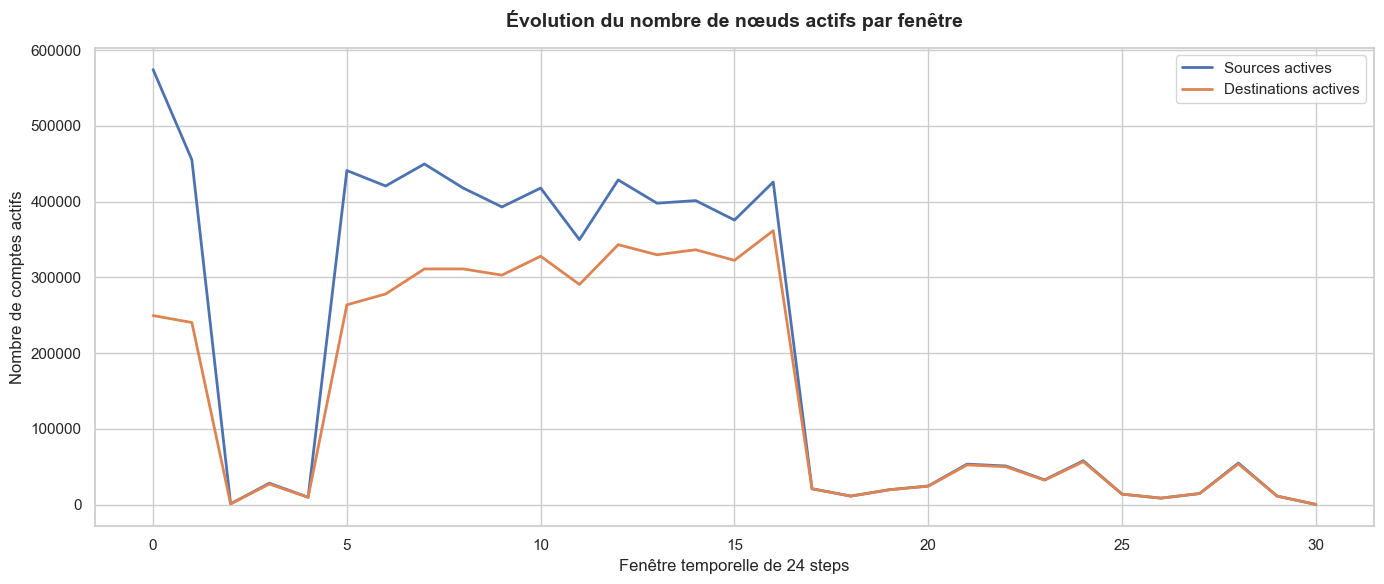

In [492]:
# Créer le graphique
fig, ax = plt.subplots(
    figsize=(14, 6)
)

# Tracer les sources
ax.plot(
    snapshot_summary[
        "Fenêtre 24 steps"
    ],
    snapshot_summary[
        "Sources_actives"
    ],
    linewidth=2,
    label="Sources actives",
)

# Tracer les destinations
ax.plot(
    snapshot_summary[
        "Fenêtre 24 steps"
    ],
    snapshot_summary[
        "Destinations_actives"
    ],
    linewidth=2,
    label="Destinations actives",
)

# Configurer le graphique
ax.set_title(
    "Évolution du nombre de nœuds actifs par fenêtre",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel(
    "Fenêtre temporelle de 24 steps"
)

ax.set_ylabel(
    "Nombre de comptes actifs"
)

ax.legend()

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "36_active_nodes_over_time.png"
)

plt.show()

In [493]:
# Compter les fraudes reçues
fraud_destination_degree = (
    fraud_edges[
        "nameDest"
    ]
    .value_counts()
)

# Sélectionner les destinations prioritaires
focus_destinations = (
    fraud_destination_degree
    .head(10)
    .index
    .tolist()
)

# Afficher les comptes sélectionnés
print(
    "Destinations sélectionnées :"
)

for node in focus_destinations:
    print(
        f"- {node}"
    )

Destinations sélectionnées :
- C410033330
- C803116137
- C904300960
- C1013511446
- C2020337583
- C200064275
- C185805228
- C52390890
- C935310781
- C1827219533


In [494]:
# Identifier les transactions du voisinage
focus_mask = (
    df["nameDest"].isin(
        focus_destinations
    )
    | df["nameOrig"].isin(
        focus_destinations
    )
)

# Extraire les arêtes
focus_edges = df.loc[
    focus_mask,
    [
        "nameOrig",
        "nameDest",
        "amount",
        "type",
        "step",
        "isFraud",
    ],
].copy()

# Afficher les informations
print(
    f"Transactions du sous-graphe : "
    f"{len(focus_edges):,}"
)

print(
    f"Fraudes du sous-graphe : "
    f"{focus_edges['isFraud'].sum():,}"
)

Transactions du sous-graphe : 373
Fraudes du sous-graphe : 20


In [495]:
# Définir le nombre maximum d'arêtes
max_visual_edges = 150

# Sélectionner toutes les fraudes
focus_fraud_edges = (
    focus_edges
    .loc[
        focus_edges["isFraud"] == 1
    ]
)

# Sélectionner les autres transactions
focus_legitimate_edges = (
    focus_edges
    .loc[
        focus_edges["isFraud"] == 0
    ]
)

# Calculer le nombre restant
remaining_edges = max(
    0,
    max_visual_edges
    - len(focus_fraud_edges)
)

# Conserver les légitimes les plus importantes
focus_legitimate_edges = (
    focus_legitimate_edges
    .nlargest(
        min(
            remaining_edges,
            len(focus_legitimate_edges),
        ),
        "amount",
    )
)

# Combiner les données
focus_visual_edges = pd.concat(
    [
        focus_legitimate_edges,
        focus_fraud_edges,
    ],
    ignore_index=True,
)

print(
    f"Arêtes conservées pour la visualisation : "
    f"{len(focus_visual_edges):,}"
)

Arêtes conservées pour la visualisation : 150


In [496]:
# Créer le graphe
G_focus = nx.MultiDiGraph()

# Ajouter les transactions
for row in focus_visual_edges.itertuples(
    index=False
):
    G_focus.add_edge(
        row.nameOrig,
        row.nameDest,
        amount=row.amount,
        type=row.type,
        step=row.step,
        isFraud=row.isFraud,
    )

# Afficher les statistiques
print(
    f"Nœuds du sous-graphe : "
    f"{G_focus.number_of_nodes():,}"
)

print(
    f"Arêtes du sous-graphe : "
    f"{G_focus.number_of_edges():,}"
)

print(
    f"Composantes faibles : "
    f"{nx.number_weakly_connected_components(G_focus):,}"
)

Nœuds du sous-graphe : 160
Arêtes du sous-graphe : 150
Composantes faibles : 10


In [497]:
# Identifier les nœuds frauduleux
fraud_nodes_focus = set()

for source, destination, data in G_focus.edges(
    data=True
):
    if data["isFraud"] == 1:
        fraud_nodes_focus.add(
            source
        )
        fraud_nodes_focus.add(
            destination
        )

# Calculer les degrés
focus_degrees = dict(
    G_focus.degree()
)

# Définir la taille des nœuds
node_sizes = [
    120
    + 35
    * focus_degrees[node]
    for node in G_focus.nodes()
]

# Définir les couleurs
node_colors = [
    COLORS["fraud"]
    if node in fraud_nodes_focus
    else COLORS["primary"]
    for node in G_focus.nodes()
]

# Définir les couleurs des arêtes
edge_colors = [
    COLORS["fraud"]
    if data["isFraud"] == 1
    else COLORS["neutral"]
    for _, _, data in G_focus.edges(
        data=True
    )
]

Figure enregistrée : c:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\reports\figures\eda\37_fraud_local_subgraph.png


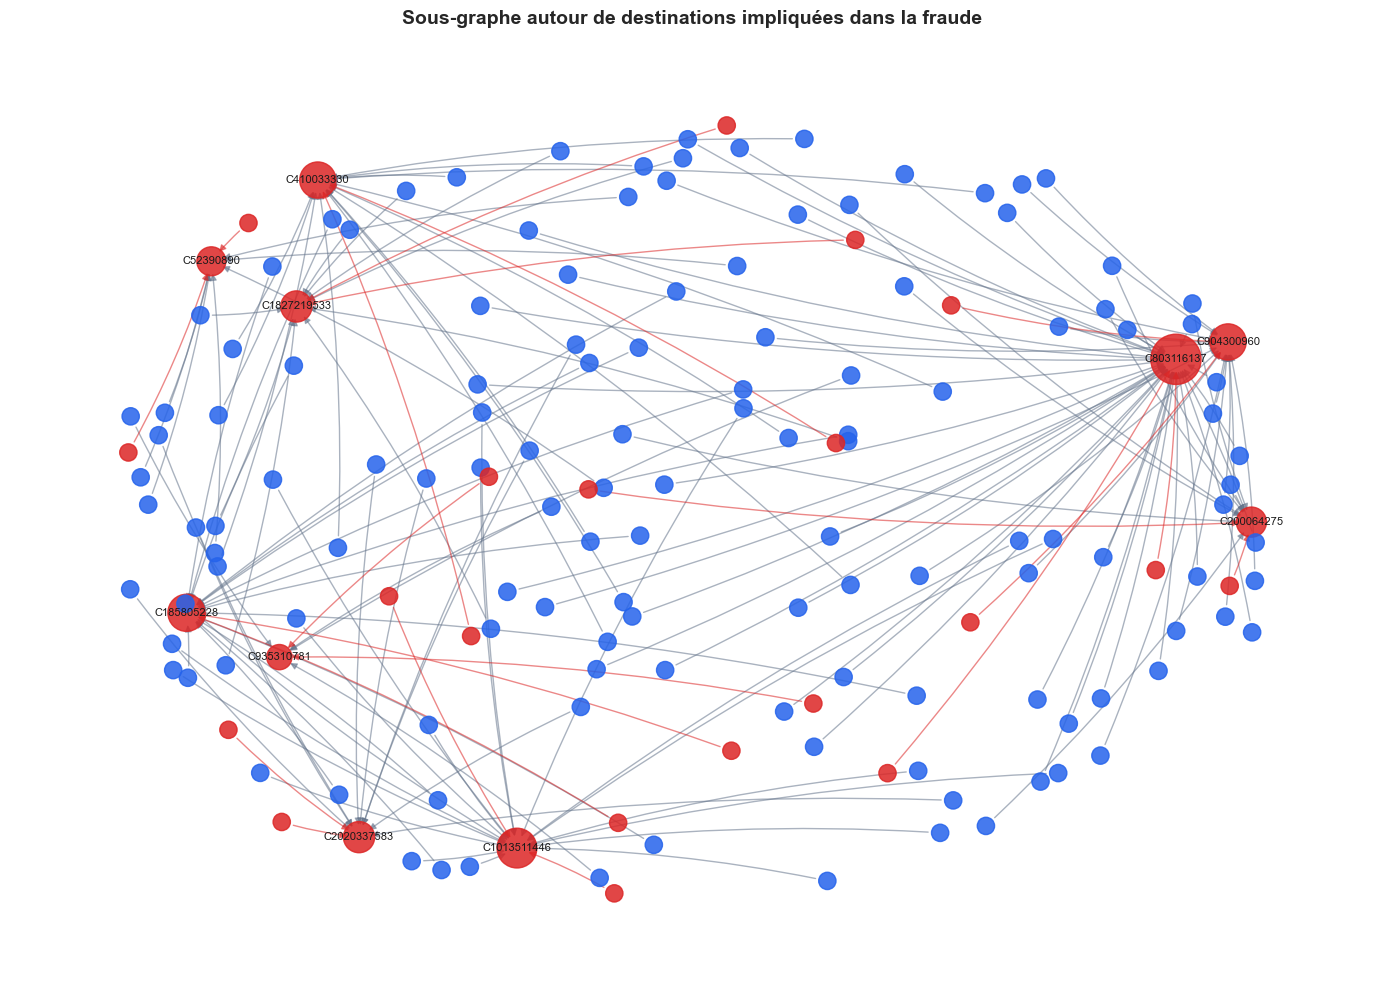

In [498]:
# Calculer les positions
pos = nx.spring_layout(
    G_focus,
    seed=RANDOM_STATE,
    k=0.6,
)

# Créer le graphique
fig, ax = plt.subplots(
    figsize=(14, 10)
)

# Dessiner les nœuds
nx.draw_networkx_nodes(
    G_focus,
    pos,
    node_size=node_sizes,
    node_color=node_colors,
    alpha=0.85,
    ax=ax,
)

# Dessiner les arêtes
nx.draw_networkx_edges(
    G_focus,
    pos,
    edge_color=edge_colors,
    alpha=0.55,
    arrows=True,
    arrowsize=10,
    connectionstyle="arc3,rad=0.05",
    ax=ax,
)

# Ajouter les labels aux destinations importantes
focus_labels = {
    node: node
    for node in focus_destinations
    if node in G_focus
}

nx.draw_networkx_labels(
    G_focus,
    pos,
    labels=focus_labels,
    font_size=8,
    ax=ax,
)

# Ajouter le titre
ax.set_title(
    "Sous-graphe autour de destinations impliquées dans la fraude",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

# Masquer les axes
ax.axis(
    "off"
)

plt.tight_layout()

# Enregistrer le graphique
save_figure(
    "37_fraud_local_subgraph.png"
)

plt.show()

In [499]:
# Calculer les statistiques
focus_graph_summary = pd.DataFrame(
    {
        "Indicateur": [
            "Nœuds",
            "Arêtes",
            "Fraudes",
            "Composantes faibles",
            "Degré moyen",
            "Degré maximum",
        ],
        "Valeur": [
            G_focus.number_of_nodes(),
            G_focus.number_of_edges(),
            focus_visual_edges[
                "isFraud"
            ].sum(),
            nx.number_weakly_connected_components(
                G_focus
            ),
            (
                sum(
                    dict(
                        G_focus.degree()
                    ).values()
                )
                / G_focus.number_of_nodes()
            ),
            max(
                dict(
                    G_focus.degree()
                ).values()
            ),
        ],
    }
)

# Afficher le tableau
display(
    focus_graph_summary
)

,Indicateur,Valeur
0,Nœuds,160.00
1,Arêtes,150.00
2,Fraudes,20.00
3,Composantes faibles,10.00
4,Degré moyen,1.88
5,Degré maximum,34.00


## Première définition de la représentation Graph Learning

Les résultats précédents permettent de proposer la représentation suivante.

### Nœuds

Chaque identifiant de compte devient un nœud :

- `nameOrig` ;
- `nameDest`.

Un même identifiant présent dans les deux colonnes correspond au même nœud.

### Arêtes

Chaque transaction correspond à une arête orientée :

`nameOrig → nameDest`

Plusieurs transactions entre les mêmes comptes peuvent être conservées sous
forme d'événements distincts dans la représentation temporelle.

### Attributs d'arête potentiels

Les attributs de transaction pourront inclure :

- montant ;
- type ;
- timestamp ;
- soldes avant et après transaction ;
- variation des soldes ;
- ratio montant / solde initial ;
- indicateurs de vidage du compte ;
- écarts comptables.

### Attributs de nœud potentiels

Les attributs des comptes pourront être construits à partir de leur historique :

- degré entrant ;
- degré sortant ;
- nombre de voisins uniques ;
- volume reçu ;
- volume envoyé ;
- fréquence d'activité ;
- nombre d'interactions récentes ;
- temps depuis la dernière transaction ;
- statistiques des montants entrants et sortants.

Ces valeurs devront être calculées uniquement à partir des événements antérieurs
à la transaction prédite.

### Label

Le label `isFraud` appartient à la transaction.

Le problème sera donc formulé principalement comme une :

**classification d'arêtes temporelles**.

## Pourquoi utiliser le Graph Learning ?

L'EDA montre que certaines informations utiles à la détection de fraude ne sont
pas contenues uniquement dans les attributs individuels des transactions.

La représentation en graphe permet d'intégrer le contexte relationnel d'une
transaction.

Un modèle peut ainsi prendre en compte :

- le comportement du compte source ;
- le comportement du compte destination ;
- leurs voisins respectifs ;
- les transactions précédentes ;
- la fréquence des interactions ;
- les changements du voisinage dans le temps.

Cependant, PaySim présente également plusieurs contraintes importantes.

Les comptes sources sont très peu récurrents et les relations frauduleuses sont
rarement répétées. Les destinations frauduleuses ne correspondent pas
nécessairement aux nœuds les plus connectés.

Le GNN ne devra donc pas être justifié uniquement comme un moyen de détecter
des communautés denses de fraudeurs.

Son intérêt résidera davantage dans l'apprentissage conjoint :

**structure + attributs transactionnels + historique temporel**.

Cette observation favorise les approches inductives et temporelles capables
de généraliser à des comptes peu observés ou nouveaux.

## Modèles envisagés

### GNN statiques

Une première baseline Graph Learning pourra utiliser un graphe statique avec :

- GraphSAGE ;
- GAT ;
- éventuellement GCN comme baseline simple.

GraphSAGE est particulièrement intéressant en raison de son caractère inductif
et de sa capacité à agréger l'information du voisinage.

### Dynamic Graph Learning

La représentation finale conservera l'ordre temporel des transactions.

Chaque événement sera représenté sous la forme :

`(source, destination, timestamp, edge_features, label)`

Cette structure est compatible avec des modèles tels que :

- Temporal Graph Networks (TGN) ;
- éventuellement EvolveGCN selon la représentation retenue.

TGN apparaît particulièrement adapté lorsque les transactions sont traitées
comme un flux continu d'événements.

### Évaluation

Les modèles devront respecter un découpage chronologique :

`Train → Validation → Test`

Aucune information provenant du futur ne devra être utilisée pour construire
les caractéristiques des nœuds ou les voisinages historiques.

In [500]:
# Enregistrer le résumé global
graph_global_summary.to_csv(
    tables_dir
    / "graph_global_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

# Enregistrer les degrés
degree_summary.to_csv(
    tables_dir
    / "graph_degree_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

# Enregistrer les principaux nœuds
top_degree_nodes.to_csv(
    tables_dir
    / "top_connected_nodes.csv",
    index=False,
    encoding="utf-8-sig",
)

# Enregistrer les snapshots
snapshot_summary.to_csv(
    tables_dir
    / "graph_temporal_snapshots.csv",
    index=False,
    encoding="utf-8-sig",
)

# Enregistrer le sous-graphe
focus_visual_edges.to_csv(
    tables_dir
    / "fraud_local_subgraph_edges.csv",
    index=False,
    encoding="utf-8-sig",
)

print(
    "Résultats Graph Learning enregistrés."
)

Résultats Graph Learning enregistrés.


## Conclusion de l'analyse orientée Graph Learning

### Observation

La représentation du dataset PaySim sous forme de graphe conduit à un réseau
transactionnel de très grande taille.

Le graphe contient environ 9,07 millions de nœuds pour 6,36 millions de
transactions.

La densité du graphe est extrêmement faible, de l'ordre de 7,73 × 10⁻⁸,
avec un degré total moyen d'environ 1,40.

Aucune paire source-destination n'est répétée dans le dataset et aucune boucle
où la source est également la destination n'est observée.

### Structure des degrés

La distribution des degrés est fortement asymétrique entre sources et
destinations.

Le degré sortant médian, le 95e percentile et le 99e percentile sont tous
égaux à 1. Le degré sortant maximal n'est que de 3.

Les comptes sources sont donc presque toujours utilisés pour une seule
transaction.

À l'inverse, les destinations présentent davantage de récurrence.

Le degré entrant médian est de 1, mais atteint :

- 10 au 95e percentile ;
- 25 au 99e percentile ;
- 113 au maximum.

Les principaux hubs du réseau correspondent principalement à des comptes
destinataires.

### Interprétation structurelle

Le graphe PaySim est donc extrêmement sparse et présente une structure
fortement orientée.

L'information relationnelle disponible pour les comptes sources est limitée,
mais certaines destinations possèdent un voisinage entrant suffisamment riche
pour fournir un contexte relationnel supplémentaire.

Un degré élevé n'est cependant pas synonyme de fraude. Les analyses précédentes
ont montré que les destinations les plus connectées ne sont pas
systématiquement associées aux transactions frauduleuses.

### Dynamique du réseau

L'analyse par fenêtres de 24 steps montre de fortes variations de l'activité
du graphe.

Certaines fenêtres contiennent plusieurs centaines de milliers de transactions,
tandis que d'autres n'en contiennent que quelques milliers.

Le nombre de fraudes varie beaucoup moins fortement que le volume
transactionnel, ce qui explique certains taux de fraude très élevés observés
durant les périodes de faible activité.

Cette évolution importante du nombre de nœuds actifs et des interactions montre
qu'une représentation uniquement statique du réseau perd une partie de
l'information temporelle.

### Analyse du sous-graphe frauduleux

Le sous-graphe ciblé construit autour de destinations ayant reçu plusieurs
transactions frauduleuses contient :

- 160 nœuds ;
- 150 arêtes ;
- 20 transactions frauduleuses ;
- 10 composantes faiblement connexes.

Certaines destinations présentent localement une structure en étoile et
reçoivent des transactions provenant de plusieurs comptes.

Cependant, ce sous-graphe a été construit volontairement autour de destinations
impliquées dans la fraude.

Il ne constitue donc pas une preuve de l'existence de communautés frauduleuses
denses dans le graphe global.

Les nœuds signalés comme frauduleux dans la visualisation doivent être compris
comme des comptes impliqués dans au moins une transaction frauduleuse et non
nécessairement comme des fraudeurs identifiés.

### Limites structurelles de PaySim

La faible répétition des comptes sources et l'absence de relations
source-destination répétées limitent certains patterns classiques utilisés
dans la détection de fraude par graphe.

Il sera notamment difficile de s'appuyer uniquement sur :

- la récidive directe d'un compte ;
- la répétition d'une même relation ;
- l'existence de communautés fortement interconnectées.

Le Graph Learning devra donc exploiter conjointement :

- les attributs transactionnels ;
- le voisinage local ;
- l'historique des comptes ;
- la dynamique temporelle.

### Formulation du problème

La cible `isFraud` étant attachée à une transaction, le problème sera formulé
comme une classification d'arêtes.

Dans le cadre du graphe dynamique, la tâche devient une :

**classification temporelle d'arêtes**

où chaque événement peut être représenté sous la forme :

`(source, destination, timestamp, edge_features, label)`

### Impact sur le Feature Engineering

Les futures caractéristiques relationnelles pourront inclure :

- degré entrant historique ;
- degré sortant historique ;
- nombre de voisins historiques ;
- volume cumulé entrant ;
- volume cumulé sortant ;
- nombre d'interactions récentes ;
- nombre de contreparties récentes ;
- temps depuis la dernière interaction ;
- évolution récente de l'activité.

Toutes ces variables devront être calculées exclusivement à partir des
transactions précédant l'événement à prédire.

### Impact sur les modèles GNN

GraphSAGE apparaît comme une baseline statique pertinente en raison de son
caractère inductif et du grand nombre de comptes peu observés.

Les modèles temporels sont particulièrement adaptés à la structure du dataset.

Temporal Graph Networks (TGN) constitue le candidat principal pour le modèle
dynamique, car les transactions peuvent naturellement être traitées comme une
séquence d'événements temporels.

EvolveGCN pourra éventuellement être étudié comme modèle complémentaire selon
la représentation temporelle retenue.

### Contraintes d'implémentation

Le graphe complet ne sera pas construit avec NetworkX.

Avec plus de neuf millions de nœuds, une telle représentation serait trop
coûteuse en mémoire et peu adaptée à l'entraînement.

NetworkX restera utilisé uniquement pour l'exploration et la visualisation de
petits sous-graphes.

Le Notebook `05_graph_construction.ipynb` utilisera une représentation compacte
reposant sur :

- l'indexation entière des nœuds ;
- des tenseurs d'arêtes ;
- des features numériques ;
- une bibliothèque spécialisée comme PyTorch Geometric.

### Décision retenue

- Représenter les comptes comme des nœuds.
- Représenter chaque transaction comme une arête orientée et temporelle.
- Formuler le problème comme une classification temporelle d'arêtes.
- Utiliser GraphSAGE comme baseline GNN statique principale.
- Privilégier TGN pour le Dynamic Graph Learning.
- Ne pas interpréter un degré élevé comme un indicateur direct de fraude.
- Calculer toutes les features relationnelles de manière chronologique.
- Ne pas construire le graphe complet avec NetworkX.

# 11. Synthèse générale de l'EDA

Cette analyse exploratoire avait pour objectif d'identifier les principaux
comportements associés à la fraude Mobile Money dans PaySim et de préparer
les prochaines étapes du projet.

L'EDA a étudié successivement :

- le déséquilibre de la cible ;
- les caractéristiques numériques des transactions ;
- les montants ;
- la dynamique temporelle ;
- les types de transactions ;
- le comportement des comptes ;
- les patterns suspects ;
- les corrélations ;
- la structure du graphe transactionnel.

Cette dernière section synthétise les principales découvertes et transforme
les résultats de l'EDA en décisions concrètes pour :

- `03_feature_engineering.ipynb` ;
- `04_machine_learning_baseline.ipynb` ;
- `05_graph_construction.ipynb`.

In [501]:
# Calculer les statistiques principales
n_transactions = len(df)

n_frauds = int(
    df["isFraud"].sum()
)

n_legitimate = (
    n_transactions
    - n_frauds
)

fraud_rate = (
    100
    * n_frauds
    / n_transactions
)

n_sources = (
    df["nameOrig"]
    .nunique()
)

n_destinations = (
    df["nameDest"]
    .nunique()
)

# Calculer les nœuds si nécessaire
if "n_total_nodes" not in globals():
    origin_nodes = pd.Index(
        df["nameOrig"].unique()
    )

    destination_nodes = pd.Index(
        df["nameDest"].unique()
    )

    n_total_nodes = len(
        origin_nodes.union(
            destination_nodes
        )
    )

# Calculer le transfert total
if "full_balance_transfer_mask" in globals():
    full_balance_frauds = int(
        (
            full_balance_transfer_mask
            & (df["isFraud"] == 1)
        ).sum()
    )
else:
    full_balance_frauds = np.nan

# Créer le tableau
eda_key_metrics = pd.DataFrame(
    {
        "Indicateur": [
            "Transactions",
            "Transactions légitimes",
            "Fraudes",
            "Taux de fraude (%)",
            "Comptes sources uniques",
            "Comptes destinations uniques",
            "Nœuds du graphe",
            "Arêtes transactionnelles",
            "Fraudes avec transfert total",
        ],
        "Valeur": [
            n_transactions,
            n_legitimate,
            n_frauds,
            fraud_rate,
            n_sources,
            n_destinations,
            n_total_nodes,
            len(df),
            full_balance_frauds,
        ],
    }
)

# Afficher le tableau
display(
    eda_key_metrics
)

,Indicateur,Valeur
0,Transactions,"6,362,620.00"
1,Transactions légitimes,"6,354,407.00"
2,Fraudes,"8,213.00"
3,Taux de fraude (%),0.13
4,Comptes sources uniques,"6,353,307.00"
5,Comptes destinations uniques,"2,722,362.00"
6,Nœuds du graphe,"9,073,900.00"
7,Arêtes transactionnelles,"6,362,620.00"
8,Fraudes avec transfert total,"8,008.00"


## Executive Summary

### 1. Un problème de classification extrêmement déséquilibré

Le dataset contient 6 362 620 transactions dont seulement 8 213 sont
frauduleuses.

La fraude représente environ 0,129 % des observations, soit approximativement
une fraude pour 774 transactions légitimes.

L'accuracy ne pourra donc pas constituer une métrique principale
d'évaluation.

Les futures évaluations devront privilégier notamment :

- Recall ;
- Precision ;
- F1-score ;
- PR-AUC ;
- ROC-AUC ;
- matrice de confusion.

Une attention particulière sera portée au rappel de la classe fraude.

---

### 2. Les montants frauduleux sont généralement plus élevés

Les transactions frauduleuses présentent des montants nettement supérieurs
aux transactions légitimes.

Le montant médian d'une fraude est d'environ 441 000 contre environ 75 000
pour une transaction légitime.

Cependant, le montant seul ne suffit pas à détecter la fraude.

Les patterns les plus discriminants apparaissent lorsque plusieurs variables
sont combinées.

---

### 3. La fraude est concentrée sur TRANSFER et CASH_OUT

Toutes les fraudes observées dans PaySim appartiennent à deux types :

- `CASH_OUT` : 4 116 fraudes ;
- `TRANSFER` : 4 097 fraudes.

Les deux catégories représentent presque exactement la moitié des fraudes
chacune.

Cependant, `TRANSFER` présente le risque conditionnel le plus élevé avec un
taux de fraude proche de 0,769 %, contre environ 0,184 % pour `CASH_OUT`.

Aucune fraude n'est observée dans `PAYMENT`, `CASH_IN` ou `DEBIT`.

Cette structure est spécifique à PaySim et ne devra pas être considérée comme
une règle universelle de fraude Mobile Money.

---

### 4. Le vidage complet du compte est le signal le plus fort

Le comportement le plus discriminant identifié durant l'EDA est le transfert
de la totalité du solde disponible.

8 008 transactions correspondent au pattern étudié de transfert total du
solde et elles sont toutes frauduleuses dans le dataset.

Ce pattern couvre environ 97,5 % des fraudes.

De même, environ 98 % des transactions frauduleuses présentent un
`newbalanceOrig` égal à zéro.

Ces résultats montrent que PaySim contient des patterns presque déterministes
issus de son mécanisme de simulation.

Une étude d'ablation sera donc indispensable afin de déterminer dans quelle
mesure les futurs modèles dépendent de ces caractéristiques spécifiques.

---

### 5. Les relations entre variables sont plus importantes que les variables isolées

Les corrélations linéaires individuelles avec `isFraud` restent faibles.

La corrélation de Pearson la plus importante concerne `amount` et reste
inférieure à 0,10.

Pourtant, certaines interactions comme :

`amount ≈ oldbalanceOrg` et `newbalanceOrig = 0`

sont extrêmement associées à la fraude.

La détection de fraude apparaît donc comme un problème principalement
non linéaire et interactionnel.

Cette observation justifie le Feature Engineering et l'utilisation de modèles
capables de capturer des interactions complexes.

---

### 6. Une dynamique temporelle importante est présente

L'activité transactionnelle évolue fortement au cours de la simulation.

Certaines périodes contiennent plusieurs centaines de milliers de
transactions tandis que d'autres présentent une activité très faible.

Le nombre de fraudes varie moins fortement que le volume total de transactions,
ce qui produit des taux de fraude élevés durant certaines périodes de faible
activité.

Le temps devra donc être utilisé non seulement comme une variable brute, mais
également pour construire des caractéristiques historiques et séquentielles.

Le split Train / Validation / Test devra respecter l'ordre chronologique.

---

### 7. Les comptes sources sont très peu récurrents

Le dataset contient environ 6,35 millions de sources uniques pour 6,36 millions
de transactions.

Le degré sortant médian, le 95e percentile et le 99e percentile sont égaux
à 1 et le maximum n'est que de 3.

Les comptes sources possèdent donc généralement très peu d'historique.

Cela limite les features basées uniquement sur la récidive d'un même
émetteur.

---

### 8. Les destinations présentent davantage de structure relationnelle

Les comptes destinations sont davantage récurrents.

Le degré entrant atteint :

- 10 au 95e percentile ;
- 25 au 99e percentile ;
- 113 au maximum.

Les destinations offrent donc davantage de contexte relationnel que les
sources.

Cependant, les destinations frauduleuses ne correspondent pas nécessairement
aux comptes les plus connectés.

Un degré élevé ne peut donc pas être utilisé comme règle directe de fraude.

---

### 9. Les réseaux frauduleux récurrents sont rares dans PaySim

Les 8 213 fraudes sont associées à 8 213 sources différentes.

Aucun émetteur ne réalise plusieurs fraudes.

Les fraudes concernent 8 169 destinations différentes et seulement
44 destinations reçoivent plusieurs fraudes.

Aucun couple source-destination frauduleux n'est répété.

PaySim ne présente donc pas principalement des communautés de fraudeurs
fortement récurrentes.

Le Graph Learning devra exploiter le contexte local et temporel plutôt que
rechercher uniquement des réseaux d'acteurs récidivistes.

---

### 10. Le graphe est gigantesque et extrêmement sparse

La représentation transactionnelle produit environ :

- 9,07 millions de nœuds ;
- 6,36 millions d'arêtes.

La densité du réseau est de l'ordre de 7,73 × 10⁻⁸.

Le graphe complet ne devra donc pas être construit avec NetworkX pour
l'entraînement.

Une représentation optimisée reposant sur des index numériques et des tenseurs
sera utilisée.

---

### 11. La tâche Graph Learning sera une classification temporelle d'arêtes

La variable cible `isFraud` appartient à la transaction.

Le problème sera donc formulé comme :

**Temporal Edge Classification**

Chaque événement pourra être représenté sous la forme :

`(source, destination, timestamp, edge_features, label)`

Les modèles statiques serviront de baseline Graph Learning tandis que les
modèles dynamiques exploiteront explicitement la chronologie des transactions.

In [502]:
# Créer le plan de Feature Engineering
feature_plan = pd.DataFrame(
    {
        "Famille": [
            "Montant",
            "Montant",
            "Soldes",
            "Soldes",
            "Soldes",
            "Soldes",
            "Type",
            "Temps",
            "Temps",
            "Comportement",
            "Comportement",
            "Graphe",
            "Graphe",
            "Graphe",
        ],
        "Feature candidate": [
            "log_amount",
            "amount_to_oldbalance_ratio",
            "origin_balance_change",
            "destination_balance_change",
            "origin_emptied",
            "full_balance_transfer",
            "type_encoded",
            "cycle_position",
            "time_since_last_transaction",
            "recent_transaction_count",
            "recent_transaction_volume",
            "historical_in_degree",
            "historical_out_degree",
            "historical_unique_neighbors",
        ],
        "Priorité": [
            "Haute",
            "Haute",
            "Haute",
            "Haute",
            "Haute",
            "Haute",
            "Haute",
            "Moyenne",
            "Haute",
            "Haute",
            "Haute",
            "Haute",
            "Moyenne",
            "Haute",
        ],
    }
)

# Afficher le tableau
display(
    feature_plan
)


,Famille,Feature candidate,Priorité
0,Montant,log_amount,Haute
1,Montant,amount_to_oldbalance_ratio,Haute
2,Soldes,origin_balance_change,Haute
3,Soldes,destination_balance_change,Haute
4,Soldes,origin_emptied,Haute
5,Soldes,full_balance_transfer,Haute
6,Type,type_encoded,Haute
7,Temps,cycle_position,Moyenne
8,Temps,time_since_last_transaction,Haute
9,Comportement,recent_transaction_count,Haute


## Vigilance concernant les artefacts de PaySim

Plusieurs caractéristiques apparaissent presque déterministes dans le dataset,
notamment :

- montant égal au solde initial ;
- transfert complet du solde ;
- solde final de l'émetteur égal à zéro ;
- cohérence comptable de certaines fraudes ;
- restriction des fraudes à `TRANSFER` et `CASH_OUT`.

Ces comportements constituent des informations utiles pour la modélisation,
mais peuvent également refléter directement les règles utilisées pour générer
PaySim.

Deux jeux de features pourront donc être comparés :

### Modèle complet

Utilisation de toutes les features disponibles et dérivées.

### Modèle d'ablation

Exclusion de certaines features fortement dépendantes du mécanisme de
simulation :

- `amount_equals_oldbalance` ;
- `full_balance_transfer` ;
- certaines variables de cohérence comptable.

Cette comparaison permettra de déterminer si les performances reposent
principalement sur les artefacts du simulateur ou sur un ensemble plus riche
de comportements.

## Décisions pour les baselines Machine Learning

Les modèles classiques serviront de référence avant l'introduction du Graph
Learning.

Les modèles candidats comprennent notamment :

- Régression Logistique ;
- Random Forest ;
- XGBoost ou LightGBM.

### Split des données

Le dataset sera séparé chronologiquement.

Aucune séparation aléatoire principale ne sera utilisée, car elle pourrait
introduire une fuite temporelle et produire une évaluation trop optimiste.

### Déséquilibre des classes

Plusieurs stratégies pourront être étudiées uniquement sur les données
d'entraînement :

- class weights ;
- undersampling contrôlé ;
- éventuellement oversampling selon les besoins.

Le jeu de test conservera toujours la distribution naturelle de la fraude.

### Métriques principales

Les performances seront évaluées avec :

- Precision ;
- Recall ;
- F1-score ;
- PR-AUC ;
- ROC-AUC ;
- matrice de confusion.

L'accuracy ne sera utilisée qu'à titre secondaire.

## Décisions pour le Graph Learning

### Représentation

Le graphe sera orienté et temporel.

Nœuds :

`nameOrig` et `nameDest`

Arêtes :

transactions

Label :

`isFraud`

### Attributs d'arête

Les attributs pourront comprendre :

- montant ;
- type ;
- timestamp ;
- soldes ;
- ratios ;
- variations des soldes ;
- indicateurs comportementaux.

### Attributs de nœud

Les caractéristiques des comptes devront être calculées uniquement à partir
de leur historique antérieur :

- degré entrant ;
- degré sortant ;
- nombre de voisins ;
- volumes cumulés ;
- activité récente ;
- temps depuis la dernière activité.

### Modèles

La progression envisagée est :

1. GraphSAGE comme baseline GNN statique ;
2. éventuellement GAT comme comparaison ;
3. Temporal Graph Networks comme modèle dynamique principal.

### Contrainte fondamentale

Aucune information provenant d'une transaction future ne devra être utilisée
pour construire les features d'un événement antérieur.

In [503]:
# Créer la matrice de décisions
eda_decisions = pd.DataFrame(
    {
        "Prochaine étape": [
            "Feature Engineering",
            "Feature Engineering",
            "Feature Engineering",
            "Machine Learning",
            "Machine Learning",
            "Machine Learning",
            "Graph Construction",
            "Graph Construction",
            "Graph Learning",
            "Dynamic Graph Learning",
            "Évaluation",
            "Robustesse",
        ],
        "Décision": [
            "Créer des ratios et variations de soldes",
            "Créer des features temporelles historiques",
            "Créer des features comportementales et relationnelles",
            "Utiliser un split chronologique",
            "Traiter le déséquilibre uniquement sur le train",
            "Comparer modèles linéaires et non linéaires",
            "Compte = nœud, transaction = arête",
            "Indexer les comptes avec des identifiants numériques",
            "Utiliser GraphSAGE comme baseline",
            "Tester TGN comme modèle principal",
            "Prioriser PR-AUC, Recall et F1",
            "Réaliser une étude d'ablation PaySim",
        ],
    }
)

# Afficher le tableau
display(
    eda_decisions
)

,Prochaine étape,Décision
0,Feature Engineering,Créer des ratios et variations de soldes
1,Feature Engineering,Créer des features temporelles historiques
2,Feature Engineering,Créer des features comportementales et relatio...
3,Machine Learning,Utiliser un split chronologique
4,Machine Learning,Traiter le déséquilibre uniquement sur le train
5,Machine Learning,Comparer modèles linéaires et non linéaires
6,Graph Construction,"Compte = nœud, transaction = arête"
7,Graph Construction,Indexer les comptes avec des identifiants numé...
8,Graph Learning,Utiliser GraphSAGE comme baseline
9,Dynamic Graph Learning,Tester TGN comme modèle principal


## Risques et limites identifiés

### Déséquilibre extrême

La classe fraude représente seulement 0,129 % des transactions.

Les modèles risquent donc de favoriser fortement la classe majoritaire.

### Artefacts de simulation

Certains patterns semblent directement liés au mécanisme de génération de
PaySim.

Les performances devront donc être interprétées comme des performances sur
PaySim et non comme une validation directe sur un véritable réseau Mobile
Money.

### Faible récurrence des sources

Les comptes sources possèdent généralement très peu d'historique.

Cela limite certaines approches comportementales classiques basées sur la
récidive individuelle.

### Graphe extrêmement sparse

Le réseau contient environ neuf millions de nœuds pour seulement 6,36 millions
d'arêtes.

Les architectures et stratégies d'échantillonnage devront être adaptées à
cette structure.

### Risque de fuite temporelle

Les features historiques ou graphes complets peuvent accidentellement contenir
des informations provenant du futur.

Toutes les caractéristiques temporelles et relationnelles utilisées pour la
modélisation devront être calculées de manière causale.

In [504]:
# Enregistrer les indicateurs
eda_key_metrics.to_csv(
    tables_dir
    / "eda_key_metrics.csv",
    index=False,
    encoding="utf-8-sig",
)

# Enregistrer le plan de features
feature_plan.to_csv(
    tables_dir
    / "feature_engineering_plan.csv",
    index=False,
    encoding="utf-8-sig",
)

# Enregistrer les décisions
eda_decisions.to_csv(
    tables_dir
    / "eda_decisions.csv",
    index=False,
    encoding="utf-8-sig",
)

print(
    "Synthèse finale de l'EDA enregistrée."
)

Synthèse finale de l'EDA enregistrée.


# Conclusion générale du Notebook 02

L'analyse exploratoire approfondie de PaySim a permis de mettre en évidence
plusieurs caractéristiques essentielles du problème de détection de fraude.

La fraude est extrêmement rare, représentant environ 0,129 % des transactions,
et se concentre exclusivement sur les opérations `TRANSFER` et `CASH_OUT` dans
ce dataset.

Les transactions frauduleuses présentent généralement des montants plus
importants, mais les signaux les plus discriminants proviennent surtout des
relations entre le montant et les soldes du compte émetteur.

Le vidage complet du compte constitue notamment le pattern dominant de fraude
dans PaySim.

Cette observation est très informative pour la modélisation mais révèle
également une limite importante : certaines caractéristiques du dataset
semblent directement dépendre du mécanisme utilisé pour simuler les fraudes.

La dimension temporelle montre une activité transactionnelle fortement
variable et justifie l'utilisation d'un split chronologique ainsi que la
construction de caractéristiques historiques.

L'analyse comportementale révèle une très faible récurrence des comptes
sources, tandis que certaines destinations concentrent davantage
d'interactions.

La représentation en graphe produit un réseau extrêmement sparse d'environ
9,07 millions de nœuds et 6,36 millions d'arêtes.

Les relations frauduleuses sont rarement répétées et ne forment pas
nécessairement des communautés denses.

L'intérêt du Graph Learning résidera donc moins dans la simple détection de
hubs frauduleux que dans l'exploitation conjointe :

**des attributs transactionnels, du contexte relationnel et de la dynamique
temporelle.**

La tâche Graph Learning sera ainsi formulée comme une classification temporelle
d'arêtes.

Les résultats obtenus permettent désormais de passer à l'étape suivante du
projet :

# `03_feature_engineering.ipynb`

Ce notebook transformera les insights découverts durant l'EDA en variables
exploitables pour les modèles Machine Learning et Graph Learning.